In [ ]:
import marimo as mo

mo.md("""
# Destilación de SAM 3.1 — comparación de cinco estudiantes

**Estado inicial: preparada; todavía no hay estudiantes entrenados ni un ganador.**
Esta libreta se limita a segmentar el transistor. Usa el dataset del repo,
SAM 3.1 como profesor, MLflow y Nsight Systems + NVTX en Windows.

**Candidatos:** YOLO26n-seg, YOLO26s-seg, YOLO26m-seg,
EfficientViT-SAM-L0 y EfficientViT-SAM-L1.

El profesor genera pseudomáscaras; el estudiante aprende imagen → máscara.
Imitar al profesor no demuestra exactitud frente a anotaciones humanas.
Las máscaras MVTec de defectos no son máscaras de la silueta del transistor.

**Metas de diseño:** 20 ms inicial, 10 ms deseable, 5 ms ideal.
No son resultados medidos. Se separan red GPU, segmentación completa e I/O.
1000/latencia es FPS teórico de esa etapa, no throughput de la cámara.

Al abrir NO se descargan pesos, generan etiquetas ni entrenan modelos.
Cada paso requiere su botón. Los trabajos largos corren uno a la vez,
con métricas por época y progreso consultable sin bloquear el MCP.
""")

# Destilación de SAM 3.1 — comparación de cinco estudiantes

**Estado inicial: preparada; todavía no hay estudiantes entrenados ni un ganador.**
Esta libreta se limita a segmentar el transistor. Usa el dataset del repo,
SAM 3.1 como profesor, MLflow y Nsight Systems + NVTX en Windows.

**Candidatos:** YOLO26n-seg, YOLO26s-seg, YOLO26m-seg,
EfficientViT-SAM-L0 y EfficientViT-SAM-L1.

El profesor genera pseudomáscaras; el estudiante aprende imagen → máscara.
Imitar al profesor no demuestra exactitud frente a anotaciones humanas.
Las máscaras MVTec de defectos no son máscaras de la silueta del transistor.

**Metas de diseño:** 20 ms inicial, 10 ms deseable, 5 ms ideal.
No son resultados medidos. Se separan red GPU, segmentación completa e I/O.
1000/latencia es FPS teórico de esa etapa, no throughput de la cámara.

Al abrir NO se descargan pesos, generan etiquetas ni entrenan modelos.
Cada paso requiere su botón. Los trabajos largos corren uno a la vez,
con métricas por época y progreso consultable sin bloquear el MCP.

In [ ]:
import concurrent.futures
import contextlib
import gc
import hashlib
import importlib.util
import json
import math
import os
import platform
import shutil
import subprocess
import sys
import time
import traceback
from datetime import datetime, timezone
from pathlib import Path

import mlflow
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold, StratifiedShuffleSplit

2026/11/11 00:13:00 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\marti\Documents\BetterClasificator\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


In [ ]:
# Publicaciones externas: contexto, nunca se mezclan con las mediciones locales.
ds_specs = {
    "yolo26n-seg": {"family": "yolo", "side": 640, "published_ms": 2.1},
    "yolo26s-seg": {"family": "yolo", "side": 640, "published_ms": 3.3},
    "yolo26m-seg": {"family": "yolo", "side": 640, "published_ms": 6.7},
    "efficientvit-sam-l0": {"family": "efficientvit", "side": 512, "published_ms": 8.2},
    "efficientvit-sam-l1": {"family": "efficientvit", "side": 512, "published_ms": 10.2},
}
ds_published = pd.DataFrame([
    {"candidate": name, "resolution": spec["side"], "published_ms": spec["published_ms"],
     "hardware": "T4 / TensorRT10" if spec["family"] == "yolo" else "AGX Orin / TensorRT FP16",
     "measured_here": False}
    for name, spec in ds_specs.items()
])

In [ ]:
mo.vstack([
    mo.md("""
    ## Protocolo y condiciones de comparación

    1. Reutilizar el test congelado de prod_sam31/fusion.npz; crear validación
       exclusivamente dentro del train original. Respetar grupos si existen.
    2. Generar pseudomáscaras SOLO de train/val con el checkpoint SAM 3.1 local.
       Revisar visualmente las máscaras antes de entrenar.
    3. Entrenar los cinco estudiantes con la misma partición y presupuesto
       de épocas (máximo 30 según configuración), AMP y microbatch 2. La inferencia se mide con batch 1. Son arquitecturas y pérdidas distintas; se registra esa diferencia.
    4. Comparar en validación con métricas comunes a resolución original:
       IoU, Dice, borde F1, máscaras vacías y resultados por GOOD/BAD.
    5. Medir batch 1, modelos residentes, calentamiento, mediana y p95,
       memoria PyTorch y versiones. Medir sin profiler primero.
    6. Capturar CUDA + NVTX en procesos nuevos, separados de los benchmarks.
       Una traza se acepta solo tras comprobar rangos y kernels CUDA.
    7. Elegir configuración en validación. Abrir el test una vez, después
       de fijar esa elección; no volver a elegir usando sus resultados.

    EfficientViT-SAM conserva un decodificador con prompts geométricos.
    Aquí recibe SIEMPRE la caja de la imagen completa: es automática,
    fija e independiente del teacher y de etiquetas de validación/test.
    No se permite usar una caja obtenida de la máscara verdadera.

    YOLO trabaja a 640 y EfficientViT a 512: se comparan configuraciones
    completas a sus resoluciones declaradas, no FLOPs a resolución idéntica.
    Las máscaras se evalúan en el tamaño original, incluyendo bordes/patillas.
    Las pruebas PyTorch FP32 y TensorRT FP16 forman tablas independientes.
    """),
    ds_published,
    mo.md("""
    Referencias:
    [YOLO26 segmentación](https://docs.ultralytics.com/tasks/segment/),
    [EfficientViT-SAM](https://github.com/mit-han-lab/efficientvit/tree/master/applications/efficientvit_sam).
    Las latencias publicadas usan hardware/protocolos distintos; EfficientViT
    declara incluir transferencias. No predicen los tiempos de este portátil.
    """),
])

,candidate,resolution,published_ms,hardware,measured_here
0,yolo26n-seg,640,2.1,T4 / TensorRT10,False
1,yolo26s-seg,640,3.3,T4 / TensorRT10,False
2,yolo26m-seg,640,6.7,T4 / TensorRT10,False
3,efficientvit-sam-l0,512,8.2,AGX Orin / TensorRT FP16,False
4,efficientvit-sam-l1,512,10.2,AGX Orin / TensorRT FP16,False


In [ ]:
# Estado duradero del kernel. Cambiar una vista no reejecuta entrenamientos.
ds_state = {"campaign": None, "future": None, "progress": {"stage": "idle"},
            "executor": concurrent.futures.ThreadPoolExecutor(max_workers=1)}

In [ ]:
ds_capture_mode = os.environ.get("SAM_DISTILL_CAPTURE", "0") == "1"
ds_project = mo.ui.text(value="transistor_binary", label="Proyecto/dataset")
ds_teacher_path = mo.ui.text(value="models/sam3.1_multiplex.pt", label="Teacher SAM 3.1 local")
ds_evit_repo = mo.ui.text(value="models/transistor_binary/sam_distillation/vendor/efficientvit", label="Ruta al checkout oficial de EfficientViT (si no está instalado)")
ds_evit_weights = mo.ui.text(value="models/transistor_binary/sam_distillation/pretrained", label="Carpeta con efficientvit_sam_l0.pt y efficientvit_sam_l1.pt")
ds_resume = mo.ui.text(value="", label="Reabrir campaign.json existente (opcional)")
ds_epochs = mo.ui.number(start=1, stop=300, value=30, label="Épocas por estudiante")
ds_seed = mo.ui.number(start=0, stop=100000, value=42, label="Semilla")
ds_candidates = mo.ui.multiselect(options=list(ds_specs), value=list(ds_specs), label="Estudiantes")
ds_backend = mo.ui.dropdown(options=["pytorch_fp32", "tensorrt_fp16"], value="pytorch_fp32", label="Backend a evaluar")
ds_warmup = mo.ui.number(start=5, stop=200, value=20, label="Calentamientos por modelo")
ds_repeats = mo.ui.number(start=20, stop=2000, value=200, label="Frames medidos por modelo")
ds_min_iou = mo.ui.number(start=0, stop=1, step=0.01, value=0.95, label="IoU medio mínimo con teacher (diseño)")
ds_min_boundary = mo.ui.number(start=0, stop=1, step=0.01, value=0.90, label="Borde F1 mínimo con teacher (diseño)")
ds_budget = mo.ui.number(start=1, stop=100, value=20, label="Presupuesto p95 de segmentación, ms")
ds_reviewed = mo.ui.checkbox(value=False, label="Revisé visualmente las pseudomáscaras train/val")
ds_prepare_button = mo.ui.run_button(label="1. Preparar / reabrir campaña")
ds_teacher_button = mo.ui.run_button(label="2. Generar pseudomáscaras train/val")
ds_train_button = mo.ui.run_button(label="3. Entrenar estudiantes seleccionados")
ds_eval_button = mo.ui.run_button(label="4. Evaluar y medir en validación")
ds_export_button = mo.ui.run_button(label="5. Exportar seleccionados a TensorRT FP16")
ds_trace_button = mo.ui.run_button(label="6. Capturar Nsight de seleccionados")
ds_validate_button = mo.ui.run_button(label="7. Validar trazas terminadas")
ds_select_button = mo.ui.run_button(label="8. Fijar candidato de validación")
ds_test_button = mo.ui.run_button(label="9. Evaluación final del candidato en test")
ds_refresh = mo.ui.run_button(label="Actualizar avance / resultados")
ds_release_button = mo.ui.run_button(label="Liberar modelos y caché GPU")
mo.vstack([
    mo.md("## Configuración — acciones explícitas, una tarea a la vez"),
    mo.hstack([ds_project, ds_teacher_path]),
    mo.hstack([ds_evit_repo, ds_evit_weights]), ds_resume,
    mo.hstack([ds_epochs, ds_seed, ds_backend]), ds_candidates,
    mo.hstack([ds_warmup, ds_repeats]),
    mo.hstack([ds_min_iou, ds_min_boundary, ds_budget]),
    ds_reviewed,
    mo.hstack([ds_prepare_button, ds_teacher_button, ds_train_button]),
    mo.hstack([ds_eval_button, ds_export_button]),
    mo.hstack([ds_trace_button, ds_validate_button]),
    mo.hstack([ds_select_button, ds_test_button]),
    mo.hstack([ds_refresh, ds_release_button]),
])

Configuración — acciones explícitas, una tarea a la vez <marimo-text data-initial-value='"models/transistor_binary/sam_distillation/vendor/efficientvit"' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eRuta al checkout oficial de EfficientViT (si no está instalado)\u003c/span\u003e\u003c/span\u003e"' data-placeholder='""' data-kind='"text"' data-full-width='false' data-disabled='false' data-debounce='true'> <marimo-text data-initial-value='"models/transistor_binary/sam_distillation/pretrained"' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eCarpeta con efficientvit_sam_l0.pt y efficientvit_sam_l1.pt\u003c/span\u003e\u003c/span\u003e"' data-placeholder='""' data-kind='"text"' data-full-width='false' data-disabled='false' data-debounce='true'> <marimo-multiselect data-initial-value='["yolo26n-seg","yolo26s-seg","yolo26m-seg","efficientvit-sam-l0","efficientvit-sam-l1"]' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eEstudiantes\u003c/span\u003e\u003c/span\u003e"' data-options='["yolo26n-seg","yolo26s-seg","yolo26m-seg","efficientvit-sam-l0","efficientvit-sam-l1"]' data-full-width='false' data-disabled='false'>

In [ ]:
# Lectura CPU de metadatos: verifica tu dataset sin preparar etiquetas ni cargar SAM.
mo.stop(ds_capture_mode)
_ds_root=Path.cwd().resolve()
_ds_data=_ds_root/"data"/"processed"/ds_project.value
_ds_labels=pd.read_csv(_ds_data/"labels.csv")
_ds_frozen=_ds_root/"models"/ds_project.value/"prod_sam31"/"fusion.npz"
with np.load(_ds_frozen,allow_pickle=False) as _payload:
    _ds_names=_payload["fnames"].astype(str)
    _ds_test=set(_ds_names[_payload["test_idx"].astype(int)])
    _ds_train=(set(_ds_names[_payload["train_idx"].astype(int)]) if "train_idx" in _payload else set(_ds_names)-_ds_test)
assert _ds_train.isdisjoint(_ds_test)
assert _ds_train|_ds_test==set(_ds_labels.filename),"Dataset y split congelado no coinciden."
assert all((_ds_data/row.label/row.filename).is_file() for row in _ds_labels.itertuples())
assert (_ds_root/ds_teacher_path.value).is_file(),"Falta SAM 3.1 local."
ds_dataset_check={"images":len(_ds_labels),"labels":_ds_labels.label.value_counts().to_dict(),
                  "outer_train":len(_ds_train),"reserved_test":len(_ds_test),
                  "teacher_checkpoint_exists":True,"student_models_loaded":False}
mo.md(f"### Dataset verificado\n\n{len(_ds_labels)} imágenes · {len(_ds_train)} train original · {len(_ds_test)} test reservado.\n\nSAM 3.1 local encontrado. Todavía no se han generado pseudomáscaras ni cargado modelos.")

### Dataset verificado

313 imágenes · 250 train original · 63 test reservado.

SAM 3.1 local encontrado. Todavía no se han generado pseudomáscaras ni cargado modelos.

In [ ]:
ds_stage_train_button=mo.ui.run_button(label="1. Entrenar este modelo")
ds_stage_eval_fp32_button=mo.ui.run_button(label="2. Evaluar PyTorch FP32")
ds_stage_export_onnx_button=mo.ui.run_button(label="3. Exportar ONNX")
ds_stage_build_trt_button=mo.ui.run_button(label="4. Construir TensorRT FP16")
ds_stage_eval_trt_button=mo.ui.run_button(label="5. Evaluar TensorRT FP16")
ds_stage_capture_fp32_button=mo.ui.run_button(label="6a. Capturar Nsight FP32")
ds_stage_validate_fp32_button=mo.ui.run_button(label="6b. Validar traza FP32")
ds_stage_capture_trt_button=mo.ui.run_button(label="7a. Capturar Nsight TensorRT")
ds_stage_validate_trt_button=mo.ui.run_button(label="7b. Validar traza TensorRT")
mo.vstack([mo.md("### Acciones separadas — una tarea GPU a la vez"),ds_stage_train_button,ds_stage_eval_fp32_button,ds_stage_export_onnx_button,ds_stage_build_trt_button,ds_stage_eval_trt_button,ds_stage_capture_fp32_button,ds_stage_validate_fp32_button,ds_stage_capture_trt_button,ds_stage_validate_trt_button])

Acciones separadas — una tarea GPU a la vez

In [ ]:
def ds_stamp():
    return datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")

def ds_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def ds_save(campaign):
    destination = Path(campaign["directory"]) / "campaign.json"
    temporary = destination.with_suffix(".tmp")
    temporary.write_text(json.dumps(campaign, indent=2, ensure_ascii=False), encoding="utf-8")
    temporary.replace(destination)

def ds_campaign():
    campaign = ds_state["campaign"]
    if campaign is None:
        raise RuntimeError("Preparar o reabrir una campaña primero.")
    return campaign

def ds_progress(stage, **fields):
    ds_state["progress"] = dict(stage=stage, utc=ds_stamp(), **fields)

def ds_guarded_job(function, *args):
    try:
        return function(*args)
    except Exception as error:
        message = traceback.format_exc()
        ds_state["last_error"] = message
        ds_progress("failed", error=str(error))
        # Un Future con traceback puede retener el modelo y sus tensores CUDA.
        error.__traceback__ = None
        error.__context__ = None
        error.__cause__ = None
        gc.collect()
        if torch.cuda.is_initialized():
            torch.cuda.empty_cache()
        raise RuntimeError(message) from None
    finally:
        for logger,handler in ds_state.pop("active_log_handlers",[]):
            logger.removeHandler(handler)
        gc.collect()
        if torch.cuda.is_initialized():
            torch.cuda.empty_cache()

def ds_submit(function, *args):
    future = ds_state.get("future")
    if future is not None and not future.done():
        raise RuntimeError("Ya hay un trabajo en curso; consultar el avance.")
    if any(job["process"].poll() is None for job in ds_state.get("trace_jobs", [])):
        raise RuntimeError("Esperar las capturas Nsight en curso.")
    ds_state["future"] = ds_state["executor"].submit(ds_guarded_job, function, *args)
    return ds_state["future"]

def ds_range(name, enabled=False):
    return torch.cuda.nvtx.range("distill/" + name) if enabled else contextlib.nullcontext()

def ds_environment():
    return {"python": sys.version, "platform": platform.platform(),
            "torch": torch.__version__, "torch_cuda": torch.version.cuda,
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            "batch": 1}

def ds_metrics(values):
    # Los errores de logging se propagan: no se continúa sin registrar.
    result = {}
    for name, value in values.items():
        try:
            number = float(value)
        except (ValueError, TypeError):
            continue
        if math.isfinite(number):
            result[name.replace("(", "").replace(")", "")] = number
    return result

@contextlib.contextmanager
def ds_run(campaign, phase, candidate="teacher"):
    root = Path(campaign["root"])
    # SDK exclusivamente para escrituras. Consultas/listados: MLflow MCP.
    mlflow.set_tracking_uri("sqlite:///" + (root / "mlflow.db").as_posix())
    mlflow.set_experiment(campaign["experiment"])
    with mlflow.start_run(run_name=f"{phase}_{candidate}_{campaign['id']}") as run:
        mlflow.set_tags({"project": campaign["project"], "campaign_id": campaign["id"],
                         "phase": phase, "candidate": candidate,
                         "dataset_fingerprint": campaign["fingerprint"],
                         "teacher": "SAM3.1", "target": "transistor_silhouette"})
        mlflow.log_params({"seed": campaign["seed"], "epochs": campaign["epochs"],
                           "teacher_sha256": campaign["teacher_sha256"],
                           "mask_threshold": 0.5, "logger": True})
        mlflow.log_dict(ds_environment(), "environment.json")
        mlflow.log_artifact(str(Path(campaign["directory"]) / "split.csv"), "data")
        campaign.setdefault("runs", []).append(
            {"phase": phase, "candidate": candidate, "run_id": run.info.run_id})
        ds_save(campaign)
        yield run

In [ ]:
# Descarga explícita de código/pesos oficiales. No carga modelos en GPU.
def ds_prepare_assets():
    from huggingface_hub import HfApi, hf_hub_download
    root=Path.cwd().resolve()
    base=root/"models"/ds_project.value/"sam_distillation"
    vendor=base/"vendor"/"efficientvit"
    weights=base/"pretrained"
    base.mkdir(parents=True,exist_ok=True)
    weights.mkdir(parents=True,exist_ok=True)
    if not (vendor/".git").is_dir():
        assert not vendor.exists(),"La ruta EfficientViT existe pero no es un checkout Git."
        vendor.parent.mkdir(parents=True,exist_ok=True)
        ds_progress("assets",stage_detail="Clonando EfficientViT oficial")
        with (base/"efficientvit_clone.log").open("w",encoding="utf-8") as log:
            subprocess.run(["git","clone","--depth","1","https://github.com/mit-han-lab/efficientvit.git",str(vendor)],
                           cwd=root,stdout=log,stderr=subprocess.STDOUT,check=True,
                           creationflags=subprocess.CREATE_NO_WINDOW if os.name=="nt" else 0)
    target_commit="412c2e11f5a84ef4d6913cece509e7167d6939e1"
    commit=subprocess.run(["git","-C",str(vendor),"rev-parse","HEAD"],capture_output=True,text=True,check=True).stdout.strip()
    if commit!=target_commit:
        assert subprocess.run(["git","-C",str(vendor),"diff","--quiet"]).returncode==0,"Checkout con cambios; no sobrescribir."
        with (base/"efficientvit_pin.log").open("w",encoding="utf-8") as log:
            for command in (["git","-C",str(vendor),"fetch","--depth","1","origin",target_commit],
                            ["git","-C",str(vendor),"checkout","--detach",target_commit]):
                subprocess.run(command,stdout=log,stderr=subprocess.STDOUT,check=True,
                               creationflags=subprocess.CREATE_NO_WINDOW if os.name=="nt" else 0)
        commit=target_commit
    info=HfApi().model_info("mit-han-lab/efficientvit-sam",files_metadata=True,token=False)
    metadata={entry.rfilename:entry for entry in info.siblings}
    results={"source_repository":"https://github.com/mit-han-lab/efficientvit","source_commit":commit,
             "repo_path":str(vendor),"weights_path":str(weights),"hf_revision":info.sha,"weights":[]}
    for name in ("efficientvit_sam_l0.pt","efficientvit_sam_l1.pt"):
        ds_progress("assets",stage_detail="Descargando "+name)
        downloaded=Path(hf_hub_download(repo_id="mit-han-lab/efficientvit-sam",filename=name,
                                      revision=info.sha,local_dir=str(weights),token=False))
        remote_lfs=metadata[name].lfs
        expected=remote_lfs.get("sha256") if isinstance(remote_lfs,dict) else getattr(remote_lfs,"sha256",None)
        actual=ds_hash(downloaded)
        assert expected and actual==expected,"SHA-256 incorrecto para "+name
        results["weights"].append({"filename":name,"path":str(downloaded),"bytes":downloaded.stat().st_size,
                                  "sha256":actual,"verified":True})
        print(name,"descargado y verificado",downloaded.stat().st_size,"bytes",flush=True)
    (base/"assets_setup.json").write_text(json.dumps(results,indent=2),encoding="utf-8")
    ds_state["assets"]=results
    ds_progress("assets_ready",repo=str(vendor),weights=str(weights))
    return results
ds_assets_button=mo.ui.run_button(label="Descargar EfficientViT oficial y pesos L0/L1")
ds_assets_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eDescargar EfficientViT oficial y pesos L0/L1&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
# Preparación y recuperación de la campaña.
# Al reabrir campaign.json se verifican los hashes de imágenes y teacher.
# Se conserva el test congelado; train/val se obtienen únicamente del pool de entrenamiento.
# Reabrir reutiliza los mismos splits y checkpoints, sin volver a generar el dataset.

def ds_prepare(project, teacher, epochs, seed, repo, weights, resume):
    root = Path.cwd().resolve()
    if resume.strip():
        campaign = json.loads(Path(resume).resolve().read_text(encoding="utf-8"))
        if Path(campaign["root"]).resolve() != root:
            raise RuntimeError("La campaña pertenece a otra raíz; no reubicar mlflow.db.")
        if ds_hash(campaign["teacher_path"]) != campaign["teacher_sha256"]:
            raise RuntimeError("El teacher cambió desde la preparación.")
        for row in pd.read_csv(Path(campaign["directory"]) / "split.csv").itertuples():
            if ds_hash(row.path) != row.image_sha256:
                raise RuntimeError("Cambió una imagen de la campaña.")
        return campaign
    if not project or Path(project).name != project:
        raise ValueError("Proyecto debe ser un nombre simple de carpeta.")
    data_root = root / "data" / "processed" / project
    frame = pd.read_csv(data_root / "labels.csv")
    assert frame.filename.is_unique and set(frame.label) == {"good", "bad"}
    frame["path"] = [str((data_root / label / filename).resolve())
                     for label, filename in zip(frame.label, frame.filename)]
    frame["image_sha256"] = [ds_hash(path) for path in frame.path]
    frozen = root / "models" / project / "prod_sam31" / "fusion.npz"
    with np.load(frozen, allow_pickle=False) as payload:
        names = payload["fnames"].astype(str)
        test_names = set(names[payload["test_idx"].astype(int)])
        pool_names = (set(names[payload["train_idx"].astype(int)])
                      if "train_idx" in payload else set(names) - test_names)
    assert pool_names.isdisjoint(test_names)
    assert pool_names | test_names == set(frame.filename), "Dataset y split congelado no coinciden."
    frame["split"] = "test"
    pool = frame[frame.filename.isin(pool_names)].copy()
    group = next((name for name in ("group", "group_id", "specimen_id") if name in frame), None)
    if group:
        assert set(pool[group]).isdisjoint(set(frame.loc[frame.filename.isin(test_names), group]))
        splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        train_pos, val_pos = next(splitter.split(pool, pool.label, pool[group]))
    else:
        splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=seed)
        train_pos, val_pos = next(splitter.split(pool, pool.label))
    frame.loc[pool.index[train_pos], "split"] = "train"
    frame.loc[pool.index[val_pos], "split"] = "val"
    assert all(set(frame.loc[frame.split == part, "label"]) == {"good", "bad"}
               for part in ("train", "val", "test"))
    fingerprint = hashlib.sha256(frame.to_csv(index=False).encode()).hexdigest()
    directory = root / "models" / project / "sam_distillation" / fingerprint[:16] / ds_stamp()
    teacher_path = (root / teacher).resolve()
    assert teacher_path.is_file(), "Falta el checkpoint SAM 3.1 local."
    directory.mkdir(parents=True, exist_ok=False)
    frame.to_csv(directory / "split.csv", index=False)
    campaign = {"id": directory.name, "root": str(root), "project": project,
                "directory": str(directory), "fingerprint": fingerprint,
                "seed": int(seed), "epochs": int(epochs), "training_batch": 2, "training_precision": "amp", "group_column": group,
                "teacher_path": str(teacher_path), "teacher_sha256": ds_hash(teacher_path),
                "teacher_prompt": "transistor", "teacher_conf": 0.25,
                "efficientvit_repo": str(Path(repo).resolve()) if repo.strip() else "",
                "efficientvit_weights": str(Path(weights).resolve()) if weights.strip() else "",
                "experiment": project.replace("_", "-") + "-sam-distillation",
                "trained": {}, "evaluations": {}, "traces": {}, "runs": [],
                "frozen_split_sha256": ds_hash(frozen), "selection": None}
    ds_save(campaign)
    return campaign

In [ ]:
mo.stop(ds_capture_mode or not ds_prepare_button.value)
assert not ds_state.get("future") or ds_state["future"].done(), "Esperar el trabajo actual."
ds_state["campaign"] = ds_prepare(
    ds_project.value, ds_teacher_path.value, ds_epochs.value, ds_seed.value,
    ds_evit_repo.value, ds_evit_weights.value, ds_resume.value)
print("Campaña preparada:", ds_state["campaign"]["directory"])
print("MLflow:", ds_state["campaign"]["experiment"])
with ds_run(ds_state["campaign"], "prepare", "dataset"):
    mlflow.log_dict(ds_dataset_check, "dataset_check.json")

    mlflow.log_dict(ds_state.get("assets", {}), "assets_setup.json")

    mlflow.log_dict(ds_state.get("dependency_check", {}), "environment_check.json")

## Profesor, pseudomáscaras y revisión

Se usa el checkpoint local SAM 3.1 con el prompt transistor y la instancia
de mayor confianza. No hay máscaras GOOD/BAD como targets: el objetivo
es la silueta de la pieza, tanto en imágenes buenas como defectuosas.

Cada PNG conserva la resolución original. Se registran confianza, área,
hash de imagen, hash de máscara y controles básicos; estos controles NO
sustituyen la revisión humana. Las imágenes de test se reservan hasta
fijar un candidato. Un cambio del teacher o del dataset exige otra campaña.

Para YOLO las máscaras se convierten en polígonos. Se mide la fidelidad
de esa conversión y se bloquea si pierde más del 2% de IoU; no se borran
silenciosamente agujeros ni componentes desconectados.

In [ ]:
def ds_open_rgb(path):
    with Image.open(path) as image:
        return np.array(image.convert("RGB"), copy=True)

def ds_mask_metrics(prediction, target):
    import cv2
    pred, truth = prediction.astype(bool), target.astype(bool)
    assert pred.shape == truth.shape
    intersection = np.logical_and(pred, truth).sum()
    union = np.logical_or(pred, truth).sum()
    iou = float(intersection / max(int(union), 1))
    dice = float(2 * intersection / max(int(pred.sum() + truth.sum()), 1))
    kernel = np.ones((3, 3), np.uint8)
    pred_edge = pred & ~cv2.erode(pred.astype(np.uint8), kernel).astype(bool)
    true_edge = truth & ~cv2.erode(truth.astype(np.uint8), kernel).astype(bool)
    tolerance = np.ones((5, 5), np.uint8)  # dos píxeles a resolución original
    near_truth = cv2.dilate(true_edge.astype(np.uint8), tolerance).astype(bool)
    near_pred = cv2.dilate(pred_edge.astype(np.uint8), tolerance).astype(bool)
    precision = float((pred_edge & near_truth).sum() / max(int(pred_edge.sum()), 1))
    recall = float((true_edge & near_pred).sum() / max(int(true_edge.sum()), 1))
    boundary = 2 * precision * recall / max(precision + recall, 1e-12)
    return {"iou": iou, "dice": dice, "boundary_f1": boundary,
            "empty_prediction": float(not pred.any())}

def ds_prepare_tensor(image, side, family, nvtx=False):
    height, width = image.shape[:2]
    ratio = min(side / height, side / width)
    rh, rw = round(height * ratio), round(width * ratio)
    top, left = (side - rh) // 2, (side - rw) // 2
    with ds_range("h2d", nvtx):
        pixels = torch.from_numpy(image).to("cuda").permute(2, 0, 1).unsqueeze(0)
    with ds_range("preprocess", nvtx):
        x = F.interpolate(pixels.float(), size=(rh, rw), mode="bilinear", align_corners=False)
        x = F.pad(x, (left, side - rw - left, top, side - rh - top),
                  value=114 if family == "yolo" else 0) / 255
        if family != "yolo":
            mean = x.new_tensor([0.485, 0.456, 0.406])[None, :, None, None]
            std = x.new_tensor([0.229, 0.224, 0.225])[None, :, None, None]
            x = (x - mean) / std
    return x.contiguous(), (height, width, rh, rw, top, left)

def ds_target_tensor(mask, geometry, side):
    _, _, rh, rw, top, left = geometry
    target = torch.from_numpy(mask.astype(np.float32)).to("cuda")[None, None]
    target = F.interpolate(target, size=(rh, rw), mode="nearest")
    return F.pad(target, (left, side - rw - left, top, side - rh - top))

def ds_restore_mask(probability, geometry):
    height, width, rh, rw, top, left = geometry
    mask = probability[..., top:top + rh, left:left + rw]
    mask = F.interpolate(mask.float(), size=(height, width), mode="bilinear", align_corners=False)
    return (mask[0, 0] > 0.5).detach().cpu().numpy()

In [ ]:
# Teacher SAM 3.1: generar pseudomáscaras en CUDA, una imagen por vez.
# Estas máscaras son referencias automáticas; no equivalen a anotaciones humanas.
# Guardar las máscaras en disco permite entrenar estudiantes sin mantener SAM cargado.
# El bloque finally libera el modelo y la caché CUDA; nunca elimina pesos ni máscaras.

def ds_teacher_predict(predictor, path, prompt):
    # Todos los tensores Results permanecen dentro de esta llamada y se descartan.
    image = ds_open_rgb(path)
    results = predictor(source=Image.fromarray(image), text=[prompt])
    result = results[0]
    score = 0.0
    mask = np.zeros(image.shape[:2], dtype=bool)
    if result.masks is not None and len(result.masks.data):
        index = int(result.boxes.conf.argmax())
        score = float(result.boxes.conf[index])
        tensor = result.masks.data[index].float()[None, None]
        mask = (F.interpolate(tensor, size=image.shape[:2], mode="nearest")[0, 0]
                .detach().cpu().numpy() > 0.5)
    return mask, score

def ds_teacher(campaign, include_test=False):
    assert torch.cuda.is_available(), "SAM 3.1 requiere GPU CUDA; no se ejecutará en CPU."
    from ultralytics.models.sam import SAM3SemanticPredictor
    if include_test and campaign.get("selection") is None:
        raise RuntimeError("Elegir candidato antes de generar referencias de test.")
    directory = Path(campaign["directory"])
    mask_dir = directory / "teacher_masks"
    mask_dir.mkdir(exist_ok=True)
    data = pd.read_csv(directory / "split.csv")
    selected = data if include_test else data[data.split != "test"]
    record_path = directory / "teacher_manifest.csv"
    previous = pd.read_csv(record_path).to_dict("records") if record_path.exists() else []
    rows = {row["filename"]: row for row in previous}
    predictor = None
    before_gpu = torch.cuda.memory_allocated()
    try:
        with ds_run(campaign, "teacher_test" if include_test else "teacher_trainval"):
            for number, row in enumerate(selected.itertuples(), 1):
                destination = mask_dir / row.filename
                cached = rows.get(row.filename)
                if cached and destination.is_file() and ds_hash(destination) == cached["mask_sha256"]:
                    continue
                if predictor is None:
                    predictor = SAM3SemanticPredictor(overrides={
                        "model": campaign["teacher_path"], "task": "segment", "mode": "predict",
                        "device": 0, "half": False, "verbose": False,
                        "conf": campaign["teacher_conf"], "save": False})
                mask, score = ds_teacher_predict(predictor, row.path, campaign["teacher_prompt"])
                assert next(predictor.model.parameters()).is_cuda, "El teacher debe ejecutarse en GPU."
                Image.fromarray(mask.astype(np.uint8) * 255).save(destination)
                area = float(mask.mean())
                rows[row.filename] = {
                    "filename": row.filename, "label": row.label, "split": row.split,
                    "mask_path": str(destination), "mask_sha256": ds_hash(destination),
                    "image_sha256": row.image_sha256, "score": score, "area": area,
                    "qc_pass": bool(score >= campaign["teacher_conf"] and 0.01 < area < 0.95)}
                pd.DataFrame(rows.values()).to_csv(record_path, index=False)
                ds_progress("teacher", completed=number, total=len(selected), filename=row.filename)
                print(f"Teacher {number}/{len(selected)} {row.filename}: área={area:.3f}", flush=True)
            manifest = pd.DataFrame(rows.values())
            mlflow.log_metrics({"masks": len(manifest), "qc_failed": int((~manifest.qc_pass).sum())})
            mlflow.log_artifact(str(record_path), "teacher")
            mlflow.log_artifacts(str(mask_dir), "teacher/masks")
            campaign["teacher_manifest_sha256"] = ds_hash(record_path)
            ds_save(campaign)
    finally:
        if predictor is not None and getattr(predictor, "model", None) is not None:
            predictor.model.to("cpu")
        del predictor
        gc.collect()
        torch.cuda.empty_cache()
        campaign["teacher_gpu_release"] = {"before_allocated_gb": before_gpu/1e9, "after_allocated_gb": torch.cuda.memory_allocated()/1e9, "after_reserved_gb": torch.cuda.memory_reserved()/1e9, "teacher_retained": False}
        ds_save(campaign)
        ds_progress("teacher_released", **campaign["teacher_gpu_release"])
        with ds_run(campaign, "teacher_gpu_release"):
            mlflow.log_metrics({k: v for k,v in campaign["teacher_gpu_release"].items() if isinstance(v,(int,float))})
            mlflow.log_dict(campaign["teacher_gpu_release"], "teacher_gpu_release.json")
        print("VRAM de SAM liberada; checkpoint intacto:", campaign["teacher_gpu_release"], flush=True)
    return str(record_path)

def ds_training_frame(campaign):
    directory = Path(campaign["directory"])
    split = pd.read_csv(directory / "split.csv")
    masks = pd.read_csv(directory / "teacher_manifest.csv")
    frame = split[split.split != "test"].merge(
        masks[["filename", "mask_path", "mask_sha256", "qc_pass"]],
        on="filename", how="left", validate="one_to_one")
    assert frame.mask_path.notna().all(), "Faltan pseudomáscaras train/val."
    assert frame.qc_pass.fillna(False).all(), "Revisar máscaras con QC fallido."
    assert all(ds_hash(row.mask_path) == row.mask_sha256 for row in frame.itertuples()), "Cambió una máscara."
    return frame

In [ ]:
mo.stop(ds_capture_mode or not ds_teacher_button.value)
ds_submit(ds_teacher, ds_campaign())
print("Teacher iniciado; actualizar el avance mientras trabaja.")

In [ ]:
# Adaptadores para comparar segmentadores con la misma interfaz de entrada/salida.
# YOLO recibe 640×640; EfficientViT recibe 512×512. La comparación registra ambas resoluciones.
# EfficientViT utiliza una caja fija de cuadro completo: no recibe la caja real del transistor.
# infer() incluye preparación, predicción y devolución de la máscara a CPU.
# raw_forward() mide únicamente la red con la entrada ya residente en GPU.

class DSFixedPromptStudent(torch.nn.Module):
    """Adaptador propio: EfficientViT-SAM con una caja fija, nunca una caja oracle."""
    def __init__(self, model):
        super().__init__()
        self.sam = model

    def forward(self, x):
        embedding = self.sam.image_encoder(x)
        box = x.new_tensor([[0.0, 0.0, 1024.0, 1024.0]])
        sparse, dense = self.sam.prompt_encoder(points=None, boxes=box, masks=None)
        logits, _ = self.sam.mask_decoder(
            image_embeddings=embedding, image_pe=self.sam.prompt_encoder.get_dense_pe(),
            sparse_prompt_embeddings=sparse, dense_prompt_embeddings=dense,
            multimask_output=False)
        return F.interpolate(logits, size=x.shape[-2:], mode="bilinear", align_corners=False)

def ds_load_efficientvit(campaign, name, checkpoint=None):
    if campaign["efficientvit_repo"]:
        repo = str(Path(campaign["efficientvit_repo"]).resolve())
        if repo not in sys.path:
            sys.path.insert(0, repo)
    from efficientvit.sam_model_zoo import create_sam_model
    weight_dir = Path(campaign["efficientvit_weights"]) if campaign["efficientvit_weights"] else None
    pretrained = weight_dir / (name.replace("-", "_") + ".pt") if weight_dir else None
    if checkpoint is None and (pretrained is None or not pretrained.is_file()):
        raise FileNotFoundError("Indicar carpeta con los checkpoints oficiales EfficientViT-SAM-L0/L1.")
    model = create_sam_model(name=name.rsplit("-", 1)[-1], pretrained=checkpoint is None,
                                        **({"weight_url": str(pretrained)} if checkpoint is None else {}))
    student = DSFixedPromptStudent(model)
    if checkpoint is not None:
        payload = torch.load(checkpoint, map_location="cpu", weights_only=True)
        student.load_state_dict(payload["state_dict"])
    return student

class DSAdapter:
    def __init__(self, campaign, name, backend="pytorch_fp32"):
        from ultralytics import YOLO
        self.name, self.spec, self.backend = name, ds_specs[name], backend
        record = campaign["trained"][name]
        self.yolo = None
        self.trt = None
        if backend == "tensorrt_fp16" and not record.get("engine"):
            raise FileNotFoundError("Exportar y validar TensorRT antes de medir ese backend.")
        if self.spec["family"] == "yolo":
            path = record["engine"] if backend == "tensorrt_fp16" else record["checkpoint"]
            self.yolo = YOLO(path, task="segment")
            if backend == "pytorch_fp32":
                self.yolo.model.to("cuda").float().eval()
        elif backend == "pytorch_fp32":
            self.core = ds_load_efficientvit(campaign, name, record["checkpoint"]).cuda().float().eval()
        else:
            self.trt = DSTRTEngine(record["engine"])

    def raw_forward(self, x):
        if self.yolo is not None:
            # predict_prepared inicializa el AutoBackend durante el calentamiento.
            return self.yolo.predictor.model(x)
        return self.trt(x) if self.trt is not None else self.core(x)

    def predict_prepared(self, x):
        if self.yolo is not None:
            result = self.yolo.predict(source=x, imgsz=self.spec["side"], device=0,
                                       conf=0.25, verbose=False, retina_masks=True)[0]
            if result.masks is None or not len(result.masks.data):
                return torch.zeros((1, 1, self.spec["side"], self.spec["side"]), device="cuda")
            index = int(result.boxes.conf.argmax())
            return result.masks.data[index][None, None].float()
        logits = self.raw_forward(x)
        return logits.float().sigmoid()

    def infer(self, image, nvtx=False):
        x, geometry = ds_prepare_tensor(image, self.spec["side"], self.spec["family"], nvtx)
        if self.trt is not None:
            x = x.to(dtype=self.trt.dtype)
        elif self.backend == "tensorrt_fp16" and self.yolo.predictor is not None:
            x = x.half() if self.yolo.predictor.model.fp16 else x.float()
        with ds_range("student_predict", nvtx), torch.inference_mode():
            probability = self.predict_prepared(x)
        with ds_range("postprocess_d2h", nvtx):
            probability = F.interpolate(probability.float(), size=(self.spec["side"], self.spec["side"]),
                                        mode="bilinear", align_corners=False)
            mask = ds_restore_mask(probability, geometry)
        return mask, x

    def close(self):
        if self.yolo is not None:
            if hasattr(self.yolo.model, "to"):
                self.yolo.model.to("cpu")
            self.yolo.predictor = None
        elif self.trt is not None:
            self.trt.close()
        else:
            self.core.to("cpu")

class DSTRTEngine:
    """Runtime TensorRT explícito para el estudiante EfficientViT exportado."""
    def __init__(self, path):
        import tensorrt as trt
        self.logger = trt.Logger(trt.Logger.WARNING)
        self.runtime = trt.Runtime(self.logger)
        self.engine = self.runtime.deserialize_cuda_engine(Path(path).read_bytes())
        assert self.engine is not None, "No se pudo abrir el engine."
        self.context = self.engine.create_execution_context()
        self.names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
        self.input = next(n for n in self.names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT)
        self.output = next(n for n in self.names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT)
        self.dtype = torch.float16 if self.engine.get_tensor_dtype(self.input) == trt.float16 else torch.float32
        self.output_dtype = torch.float16 if self.engine.get_tensor_dtype(self.output) == trt.float16 else torch.float32

    def __call__(self, x):
        x = x.to(dtype=self.dtype).contiguous()
        self.context.set_input_shape(self.input, tuple(x.shape))
        output = torch.empty(tuple(self.context.get_tensor_shape(self.output)),
                             device=x.device, dtype=self.output_dtype)
        self.context.set_tensor_address(self.input, x.data_ptr())
        self.context.set_tensor_address(self.output, output.data_ptr())
        assert self.context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
        return output

    def close(self):
        self.context = self.engine = self.runtime = None

In [ ]:
def ds_require_training(campaign,candidates):
    assert torch.cuda.is_available(),"Entrenamiento requiere CUDA; sin fallback a CPU."
    if any(ds_specs[name]["family"]=="efficientvit" for name in candidates):
        if campaign["efficientvit_repo"]:
            path=str(Path(campaign["efficientvit_repo"]).resolve())
            assert (Path(path)/"efficientvit"/"sam_model_zoo.py").is_file(),"Checkout EfficientViT inválido."
            if path not in sys.path:
                sys.path.insert(0,path)
        if importlib.util.find_spec("segment_anything") is None or importlib.util.find_spec("efficientvit") is None:
            raise RuntimeError("Faltan efficientvit y/o segment_anything; resolver dependencias antes de entrenar los cinco.")
        importlib.import_module("efficientvit.sam_model_zoo")
        folder=Path(campaign["efficientvit_weights"]) if campaign["efficientvit_weights"] else None
        for name in candidates:
            if ds_specs[name]["family"]=="efficientvit":
                assert folder and (folder/(name.replace("-","_")+".pt")).is_file(),"Falta checkpoint oficial de "+name
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    torch.backends.cudnn.benchmark=False


## Medición local, memoria y criterio de selección

Cada candidato se carga y descarga por separado. El benchmark normal
desactiva NVTX; la captura lo activa en otro proceso. El profiler puede
perturbar los tiempos: nunca se usan sus duraciones como latencia nominal.

- **forward_cuda_ms:** eventos CUDA alrededor de la red con entrada ya
  preparada y residente. Es tiempo transcurrido del stream, no suma de kernels.
- **segmentation_ms:** RGB en RAM → H2D → resize/padding/normalización CUDA →
  predicción/decodificación → máscara de tamaño original en CPU.
- **disk_pipeline_ms:** además incluye lectura y decodificación de la imagen.
- **pytorch_peak_allocated_gb:** memoria registrada por PyTorch. TensorRT
  puede reservar memoria adicional fuera de su allocator; no es VRAM total.

Se guardan todas las mediciones individuales y el orden de imágenes.
Batch 1, FP32 o TensorRT FP16 según tabla, sin mezclar backends.
Cámara, colas de solicitudes y el clasificador GOOD/BAD quedan fuera.
Los p95 describen esta muestra repetida; no prueban estabilidad térmica.

La elección exige completar los CINCO candidatos y validar sus trazas.
Primero deben satisfacer calidad y presupuesto p95 en validación. Entre
los elegibles se escoge menor p95 de segmentación, desempate por Dice.
Si ninguno cumple, se informa sin ganador. Los umbrales son metas editables,
no cifras ya obtenidas. Una selección posterior al test requiere otra campaña.

In [ ]:
# Evaluación común sin profiler: calidad y tiempos se calculan por separado.
# Cada imagen de validación aporta una única máscara a las métricas de calidad.
# El calentamiento se excluye de los tiempos; las repeticiones no son nuevas imágenes de validación.
# CUDA events mide la red; perf_counter + sincronización mide la segmentación y la lectura de disco.
# IoU/Dice/Borde F1 indican acuerdo con el teacher, no exactitud frente a etiquetas humanas.

def ds_evaluate(campaign, candidates, backend, warmups, repetitions, split="val"):
    assert torch.cuda.is_available(), "Se necesita PyTorch CUDA."
    if split == "val":
        assert campaign.get("selection") is None, "Campaña sellada; no modificar la selección después de abrir test."
    if split == "test":
        selection = campaign.get("selection")
        assert selection and candidates == [selection["candidate"]] and backend == selection["backend"]
    directory = Path(campaign["directory"])
    data = pd.read_csv(directory / "split.csv")
    data = data[data.split == split].reset_index(drop=True)
    masks = pd.read_csv(directory / "teacher_manifest.csv").set_index("filename")
    assert set(data.filename) <= set(masks.index), "Faltan referencias del teacher."
    summaries = []
    for name in candidates:
        if name not in campaign["trained"]:
            raise RuntimeError("Falta entrenar " + name)
        record = campaign["trained"][name]
        assert ds_hash(record["checkpoint"]) == record["checkpoint_sha256"], "Cambió el checkpoint."
        output_dir = directory / "evaluations" / (name + "_" + backend + "_" + split + "_" + ds_stamp())
        if output_dir.exists():
            raise FileExistsError("Evaluación ya existente; usar otra campaña para repetir con otro protocolo.")
        output_dir.mkdir(parents=True)
        adapter = None
        try:
            with ds_run(campaign, "evaluation_" + split + "_" + backend, name) as run:
                mlflow.log_params({"backend": backend, "side": int(record.get("side", 0)) or
                                   (640 if name.startswith("yolo") else 512),
                                   "warmups": warmups, "measured_frames": repetitions,
                                   "split": split, "checkpoint_sha256": record["checkpoint_sha256"],
                                   "nvtx_in_timing": False, "profiler_in_timing": False,
                                   "input_geometry": "center_letterbox",
                                   "quality_target": "teacher_agreement_not_human_ground_truth"})
                adapter = DSAdapter(campaign, name, backend)
                for step in range(warmups):
                    image = ds_open_rgb(data.iloc[step % len(data)].path)
                    adapter.infer(image)
                torch.cuda.synchronize()
                quality = []
                # Una medición de calidad por imagen única, nunca por repetición.
                prediction_dir = output_dir / "masks"
                prediction_dir.mkdir()
                for row in data.itertuples():
                    prediction, prepared = adapter.infer(ds_open_rgb(row.path))
                    target = np.array(Image.open(masks.loc[row.filename, "mask_path"])) > 127
                    metrics = ds_mask_metrics(prediction, target)
                    quality.append(dict(filename=row.filename, label=row.label, **metrics))
                    Image.fromarray(prediction.astype(np.uint8) * 255).save(prediction_dir / row.filename)
                pd.DataFrame(quality).to_csv(output_dir / "quality.csv", index=False)
                order = np.random.default_rng(campaign["seed"]).permutation(
                    np.arange(repetitions) % len(data))
                timings = []
                torch.cuda.reset_peak_memory_stats()
                for number, position in enumerate(order, 1):
                    row = data.iloc[int(position)]
                    torch.cuda.synchronize()
                    disk_start = time.perf_counter()
                    image = ds_open_rgb(row.path)
                    segmentation_start = time.perf_counter()
                    prediction, prepared = adapter.infer(image, nvtx=False)
                    torch.cuda.synchronize()
                    finished = time.perf_counter()
                    # Medición independiente: red con la entrada residente.
                    event_start, event_end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                    with torch.inference_mode():
                        event_start.record()
                        raw = adapter.raw_forward(prepared)
                        event_end.record()
                        event_end.synchronize()
                    timings.append({"measurement": number, "filename": row.filename,
                                    "label": row.label,
                                    "forward_cuda_ms": event_start.elapsed_time(event_end),
                                    "segmentation_ms": (finished - segmentation_start) * 1000,
                                    "disk_pipeline_ms": (finished - disk_start) * 1000})
                    pd.DataFrame(timings).to_csv(output_dir / "timings.csv", index=False)
                    if number % 10 == 0 or number == repetitions:
                        ds_progress("benchmark", candidate=name, backend=backend,
                                    completed=number, total=repetitions)
                    del raw
                timing_frame, quality_frame = pd.DataFrame(timings), pd.DataFrame(quality)
                summary = {"candidate": name, "backend": backend, "split": split,
                           "unique_images": len(data), "measurements": repetitions,
                           "batch": 1, "warmups": warmups, "side": adapter.spec["side"],
                           "quality_iou_mean": float(quality_frame.iou.mean()),
                           "quality_dice_mean": float(quality_frame.dice.mean()),
                           "quality_boundary_f1_mean": float(quality_frame.boundary_f1.mean()),
                           "empty_prediction_rate": float(quality_frame.empty_prediction.mean()),
                           "pytorch_peak_allocated_gb": torch.cuda.max_memory_allocated() / 1e9,
                           "run_id": run.info.run_id, "directory": str(output_dir),
                           "checkpoint_sha256": record["checkpoint_sha256"]}
                for scope in ("forward_cuda_ms", "segmentation_ms", "disk_pipeline_ms"):
                    summary[scope + "_median"] = float(timing_frame[scope].median())
                    summary[scope + "_p95"] = float(timing_frame[scope].quantile(0.95))
                summary["forward_theoretical_fps"] = 1000 / summary["forward_cuda_ms_median"]
                for label, group in quality_frame.groupby("label"):
                    summary["quality_iou_" + label] = float(group.iou.mean())
                    summary["quality_boundary_f1_" + label] = float(group.boundary_f1.mean())
                (output_dir / "summary.json").write_text(
                    json.dumps(summary, indent=2), encoding="utf-8")
                mlflow.log_metrics(ds_metrics_for_evaluation(summary))
                mlflow.log_artifacts(str(output_dir), "evaluation")
                campaign["evaluations"][name + "_" + backend + "_" + split] = summary
                ds_save(campaign)
                summaries.append(summary)
        finally:
            if adapter is not None:
                adapter.close()
            del adapter
            gc.collect()
            torch.cuda.empty_cache()
    ds_progress("evaluation_complete", backend=backend, split=split)
    return summaries

def ds_metrics_for_evaluation(summary):
    return {name: float(value) for name, value in summary.items()
            if isinstance(value, (int, float)) and np.isfinite(value)}

In [ ]:
mo.stop(ds_capture_mode or not ds_eval_button.value)
ds_submit(ds_evaluate, ds_campaign(), list(ds_candidates.value),
          ds_backend.value, int(ds_warmup.value), int(ds_repeats.value))
print("Evaluación sin profiler iniciada. Las tablas se separan por backend.")

In [ ]:
mo.stop(ds_capture_mode or not ds_export_button.value)
mo.md("La exportación ahora está separada en **Exportar ONNX** y **Construir TensorRT**, por modelo, en el panel de etapas independientes.")

In [ ]:
# Nsight Systems captura un proceso separado para evitar mezclarlo con el kernel interactivo.
# NVTX marca lectura, transferencias, preparación, predicción y posprocesamiento.
# Verificar PID, kernels CUDA, rangos y máscaras confirma que la traza corresponde al trabajo esperado.
# Las duraciones bajo profiler son diagnósticas; la latencia nominal procede del benchmark sin profiler.

def ds_find_nsight():
    cached = sorted((Path.home()/".cache"/"qc-vision-tools").glob("nsight-systems-*/extracted/**/target-windows-x64/nsys.exe"))
    return str(cached[-1]) if cached else shutil.which("nsys")

def ds_capture_all(campaign, candidates, backend):
    nsight, uv = ds_find_nsight(), shutil.which("uv")
    assert nsight and uv, "Se necesitan uv y Nsight Systems CLI."
    assert torch.cuda.memory_allocated() < 512*1024**2, "Liberar modelos GPU del kernel primero."
    for name in candidates:
        assert name+"_"+backend+"_val" in campaign["evaluations"], "Medir sin profiler primero: "+name
        directory = Path(campaign["root"])/"reports"/"profiling"/campaign["project"]/"sam_distillation"/campaign["id"]/(name+"_"+backend+"_"+ds_stamp())
        directory.mkdir(parents=True, exist_ok=False)
        env = os.environ.copy()
        env.update(SAM_DISTILL_CAPTURE="1", SAM_DISTILL_CAMPAIGN=str(Path(campaign["directory"])/"campaign.json"),
                   SAM_DISTILL_MODEL=name, SAM_DISTILL_BACKEND=backend, SAM_DISTILL_TRACE_DIR=str(directory),
                   PYTHONUNBUFFERED="1", PYTHONIOENCODING="utf-8")
        command = [uv,"run",nsight,"profile","--trace=cuda,nvtx","--sample=none","--cpuctxsw=none",
                   "--capture-range=cudaProfilerApi","--capture-range-end=stop","--kill=false",
                   "--wait=primary","--force-overwrite=false","--output="+str(directory/"capture"),
                   sys.executable,"notebooks/industrial_sam_distill.py"]
        (directory/"launch.json").write_text(json.dumps({"argv":command},indent=2),encoding="utf-8")
        with (directory/"nsys.log").open("w",encoding="utf-8") as log:
            process = subprocess.Popen(command,cwd=campaign["root"],env=env,stdout=log,stderr=subprocess.STDOUT,
                                       creationflags=subprocess.CREATE_NO_WINDOW if os.name=="nt" else 0)
            ds_progress("nsight",candidate=name,backend=backend,directory=str(directory),launcher_pid=process.pid)
            returncode = process.wait()
        campaign["traces"][name+"_"+backend] = {"candidate":name,"backend":backend,"directory":str(directory),
                                               "returncode":returncode,"validated":False}
        ds_save(campaign)
        assert returncode==0, "Nsight falló; revisar "+str(directory/"nsys.log")
    ds_progress("captures_complete",backend=backend)
    return campaign["traces"]

def ds_validate_traces(campaign,candidates,backend):
    import sqlite3
    nsight,uv=ds_find_nsight(),shutil.which("uv")
    results=[]
    for name in candidates:
        record=campaign["traces"][name+"_"+backend]
        assert record["returncode"]==0
        directory=Path(record["directory"])
        report=directory/"capture.nsys-rep"
        assert report.is_file() and report.stat().st_size>0,"Falta la traza real."
        database=directory/"capture.sqlite"
        if not database.exists():
            with (directory/"export.log").open("w",encoding="utf-8") as log:
                subprocess.run([uv,"run",nsight,"export","--type=sqlite","--output="+str(database),str(report)],
                               cwd=campaign["root"],stdout=log,stderr=subprocess.STDOUT,check=True,
                               creationflags=subprocess.CREATE_NO_WINDOW if os.name=="nt" else 0)
        context=json.loads((directory/"capture_context.json").read_text(encoding="utf-8"))
        # SQLite de Nsight, nunca la base de MLflow.
        with sqlite3.connect(str(database)) as connection:
            tables={row[0] for row in connection.execute("SELECT name FROM sqlite_master WHERE type='table'")}
            table=next((t for t in ("CUPTI_ACTIVITY_KIND_KERNEL","CUPTI_ACTIVITY_KIND_CONCURRENT_KERNEL") if t in tables),None)
            assert table,"No se registraron kernels CUDA."
            kernels=connection.execute('SELECT start,end,globalPid FROM "'+table+'"').fetchall()
            ranges=connection.execute("SELECT n.start,n.end,COALESCE(n.text,s.value),n.globalTid FROM NVTX_EVENTS n LEFT JOIN StringIds s ON n.textId=s.id WHERE n.end IS NOT NULL").fetchall()
        pid=int(context["kernel_pid"])
        kernel_rows=[row for row in kernels if ((int(row[2])>>24)&0xFFFFFF)==pid]
        scoped=[row for row in ranges if str(row[2]).startswith("distill/") and ((int(row[3])>>24)&0xFFFFFF)==pid]
        labels={row[2] for row in scoped}
        expected={"distill/capture","distill/frame","distill/load_decode","distill/h2d","distill/preprocess","distill/student_predict","distill/postprocess_d2h"}
        assert kernel_rows and expected<=labels,"Faltan kernels/rangos del proceso correcto."
        assert sum(row[2]=="distill/frame" for row in scoped)==context["frames"]
        frame=pd.DataFrame([{"stage":r[2],"host_ms":(r[1]-r[0])/1e6} for r in scoped])
        frame.to_csv(directory/"nvtx_ranges.csv",index=False)
        frame.groupby("stage").host_ms.agg(["count","median","mean"]).to_csv(directory/"nvtx_summary.csv")
        baseline=Path(campaign["evaluations"][name+"_"+backend+"_val"]["directory"])
        captured=pd.read_csv(directory/"capture_predictions.csv")
        agreement=[]
        for row in captured.itertuples():
            with Image.open(directory/"masks"/row.filename) as opened:
                prediction=np.array(opened)>127
            with Image.open(baseline/"masks"/row.filename) as opened:
                reference=np.array(opened)>127
            # Dos máscaras vacías idénticas son equivalentes para validar la traza.
            # Esto no valida la calidad ni la finitud del engine, comprobadas aparte.
            agreement.append(1.0 if np.array_equal(prediction,reference) else float((prediction&reference).sum()/max(int((prediction|reference).sum()),1)))
        assert agreement and min(agreement)>=0.999,"La captura cambió las máscaras; investigar."
        validation={"candidate":name,"backend":backend,"validated":True,"kernel_pid":pid,
                    "frames":context["frames"],"cuda_kernel_count":len(kernel_rows),
                    "ranges":sorted(labels),"min_mask_iou_vs_unprofiled":min(agreement),
                    "note":"Host NVTX intervals can nest; not nominal latency."}
        (directory/"trace_validation.json").write_text(json.dumps(validation,indent=2),encoding="utf-8")
        with ds_run(campaign,"nsight_validation_"+backend,name):
            mlflow.log_metrics({"trace_cuda_kernels":len(kernel_rows),"trace_frames":context["frames"],
                                "trace_min_mask_iou":min(agreement)})
            for path in (report,directory/"trace_validation.json",directory/"capture_context.json",
                         directory/"nvtx_ranges.csv",directory/"nvtx_summary.csv",directory/"capture_predictions.csv"):
                mlflow.log_artifact(str(path),"nsight")
        record.update(validation)
        ds_save(campaign)
        results.append(validation)
    ds_progress("traces_validated",backend=backend)
    return results

In [ ]:
mo.stop(ds_capture_mode or not ds_trace_button.value)
ds_submit(ds_capture_all,ds_campaign(),list(ds_candidates.value),ds_backend.value)
print("Capturas externas secuenciales iniciadas; validar cuando terminen.")

In [ ]:
mo.stop(ds_capture_mode or not ds_validate_button.value)
ds_submit(ds_validate_traces,ds_campaign(),list(ds_candidates.value),ds_backend.value)
print("Validación de CUDA, NVTX, PID y máscaras iniciada.")

In [ ]:
# Solo se ejecuta bajo Nsight, nunca al abrir normalmente.
mo.stop(not ds_capture_mode)
_campaign=json.loads(Path(os.environ["SAM_DISTILL_CAMPAIGN"]).read_text(encoding="utf-8"))
_name=os.environ["SAM_DISTILL_MODEL"]
_backend=os.environ["SAM_DISTILL_BACKEND"]
_directory=Path(os.environ["SAM_DISTILL_TRACE_DIR"])
_data=pd.read_csv(Path(_campaign["directory"])/"split.csv")
_data=_data[_data.split=="val"].groupby("label",group_keys=False).head(2)
_adapter=DSAdapter(_campaign,_name,_backend)
_rows=[]
try:
    for _warm in range(20):
        _adapter.infer(ds_open_rgb(_data.iloc[_warm%len(_data)].path))
    torch.cuda.synchronize()
    (_directory/"masks").mkdir(exist_ok=True)
    torch.cuda.profiler.start()
    try:
        with ds_range("capture",True):
            for _row in _data.itertuples():
                with ds_range("frame",True):
                    with ds_range("load_decode",True):
                        _image=ds_open_rgb(_row.path)
                    _mask,_prepared=_adapter.infer(_image,nvtx=True)
                Image.fromarray(_mask.astype(np.uint8)*255).save(_directory/"masks"/_row.filename)
                _rows.append({"filename":_row.filename,"label":_row.label})
            torch.cuda.synchronize()
    finally:
        torch.cuda.profiler.stop()
    pd.DataFrame(_rows).to_csv(_directory/"capture_predictions.csv",index=False)
    (_directory/"capture_context.json").write_text(json.dumps({
        "kernel_pid":os.getpid(),"candidate":_name,"backend":_backend,"frames":len(_rows),
        "dataset_fingerprint":_campaign["fingerprint"],"batch":1,"nvtx":True},indent=2),encoding="utf-8")
finally:
    _adapter.close()
    del _adapter
    gc.collect()
    torch.cuda.empty_cache()

In [ ]:
# Seleccionar únicamente con validación y después de completar los cinco candidatos.
# Exigir calidad tanto en GOOD como en BAD evita ocultar fallos por el desbalance del dataset.
# Entre candidatos elegibles, elegir menor p95 de segmentación; si ninguno cumple, informar sin ganador.
# Abrir test solo después de fijar candidato y backend; no usar test para reajustar la selección.

def ds_choose(campaign,backend,minimum_iou,minimum_boundary,budget):
    assert campaign.get("selection") is None,"La campaña ya está sellada."
    keys=[name+"_"+backend+"_val" for name in ds_specs]
    missing=[name for name,key in zip(ds_specs,keys) if key not in campaign["evaluations"]]
    assert not missing,"Comparación incompleta: "+", ".join(missing)
    assert all(campaign["evaluations"][name+"_"+backend+"_val"].get("backend_valid") is False or campaign["traces"].get(name+"_"+backend,{}).get("validated") for name in ds_specs),"Validar las trazas de todos los backends numéricamente válidos."
    table=pd.DataFrame([campaign["evaluations"][key] for key in keys])
    table["eligible"]=(table.quality_iou_good>=minimum_iou)&(table.quality_iou_bad>=minimum_iou)&(table.quality_boundary_f1_good>=minimum_boundary)&(table.quality_boundary_f1_bad>=minimum_boundary)&(table.quality_iou_mean>=minimum_iou)&(table.quality_boundary_f1_mean>=minimum_boundary)&(table.empty_prediction_rate==0)&(table.segmentation_ms_p95<=budget)
    eligible=table[table.eligible].sort_values(["segmentation_ms_p95","quality_dice_mean"],ascending=[True,False])
    directory=Path(campaign["root"])/"reports"/"profiling"/campaign["project"]/"sam_distillation"/campaign["id"]
    directory.mkdir(parents=True,exist_ok=True)
    comparison=directory/("comparison_"+backend+".csv")
    table.to_csv(comparison,index=False)
    with ds_run(campaign,"selection_"+backend,"all_five"):
        mlflow.log_params({"minimum_teacher_iou":minimum_iou,"minimum_boundary_f1":minimum_boundary,
                           "maximum_segmentation_p95_ms":budget,"selection_data":"validation_only"})
        mlflow.log_artifact(str(comparison),"comparison")
        if eligible.empty:
            mlflow.set_tag("selection_status","no_candidate_meets_requirements")
            ds_progress("no_winner",reason="Ningún candidato cumple calidad y latencia.")
            return None
        winner=eligible.iloc[0].to_dict()
        campaign["selection"]={"candidate":winner["candidate"],"backend":backend,
                               "validation_run_id":winner["run_id"],"checkpoint_sha256":winner["checkpoint_sha256"],
                               "criteria":{"iou":minimum_iou,"boundary_f1":minimum_boundary,"p95_ms":budget},
                               "status":"provisional_teacher_agreement_requires_human_review"}
        mlflow.set_tag("selected_candidate",winner["candidate"])
        mlflow.log_dict(campaign["selection"],"selection.json")
        ds_save(campaign)
    ds_progress("selected",candidate=winner["candidate"],backend=backend)
    return campaign["selection"]

def ds_final_test(campaign,warmups,repetitions):
    assert campaign.get("selection"),"Elegir candidato en validación primero."
    assert not campaign.get("test_complete"),"Test completado; no repetir para reelección."
    campaign["test_opened"]=True
    ds_save(campaign)
    ds_teacher(campaign,include_test=True)
    selection=campaign["selection"]
    result=ds_evaluate(campaign,[selection["candidate"]],selection["backend"],warmups,repetitions,split="test")
    campaign["test_complete"]=True
    ds_save(campaign)
    ds_progress("final_test_complete",candidate=selection["candidate"])
    return result

In [ ]:
mo.stop(ds_capture_mode or not ds_select_button.value)
ds_submit(ds_choose,ds_campaign(),ds_backend.value,float(ds_min_iou.value),float(ds_min_boundary.value),float(ds_budget.value))
print("Selección en validación, después de completar los cinco candidatos.")

In [ ]:
mo.stop(ds_capture_mode or not ds_test_button.value)
ds_submit(ds_final_test,ds_campaign(),int(ds_warmup.value),int(ds_repeats.value))
print("Test final del candidato fijado; no usar para reelección.")

In [ ]:
# Restaurar las rutas del código/pesos en nuevas sesiones, sin descargar ni cargar modelos.
ds_local_assets_ready=False
_local_repo=Path(ds_evit_repo.value).resolve() if ds_evit_repo.value else None
_local_base=Path.cwd()/"models"/ds_project.value/"sam_distillation"
if _local_repo and (_local_repo/"efficientvit"/"sam_model_zoo.py").is_file():
    if str(_local_repo) not in sys.path:
        sys.path.insert(0,str(_local_repo))
    ds_local_assets_ready=True
if (_local_base/"assets_setup.json").is_file():
    ds_state.setdefault("assets",json.loads((_local_base/"assets_setup.json").read_text(encoding="utf-8")))
if (_local_base/"environment_check.json").is_file():
    ds_state.setdefault("dependency_check",json.loads((_local_base/"environment_check.json").read_text(encoding="utf-8")))

In [ ]:
_configured_source=ds_local_assets_ready
mo.stop(ds_capture_mode)
_availability=[]
for _module in ("ultralytics","mlflow","efficientvit","segment_anything","tensorrt"):
    try:
        _present=importlib.util.find_spec(_module) is not None
    except (ImportError,ValueError):
        _present=False
    _availability.append({"dependency":_module,"available":_present})
mo.vstack([
    mo.md("## Disponibilidad local"),
    pd.DataFrame(_availability),
    mo.md(f"PyTorch: {torch.__version__} · CUDA: {torch.cuda.is_available()}"),
    mo.md("Nsight CLI: "+str(ds_find_nsight())),
    mo.md("""
EfficientViT necesita el código oficial importable, segment-anything y sus pesos L0/L1.
Configurar sus carpetas antes de preparar la campaña. Si el diagnóstico muestra una dependencia ausente, se
resolverán con uv desde el kernel antes de entrenar; al abrir no se instala nada.

[Pesos L0](https://huggingface.co/mit-han-lab/efficientvit-sam/resolve/main/efficientvit_sam_l0.pt) ·
[Pesos L1](https://huggingface.co/mit-han-lab/efficientvit-sam/resolve/main/efficientvit_sam_l1.pt) ·
[Código oficial](https://github.com/mit-han-lab/efficientvit).

MLflow usa sqlite:///mlflow.db en la raíz y un experimento
transistor-binary-sam-distillation. Se escriben parámetros, pérdidas por época,
checkpoints, máscaras, mediciones individuales, resúmenes, selección y trazas reales.
Las consultas/listados desde el agente pasan por MLflow MCP.
""")
])

,dependency,available
0,ultralytics,True
1,mlflow,True
2,efficientvit,True
3,segment_anything,True
4,tensorrt,True


In [ ]:
# Solo refresca vistas; no es ancestro de entrenamiento, exportación ni logging.
mo.stop(ds_capture_mode)
ds_live_tick=mo.ui.refresh(options=["10s","30s","1m"],default_interval="10s",label="Avance en vivo")
ds_live_tick

&lt;marimo-refresh data-initial-value=&#x27;&amp;quot;&amp;quot;&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eAvance en vivo&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-options=&#x27;[&amp;quot;10s&amp;quot;,&amp;quot;30s&amp;quot;,&amp;quot;1m&amp;quot;]&#x27; data-default-interval=&#x27;&amp;quot;10s&amp;quot;&#x27;&gt;&lt;/marimo-refresh&gt;

In [ ]:
# Resultados disponibles: solo leer resúmenes guardados; refrescar no vuelve a medir.
mo.stop(ds_capture_mode)
_tick=ds_live_tick.value
_campaign=ds_state.get("campaign")
if _campaign and _campaign.get("evaluations"):
    _rows=[]
    for _result in _campaign["evaluations"].values():
        _rows.append({"Modelo":_result["candidate"],"Backend":_result["backend"],"Split":_result["split"],"Estado":"INVÁLIDO (NaN/Inf)" if _result.get("backend_valid") is False else "Medido",
            "IoU SAM":(round(_result["quality_iou_mean"],4) if _result.get("backend_valid") is not False else None),"Dice":(round(_result["quality_dice_mean"],4) if _result.get("backend_valid") is not False else None),
            "Borde F1":(round(_result["quality_boundary_f1_mean"],4) if _result.get("backend_valid") is not False else None),
            "Red mediana ms":(round(_result["forward_cuda_ms_median"],3) if _result.get("backend_valid") is not False else None),
            "Segmentación mediana ms":(round(_result["segmentation_ms_median"],3) if _result.get("backend_valid") is not False else None),
            "Segmentación p95 ms":(round(_result["segmentation_ms_p95"],3) if _result.get("backend_valid") is not False else None),
            "VRAM asignada PyTorch GB":(round(_result["pytorch_peak_allocated_gb"],3) if _result.get("backend_valid") is not False else None)})
    mo.output.append(mo.md("## Resultados de segmentación — fase anterior\nIoU, Dice y Borde F1 miden acuerdo con SAM, no exactitud humana. Red usa entrada residente; segmentación incluye transferencias, preparación y máscara CPU. La memoria indicada excluye reservas propias de TensorRT."))
    mo.output.append(mo.ui.table(pd.DataFrame(_rows),page_size=20))
    _report=_campaign.get("final_report")
    if _report and Path(_report).is_file():
        mo.output.append(mo.download(lambda _p=Path(_report):_p.read_bytes(),filename="REPORT.md",label="Descargar informe final"))
    else:
        mo.output.append(mo.md("**Comparación en curso:** todavía no hay informe final ni selección cerrada."))

In [ ]:
mo.stop(ds_capture_mode)
_live_tick=ds_live_tick.value
_refresh=ds_refresh.value
_campaign=ds_state.get("campaign")
_future=ds_state.get("future")
print("Avance de segmentación:",ds_state.get("progress"))
if _future is not None and _future.done() and _future.exception() is not None:
    print("ERROR:",ds_state.get("last_error",repr(_future.exception())))
if _campaign is not None:
    _directory=Path(_campaign["directory"])
    print("Campaña:",_directory/"campaign.json")
    print("MLflow:",_campaign["experiment"])
    mo.output.append(mo.ui.table(pd.read_csv(_directory/"split.csv").groupby(["split","label"]).size().rename("images").reset_index()))
    _rows=[]
    for _name in ds_specs:
        _measurement=_campaign["evaluations"].get(_name+"_"+ds_backend.value+"_val",{})
        _rows.append({"candidate":_name,"trained":_name in _campaign["trained"],"backend":ds_backend.value,
                      "val_iou":_measurement.get("quality_iou_mean"),"val_boundary_f1":_measurement.get("quality_boundary_f1_mean"),
                      "segmentation_p95_ms":_measurement.get("segmentation_ms_p95"),
                      "forward_median_ms":_measurement.get("forward_cuda_ms_median"),
                      "trace_validated":_campaign["traces"].get(_name+"_"+ds_backend.value,{}).get("validated",False)})
    mo.output.append(mo.ui.table(pd.DataFrame(_rows)))
    _manifest_path=_directory/"teacher_manifest.csv"
    if _manifest_path.exists():
        _manifest=pd.read_csv(_manifest_path)
        mo.output.append(mo.ui.table(_manifest))
        _split=pd.read_csv(_directory/"split.csv").set_index("filename")
        _previews=[]
        for _row in _manifest[_manifest.split!="test"].groupby("label",group_keys=False).head(2).itertuples():
            _rgb=ds_open_rgb(_split.loc[_row.filename,"path"])
            with Image.open(_row.mask_path) as _opened:
                _mask=np.array(_opened)>127
            _overlay=_rgb.copy()
            _overlay[_mask]=(0.55*_rgb[_mask]+0.45*np.array([20,220,90])).astype(np.uint8)
            _previews.append(mo.vstack([mo.md(_row.filename),mo.image(Image.fromarray(_overlay).resize((384,384)))]))
        if _previews:
            mo.output.append(mo.hstack(_previews))
    if _campaign.get("selection"):
        mo.output.append(mo.md("Candidato fijado: **"+_campaign["selection"]["candidate"]+"**; acuerdo con teacher, pendiente revisión humana."))
    if _campaign.get("teacher_gpu_release"):
        print("Memoria después del teacher:",_campaign["teacher_gpu_release"])
else:
    mo.output.append(mo.md("Preparar campaña. Los cinco candidatos aparecen sin tiempos hasta medirlos aquí."))

Avance de segmentación: {'stage': 'idle'}


Preparar campaña. Los cinco candidatos aparecen sin tiempos hasta medirlos aquí.

In [ ]:
mo.stop(ds_capture_mode or not ds_release_button.value)
assert not ds_state.get("future") or ds_state["future"].done(),"Esperar el trabajo actual."
gc.collect()
if torch.cuda.is_initialized():
    torch.cuda.synchronize()
    torch.cuda.empty_cache()
    print("VRAM PyTorch asignada/reservada GB:",torch.cuda.memory_allocated()/1e9,torch.cuda.memory_reserved()/1e9)
else:
    print("Este kernel todavía no inicializó CUDA.")

## Qué se conserva y cómo continuar

SAM 3.1 genera las máscaras EN GPU. Cuando termina, se libera su VRAM antes de
cargar un estudiante. Su checkpoint y los PNG permanecen en disco. El bloque
de liberación también corre al fallar una imagen; no hay fallback automático a CPU.

Solo se entrenan y comparan segmentadores. El dataset original, los checkpoints
de producción, DINO/EfficientAD y la fusión permanecen como referencias.
Los estudiantes se ejecutan uno a uno. Un fallo o dependencia ausente queda
visible y no se reemplaza por una latencia publicada.

Los resultados medidos y los archivos se guardan en MLflow y en la campaña local.
Las capturas se validan por contenido: kernels CUDA, NVTX, PID y máscaras
comparables a la ejecución sin profiler. Los intervalos NVTX de host pueden
anidarse y no se suman como tiempo puro de GPU.

La selección usa validación, después de completar los cinco candidatos.
El test queda reservado hasta fijar la elección. El acuerdo con SAM es una
medida de destilación; revisar manualmente bordes y patillas antes de adoptar.

In [ ]:
# Comprobaciones CPU de partición, métricas y controles. No inicia entrenamiento.
mo.stop(ds_capture_mode)
_probe=np.zeros((16,16),dtype=bool)
_probe[4:12,5:11]=True
_exact=ds_mask_metrics(_probe,_probe)
_empty=ds_mask_metrics(np.zeros_like(_probe),_probe)
assert all(abs(_exact[key]-1)<1e-8 for key in ("iou","dice","boundary_f1"))
assert _empty["iou"]==0 and _empty["empty_prediction"]==1
assert len(ds_specs)==5
assert ds_dataset_check["outer_train"]+ds_dataset_check["reserved_test"]==ds_dataset_check["images"]
assert "+cu128" in torch.__version__ and torch.cuda.is_available()
mo.stop(ds_state.get("future") is not None)
ds_initial_validation={"dataset":ds_dataset_check,"metrics_smoke_check":"passed",
                       "cuda_available":True,"training_started":False,
                       "pytorch_allocated_gb":torch.cuda.memory_allocated()/1e9}
print(ds_initial_validation)

{'dataset': {'images': 313, 'labels': {'good': 273, 'bad': 40}, 'outer_train': 250, 'reserved_test': 63, 'teacher_checkpoint_exists': True, 'student_models_loaded': False}, 'metrics_smoke_check': 'passed', 'cuda_available': True, 'training_started': False, 'pytorch_allocated_gb': 0.0}


In [ ]:
mo.stop(ds_capture_mode or not ds_assets_button.value)
ds_submit(ds_prepare_assets)
print("Descarga iniciada en segundo plano; no se carga SAM ni se entrenan estudiantes.")

In [ ]:
# Verificación de instalación. Carga pesos en CPU para revisar compatibilidad;
# no genera máscaras, no entrena y no deja modelos residentes en GPU.
def ds_verify_dependencies():
    importlib.invalidate_caches()
    assets=ds_state["assets"]
    repository=assets["repo_path"]
    if repository not in sys.path:
        sys.path.insert(0,repository)
    check={"torch":torch.__version__,"cuda_available":torch.cuda.is_available(),
           "source_commit":assets["source_commit"],"weights":assets["weights"],"students":[]}
    for package in ("segment_anything","torchprofile","efficientvit.sam_model_zoo"):
        module=importlib.import_module(package)
        check[package]=str(getattr(module,"__file__","imported"))
        print(package,"importado",flush=True)
    configuration={"efficientvit_repo":repository,"efficientvit_weights":assets["weights_path"]}
    for name in ("efficientvit-sam-l0","efficientvit-sam-l1"):
        model=ds_load_efficientvit(configuration,name)
        assert all(parameter.device.type=="cpu" for parameter in model.parameters())
        check["students"].append({"candidate":name,"parameters":sum(p.numel() for p in model.parameters()),
                                  "pretrained_weights_loaded":True,"validation_device":"cpu"})
        del model
        gc.collect()
        print(name,"checkpoint cargado correctamente",flush=True)
    trt=importlib.import_module("tensorrt")
    check["tensorrt"]=trt.__version__
    logger=trt.Logger(trt.Logger.WARNING)
    builder=trt.Builder(logger)
    assert builder is not None,"No se pudo inicializar el builder de TensorRT."
    check["tensorrt_builder_ready"]=True
    check["tensorrt_plugins_ready"]=bool(trt.init_libnvinfer_plugins(logger,""))
    del builder,logger
    gc.collect()
    if torch.cuda.is_initialized():
        torch.cuda.empty_cache()
    check["pytorch_gpu_allocated_gb"]=torch.cuda.memory_allocated()/1e9
    ds_state["dependency_check"]=check
    (Path(assets["weights_path"]).parent/"environment_check.json").write_text(json.dumps(check,indent=2),encoding="utf-8")
    ds_progress("dependencies_ready",tensorrt=check["tensorrt"],students=len(check["students"]))
    return check
ds_verify_button=mo.ui.run_button(label="Verificar EfficientViT, checkpoints y TensorRT sin entrenar")
ds_verify_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eVerificar EfficientViT, checkpoints y TensorRT sin entrenar&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
mo.stop(ds_capture_mode or not ds_verify_button.value)
ds_submit(ds_verify_dependencies)
print("Verificación iniciada; no se ejecuta SAM ni se entrenan modelos.")

In [ ]:
def ds_log_preparation():
    assets=ds_state["assets"]
    check=ds_state["dependency_check"]
    assert check["tensorrt_builder_ready"] and check["tensorrt_plugins_ready"]
    assert len(check["students"])==2 and all(row["pretrained_weights_loaded"] for row in check["students"])
    if ds_state.get("setup_run_id"):
        return ds_state["setup_run_id"]
    root=Path.cwd().resolve()
    mlflow.set_tracking_uri("sqlite:///"+(root/"mlflow.db").as_posix())
    experiment=ds_project.value.replace("_","-")+"-sam-distillation"
    mlflow.set_experiment(experiment)
    with mlflow.start_run(run_name="environment_setup_"+ds_stamp()) as run:
        mlflow.set_tags({"phase":"environment_setup","project":ds_project.value,
                         "training_started":"false","teacher_loaded_on_gpu":"false"})
        mlflow.log_params({"torch":check["torch"],"tensorrt":check["tensorrt"],
                           "efficientvit_source_commit":assets["source_commit"],
                           "weights_repository":"mit-han-lab/efficientvit-sam",
                           "weights_revision":assets["hf_revision"],"logger":True})
        mlflow.log_dict(assets,"assets_setup.json")
        mlflow.log_dict(check,"environment_check.json")
        mlflow.log_dict(ds_dataset_check,"dataset_check.json")
        mlflow.log_metrics({"pretrained_students_verified":len(check["students"]),
                            "pytorch_gpu_allocated_gb":check["pytorch_gpu_allocated_gb"]})
        ds_state["setup_run_id"]=run.info.run_id
    (Path(assets["weights_path"]).parent/"setup_mlflow.json").write_text(
        json.dumps({"experiment":experiment,"run_id":ds_state["setup_run_id"]},indent=2),encoding="utf-8")
    ds_progress("setup_complete",experiment=experiment,run_id=ds_state["setup_run_id"])
    return ds_state["setup_run_id"]
ds_log_setup_button=mo.ui.run_button(label="Guardar preparación verificada en MLflow")
ds_log_setup_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eGuardar preparación verificada en MLflow&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
mo.stop(ds_capture_mode or not ds_log_setup_button.value)
ds_submit(ds_log_preparation)
print("Registrando versiones, procedencia de pesos y comprobaciones en MLflow.")

In [ ]:
# Auditoría visible de TODAS las pseudomáscaras train/val; jamás muestra test.
def ds_build_mask_review(campaign):
    from PIL import ImageDraw
    import cv2
    directory=Path(campaign["directory"])
    manifest=pd.read_csv(directory/"teacher_manifest.csv")
    manifest=manifest[manifest.split!="test"].copy().sort_values(["label","filename"])
    images=pd.read_csv(directory/"split.csv").set_index("filename")
    review_dir=directory/"mask_review"
    review_dir.mkdir(exist_ok=True)
    audits=[]
    pages=[]
    tile_w,tile_h=384,224
    canvas=None
    for index,row in enumerate(manifest.itertuples()):
        image=ds_open_rgb(images.loc[row.filename,"path"])
        with Image.open(row.mask_path) as opened:
            mask=np.array(opened)>127
        contours,_=cv2.findContours(mask.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        reconstructed=np.zeros(mask.shape,dtype=np.uint8)
        if contours:
            cv2.fillPoly(reconstructed,[max(contours,key=cv2.contourArea)],1)
        fidelity=float((mask&(reconstructed>0)).sum()/max(int((mask|(reconstructed>0)).sum()),1))
        edge=bool(mask[0].any() or mask[-1].any() or mask[:,0].any() or mask[:,-1].any())
        audits.append({"filename":row.filename,"label":row.label,"split":row.split,
                       "qc_pass":bool(row.qc_pass),"score":row.score,"area":row.area,
                       "components":len(contours),"polygon_iou":fidelity,"touches_edge":edge})
        overlay=image.copy()
        cv2.drawContours(overlay,contours,-1,(255,40,40),2)
        tile=Image.new("RGB",(tile_w,tile_h),"white")
        tile.paste(Image.fromarray(overlay).resize((192,192)),(0,32))
        tile.paste(Image.fromarray(mask.astype(np.uint8)*255).convert("RGB").resize((192,192)),(192,32))
        ImageDraw.Draw(tile).text((4,3),f"{row.filename} {row.label} s={row.score:.3f} pIoU={fidelity:.3f}",fill="black")
        if index%12==0:
            canvas=Image.new("RGB",(tile_w*3,tile_h*4),(220,220,220))
        slot=index%12
        canvas.paste(tile,((slot%3)*tile_w,(slot//3)*tile_h))
        if slot==11 or index==len(manifest)-1:
            page=review_dir/f"review_{index//12:02d}.png"
            canvas.save(page)
            pages.append(str(page))
    audit=pd.DataFrame(audits)
    audit.to_csv(review_dir/"audit.csv",index=False)
    campaign["mask_review"]={"pages":pages,"audit_path":str(review_dir/"audit.csv"),
                             "images":len(audit),"visually_reviewed":False}
    ds_save(campaign)
    ds_progress("mask_review_ready",pages=len(pages),images=len(audit),
                qc_failures=int((~audit.qc_pass).sum()),polygon_failures=int((audit.polygon_iou<0.98).sum()))
    return campaign["mask_review"]
ds_build_review_button=mo.ui.run_button(label="Crear revisión completa de máscaras train/val")
ds_build_review_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eCrear revisión completa de máscaras train/val&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
mo.stop(ds_capture_mode or not ds_build_review_button.value)
ds_submit(ds_build_mask_review,ds_campaign())
print("Preparando hojas de revisión sin cargar modelos GPU.")

In [ ]:
def ds_write_final_report(campaign):
    rows=[]
    for value in campaign["evaluations"].values():
        row=dict(value)
        row["training_seconds_including_setup_and_logging"]=campaign["trained"][row["candidate"]]["training_seconds"]
        rows.append(row)
    table=pd.DataFrame(rows)
    assert not table.empty
    validation=table[table.split=="val"].copy()
    assert set(validation.candidate)==set(ds_specs),"Falta comparar un candidato."
    directory=Path(campaign["root"])/"reports"/"profiling"/campaign["project"]/"sam_distillation"/campaign["id"]
    directory.mkdir(parents=True,exist_ok=True)
    table.to_csv(directory/"all_results.csv",index=False)
    columns=["candidate","backend","side","unique_images","measurements","quality_iou_mean",
             "quality_dice_mean","quality_boundary_f1_mean","forward_cuda_ms_median",
             "segmentation_ms_median","segmentation_ms_p95","disk_pipeline_ms_median",
             "pytorch_peak_allocated_gb","run_id"]
    validation[columns].sort_values(["backend","segmentation_ms_p95"]).to_csv(directory/"comparison.csv",index=False)
    lines=["# Destilación de SAM 3.1 — resultados medidos","",
           "Campaña: "+campaign["id"],"Dataset fingerprint: "+campaign["fingerprint"],
           "Teacher checkpoint SHA-256: "+campaign["teacher_sha256"],
           "Todos los targets son pseudomáscaras SAM 3.1; el acuerdo no equivale a exactitud humana.",
           "Train/val se separaron dentro del train congelado. El test no participa en la selección.","",
           "| Modelo | Backend | Entrada | IoU teacher | Dice | Borde F1 | Red CUDA mediana ms | Segmentación mediana ms | Segmentación p95 ms |",
           "|---|---|---:|---:|---:|---:|---:|---:|---:|"]
    for row in validation.sort_values(["backend","segmentation_ms_p95"]).itertuples():
        if getattr(row,"backend_valid",True)==False:
            lines.append(f"| {row.candidate} | {row.backend} INVALIDO (NaN/Inf) | {row.side} | — | — | — | — | — | — |")
            continue
        lines.append(f"| {row.candidate} | {row.backend} | {row.side} | {row.quality_iou_mean:.4f} | {row.quality_dice_mean:.4f} | {row.quality_boundary_f1_mean:.4f} | {row.forward_cuda_ms_median:.3f} | {row.segmentation_ms_median:.3f} | {row.segmentation_ms_p95:.3f} |")
    lines.extend(["","## Interpretación",
                  "Red CUDA usa entrada residente y eventos CUDA; segmentación incluye H2D, preprocesamiento, predicción, posprocesamiento y máscara CPU.",
                  "Disk pipeline agrega lectura/decodificación; cámara y clasificación GOOD/BAD quedan fuera.",
                  "Memoria es el máximo de asignaciones PyTorch; TensorRT puede reservar memoria adicional.",
                  "Recetas de entrenamiento: YOLO AMP FP16; EfficientViT FP32 y lr=1e-5 por inestabilidad FP16/BF16. Los tiempos de entrenamiento corresponden a recetas diferentes.",
                  "Resoluciones: YOLO 640, EfficientViT 512. Se comparan configuraciones, no arquitecturas a idénticos píxeles.",
                  "Los backends FP32/FP16 se mantienen separados. Las trazas Nsight no estiman latencia nominal.",
                  "Entrenamiento usa 30 épocas salvo la configuración registrada; tiempos registrados incluyen setup y logging del tramo ejecutado. En nano reanudado, no incluyen el tramo anterior al checkpoint ni los intentos descartados.",
                  "Las métricas por GOOD/BAD, mediciones individuales, cantidad de imágenes únicas y runs están en all_results.csv.","",
                  "## Selección",json.dumps(campaign.get("selection"),ensure_ascii=False,indent=2),"",
                  "Si no hay selección, ningún candidato completado cumplió los requisitos fijados; no se inventa un ganador.",
                  "La selección es provisional hasta revisar la calidad real de las máscaras y su uso posterior.","",
                  "## Test del candidato"])
    test=table[table.split=="test"]
    if test.empty:
        lines.append("Test no abierto: ningún candidato cumple los requisitos fijados en validación." if not campaign.get("selection") else "Test no completado; no se atribuyen métricas de test a validación.")
    else:
        lines.append(test[columns].to_csv(index=False))
    lines.extend(["","## Trazabilidad",
                  "Experimento MLflow: "+campaign["experiment"],
                  "SAM liberó VRAM al terminar las pseudomáscaras: "+json.dumps(campaign.get("teacher_gpu_release",{})),
                  "Trazas: "+json.dumps(campaign.get("traces",{}),ensure_ascii=False,indent=2),
                  "Fallos/limitaciones de ejecución: "+json.dumps(campaign.get("failures",{}),ensure_ascii=False,indent=2),
                  "Backends inválidos: "+json.dumps(campaign.get("backend_failures",{}),ensure_ascii=False,indent=2),
                  "Los tiempos de backends con logits NaN/Inf no se consideran aceleraciones utilizables.",
                  "Los checkpoints de origen y dataset original no se modificaron."])
    report=directory/"REPORT.md"
    report.write_text("\n".join(lines),encoding="utf-8")
    with ds_run(campaign,"final_report","all_five"):
        mlflow.log_artifact(str(report),"final")
        mlflow.log_artifact(str(directory/"all_results.csv"),"final")
        mlflow.log_artifact(str(directory/"comparison.csv"),"final")
        # Conservar los logs completos, incluidos intentos fallidos y compilaciones.
        mlflow.log_artifacts(str(Path(campaign["directory"])/"live_logs"),"logs")
        tasks_path=Path(campaign["directory"])/"stage_tasks.json"
        if tasks_path.is_file():
            mlflow.log_artifact(str(tasks_path),"tasks")
        mlflow.log_dict(campaign,"campaign.json")
    campaign["comparison_complete"]=True
    campaign["test_status"]="completed" if campaign.get("test_complete") else ("not_opened_no_eligible_candidate" if not campaign.get("selection") else "pending")
    campaign["final_report"]=str(report)
    ds_save(campaign)
    ds_progress("complete",report=str(report))
    return str(report)
ds_final_report_button=mo.ui.run_button(label="Guardar informe final y comparación en MLflow")
ds_final_report_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eGuardar informe final y comparación en MLflow&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
mo.stop(ds_capture_mode or not ds_final_report_button.value)
ds_submit(ds_write_final_report,ds_campaign())
print("Guardando informe con resultados reales, límites y enlaces a runs.")

In [ ]:
mo.stop(ds_capture_mode or not ds_reviewed.value)
_review_campaign=ds_campaign()
_review=_review_campaign["mask_review"]
if not _review.get("visually_reviewed"):
    _audit=pd.read_csv(_review["audit_path"])
    assert _audit.qc_pass.all() and (_audit.polygon_iou>=0.98).all()
    _review.update(visually_reviewed=True,reviewer="Codex visual contact-sheet review",
                   pages_reviewed=len(_review["pages"]),reviewed_images=len(_audit),
                   reviewed_manifest_sha256=ds_hash(Path(_review_campaign["directory"])/"teacher_manifest.csv"),
                   note="Silhouettes and leads reviewed in all contact sheets; not human ground-truth annotation.")
    with ds_run(_review_campaign,"mask_review","teacher_trainval"):
        mlflow.log_metrics({"reviewed_images":len(_audit),"qc_failed":int((~_audit.qc_pass).sum()),
                            "minimum_polygon_iou":float(_audit.polygon_iou.min())})
        mlflow.log_artifacts(str(Path(_review["audit_path"]).parent),"mask_review")
        mlflow.log_dict(_review,"review.json")
    ds_save(_review_campaign)
print("Revisión visual registrada; el test continúa reservado.")

In [ ]:
# Histórico del diagnóstico inicial; deshabilitado para no interrumpir ni alterar la campaña recuperada.
# Cambio de protocolo antes de la comparación: conservar el ensayo FP32, no mezclarlo.
def ds_replace_fp32_trial():
    import threading
    def finish_trial(trainer):
        trainer.stop=True
        raise RuntimeError("FP32 batch-1 preliminary trial ended; restarting all students with AMP batch 2.")
    frames=sys._current_frames()
    for thread in threading.enumerate():
        if not thread.name.startswith("ThreadPoolExecutor"):
            continue
        frame=frames.get(thread.ident)
        while frame:
            obj=frame.f_locals.get("self")
            if obj is not None and type(obj).__name__.endswith("Trainer") and hasattr(obj,"add_callback") and hasattr(obj,"optimizer"):
                obj.add_callback("on_fit_epoch_end",finish_trial)
                campaign=ds_campaign()
                campaign.setdefault("discarded_trials",[]).append({
                    "reason":"Preliminary FP32 batch-1 trial; superseded by uniform AMP batch-2 training",
                    "run":campaign["runs"][-1],"last_completed_progress":dict(ds_state.get("progress",{}))})
                ds_save(campaign)
                return "Cambio programado al finalizar la época, sin tocar los datos."
            frame=frame.f_back
    raise RuntimeError("No se encontró el Trainer activo.")
ds_trial_restart_button=mo.ui.run_button(label="Finalizar ensayo preliminar y uniformar entrenamiento AMP batch 2")
ds_trial_restart_button

In [ ]:
# Histórico del diagnóstico inicial; deshabilitado para no interrumpir ni alterar la campaña recuperada.
mo.stop(ds_capture_mode or not ds_trial_restart_button.value)
print(ds_replace_fp32_trial())

In [ ]:
import altair as ds_alt
import html as ds_html

In [ ]:
# Vista ligera: refrescar no ejecuta modelos, exportaciones ni entrenamientos.
mo.stop(ds_capture_mode)
_tick=ds_live_tick.value
_campaign=ds_state.get("campaign")
if _campaign:
    _rows=[]
    for _name in ds_specs:
        _record=_campaign["trained"].get(_name,{})
        _rows.append({"modelo":_name,"entrenado":bool(_record),
            "evaluado_FP32":_name+"_pytorch_fp32_val" in _campaign["evaluations"],
            "ONNX":bool(_record.get("onnx")),"TensorRT":bool(_record.get("engine")),
            "evaluado_TensorRT":_name+"_tensorrt_fp16_val" in _campaign["evaluations"],
            "traza_FP32_validada":_campaign["traces"].get(_name+"_pytorch_fp32",{}).get("validated",False),
            "traza_TensorRT_validada":_campaign["traces"].get(_name+"_tensorrt_fp16",{}).get("validated",False)})
    mo.output.append(mo.ui.table(pd.DataFrame(_rows)))
    _tasks=list(ds_state.get("stage_tasks",{}).values())
    if _tasks:
        mo.output.append(mo.ui.table(pd.DataFrame([{k:v for k,v in task.items() if k!="error"} for task in _tasks])))
        for _task in _tasks:
            if _task.get("error"):
                mo.output.append(mo.accordion({_task["candidate"]+" / "+_task["stage"]:mo.Html("<pre>"+ds_html.escape(_task["error"])+"</pre>")}))

In [ ]:
# Observabilidad: conservar cada lote y cada época en un archivo estable y en el panel visible.
# El historial de intentos permanece disponible al reanudar; no se sobrescriben los logs anteriores.
# No redirigir stdout global: el stream de marimo puede perder su celda activa en un hilo de fondo.

# Logs completos por modelo, sin redirigir stdout global ni ocultar el MCP.
def ds_log_line(campaign,name,text):
    path=ds_state.setdefault("log_paths",{}).get(name)
    if not path:
        directory=Path(campaign["directory"])/"live_logs"
        directory.mkdir(exist_ok=True)
        path=str(directory/(name+"_"+ds_stamp()+".log"))
        ds_state["log_paths"][name]=path
    with Path(path).open("a",encoding="utf-8") as stream:
        stream.write(text.rstrip()+"\n")
    return path

def ds_begin_log(campaign,name):
    ds_state["active_candidate"]=name
    ds_progress("training_initializing",candidate=name)
    previous=ds_state.setdefault("log_paths",{}).pop(name,None)
    if previous:
        ds_state.setdefault("log_history",{}).setdefault(name,[]).append(previous)
    ds_log_line(campaign,name,"BEGIN "+name+" | batch=2 | inference batch=1 | precision recorded in MLflow")
    ds_state.setdefault("batch_progress",{})[name]={}
    return ds_state["log_paths"][name]

def ds_attach_yolo_log(campaign,name,model):
    import logging
    import re
    from ultralytics.utils import LOGGER
    class StreamToNotebook(logging.Handler):
        def emit(self,record):
            if ds_state.get("active_candidate")!=name:
                return
            ds_log_line(campaign,name,re.sub(r"\x1b\[[0-9;]*m","",self.format(record)))
    handler=StreamToNotebook()
    LOGGER.addHandler(handler)
    ds_state.setdefault("active_log_handlers",[]).append((LOGGER,handler))
    counter={"train":0,"val":0}
    def on_start(trainer):
        ds_state.setdefault("training_dirs",{})[name]=str(trainer.save_dir)
        ds_log_line(campaign,name,"Training directory: "+str(trainer.save_dir))
    def on_epoch_start(trainer):
        counter["train"]=0
    def on_batch_end(trainer):
        counter["train"]+=1
        metrics=ds_metrics(trainer.label_loss_items(trainer.tloss,prefix="train"))
        state={"epoch":int(trainer.epoch)+1,"batch":counter["train"],
               "batches":len(trainer.train_loader),"phase":"train","metrics":metrics}
        ds_state["batch_progress"][name]=state
        ds_log_line(campaign,name,json.dumps(state,ensure_ascii=False))
    def on_val_start(validator):
        counter["val"]=0
    def on_val_batch_end(validator):
        counter["val"]+=1
        ds_log_line(campaign,name,json.dumps({"phase":"validation","batch":counter["val"]}))
    model.add_callback("on_train_start",on_start)
    model.add_callback("on_train_epoch_start",on_epoch_start)
    model.add_callback("on_train_batch_end",on_batch_end)
    model.add_callback("on_val_start",on_val_start)
    model.add_callback("on_val_batch_end",on_val_batch_end)
    return LOGGER,handler

ds_log_model=mo.ui.dropdown(options=["En curso"]+list(ds_specs),value="En curso",label="Logs del modelo")
ds_log_model

&lt;marimo-dropdown data-initial-value=&#x27;[&amp;quot;En curso&amp;quot;]&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eLogs del modelo&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-options=&#x27;[&amp;quot;En curso&amp;quot;,&amp;quot;yolo26n-seg&amp;quot;,&amp;quot;yolo26s-seg&amp;quot;,&amp;quot;yolo26m-seg&amp;quot;,&amp;quot;efficientvit-sam-l0&amp;quot;,&amp;quot;efficientvit-sam-l1&amp;quot;]&#x27; data-allow-select-none=&#x27;false&#x27; data-searchable=&#x27;false&#x27; data-full-width=&#x27;false&#x27; data-disabled=&#x27;false&#x27;&gt;&lt;/marimo-dropdown&gt;

In [ ]:
# Exportar ONNX y construir TensorRT son trabajos separados y recuperables.
# El trazado ONNX de EfficientViT se realiza en CPU para evitar el error CPU/CUDA
# de repeat_interleave en el exportador TorchScript. La inferencia final continúa en GPU.
# No cambia ningún peso entrenado; se comprueba el ONNX contra PyTorch antes de construir el engine.
def ds_export_one_onnx(campaign,name):
    import onnx
    import onnxruntime as ort_export
    assert campaign.get("selection") is None,"Campaña sellada."
    record=campaign["trained"][name]
    if record.get("onnx") and Path(record["onnx"]).is_file():
        assert ds_hash(record["onnx"])==record["onnx_sha256"]
        return record["onnx"]
    destination=Path(campaign["directory"])/"exports"/name/("onnx_"+ds_stamp())
    destination.mkdir(parents=True,exist_ok=False)
    side=ds_specs[name]["side"]
    model=None
    try:
        with ds_run(campaign,"export_onnx",name):
            mlflow.log_params({"export_device":"cpu","batch":1,"side":side,"opset":17})
            ds_log_line(campaign,name,"ONNX export on CPU: "+str(destination))
            if ds_specs[name]["family"]=="yolo":
                from ultralytics import YOLO
                model=YOLO(record["checkpoint"])
                source=Path(model.export(format="onnx",imgsz=side,batch=1,half=False,
                                        dynamic=False,device="cpu",opset=17,simplify=False))
                onnx_path=destination/"student.onnx"
                shutil.copy2(source,onnx_path)
                onnx.checker.check_model(str(onnx_path))
            else:
                model=ds_load_efficientvit(campaign,name,record["checkpoint"]).cpu().float().eval()
                row=ds_training_frame(campaign).query("split == 'val'").iloc[0]
                prepared,_=ds_prepare_tensor(ds_open_rgb(row.path),side,"efficientvit")
                example=prepared.cpu()
                del prepared
                onnx_path=destination/"student.onnx"
                with torch.inference_mode():
                    expected=model(example).numpy()
                    torch.onnx.export(model,(example,),str(onnx_path),input_names=["image"],
                                      output_names=["mask_logits"],opset_version=17,dynamo=False)
                onnx.checker.check_model(str(onnx_path))
                options=ort_export.SessionOptions()
                options.intra_op_num_threads=4
                session=ort_export.InferenceSession(str(onnx_path),sess_options=options,
                                                    providers=["CPUExecutionProvider"])
                actual=session.run(None,{session.get_inputs()[0].name:example.numpy()})[0]
                max_error=float(np.max(np.abs(actual-expected)))
                assert np.allclose(actual,expected,rtol=1e-3,atol=1e-3),"ONNX/PyTorch no coinciden: "+str(max_error)
                mlflow.log_metric("onnx_max_abs_logits_error",max_error)
                ds_log_line(campaign,name,"ONNX parity passed; max absolute logits error="+str(max_error))
                del session,example,expected,actual
            record.update(onnx=str(onnx_path.resolve()),onnx_sha256=ds_hash(onnx_path))
            mlflow.log_artifact(str(onnx_path),"export")
            ds_save(campaign)
            return record["onnx"]
    finally:
        if model is not None and hasattr(model,"to"):
            model.to("cpu")
        del model
        gc.collect()
        torch.cuda.empty_cache()

def ds_build_one_engine(campaign,name):
    import tensorrt as trt
    record=campaign["trained"][name]
    assert campaign.get("selection") is None,"Campaña sellada."
    if record.get("engine"):
        assert Path(record["engine"]).is_file() and ds_hash(record["engine"])==record["engine_sha256"]
        ds_log_line(campaign,name,"Engine existente verificado; no se reconstruye.")
        return record["engine"]
    assert record.get("onnx"),"Ejecutar primero la etapa ONNX de este modelo."
    assert ds_hash(record["onnx"])==record["onnx_sha256"]
    destination=Path(campaign["directory"])/"exports"/name/("trt_"+ds_stamp())
    destination.mkdir(parents=True,exist_ok=False)
    # ILogger envía todos los mensajes del builder al log visible de la tarea.
    class FileTRTLogger(trt.ILogger):
        def __init__(self):
            trt.ILogger.__init__(self)
        def log(self,severity,message):
            ds_log_line(campaign,name,"TensorRT "+str(severity)+": "+message)
    logger=FileTRTLogger()
    with ds_run(campaign,"build_tensorrt_fp16",name):
        mlflow.log_params({"tensorrt_version":trt.__version__,"build_fp16":True,
                           "onnx_sha256":record["onnx_sha256"],"batch":1,
                           "gpu":torch.cuda.get_device_name(0)})
        with trt.Builder(logger) as builder:
            network=builder.create_network(1<<int(trt.NetworkDefinitionCreationFlag.EXPLICIT_BATCH))
            parser=trt.OnnxParser(network,logger)
            if not parser.parse(Path(record["onnx"]).read_bytes()):
                raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
            config=builder.create_builder_config()
            config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE,2*1024**3)
            config.set_flag(trt.BuilderFlag.FP16)
            plan=builder.build_serialized_network(network,config)
            assert plan is not None,"TensorRT no pudo construir el engine."
            engine=destination/"student.engine"
            engine.write_bytes(bytes(plan))
            del plan,config,parser,network
        record.update(engine=str(engine.resolve()),engine_sha256=ds_hash(engine),
                      engine_validation="pending_quality_validation")
        mlflow.log_artifact(str(engine),"export")
        ds_save(campaign)
    gc.collect()
    torch.cuda.empty_cache()
    return record["engine"]

def ds_export_all(campaign,candidates):
    # Compatibilidad para llamadas explícitas; la interfaz nueva separa ambos pasos.
    for name in candidates:
        if not campaign["trained"][name].get("engine"):
            ds_export_one_onnx(campaign,name)
            ds_build_one_engine(campaign,name)
    return campaign["trained"]


In [ ]:
mo.stop(ds_capture_mode)
_live=ds_live_tick.value
_manual=ds_refresh.value
_name=ds_state.get("active_candidate") if ds_log_model.value=="En curso" else ds_log_model.value
if _name:
    mo.output.append(mo.md("## Entrenamiento visible: **"+_name+"**"))
    _batch=ds_state.get("batch_progress",{}).get(_name,{})
    if _batch:
        mo.output.append(mo.md(f"**Época {_batch.get('epoch','—')} · {_batch.get('phase','')} · lote {_batch.get('batch','—')}/{_batch.get('batches','—')}**"))
        if _batch.get("metrics"):
            mo.output.append(mo.ui.table(pd.DataFrame([_batch["metrics"]])))
    _directory=ds_state.get("training_dirs",{}).get(_name)
    if _directory:
        _candidates=[Path(_directory)/"results.csv",Path(_directory)/"light_logs.csv"]
        _history_path=next((path for path in _candidates if path.is_file()),None)
        if _history_path:
            try:
                _history=pd.read_csv(_history_path)
                mo.output.append(mo.ui.table(_history))
                _losses=[column for column in _history if "loss" in column.lower()]
                if _losses and "epoch" in _history:
                    _chart_data=_history.melt(id_vars=["epoch"],value_vars=_losses,var_name="metric",value_name="loss")
                    mo.output.append(mo.ui.altair_chart(ds_alt.Chart(_chart_data).mark_line(point=True).encode(
                        x="epoch:Q",y=ds_alt.Y("loss:Q",scale=ds_alt.Scale(zero=False)),
                        color="metric:N",tooltip=["epoch:Q","metric:N","loss:Q"]).properties(height=260)))
            except (pd.errors.EmptyDataError,pd.errors.ParserError):
                print("Actualizando CSV...")
    _path=ds_state.get("log_paths",{}).get(_name)
    if _path and Path(_path).is_file():
        # TensorRT puede generar logs de muchos MB: mostrar la cola en vivo y
        # cargar el archivo completo solo al descargarlo, para mantener ágil el panel.
        _log_size=Path(_path).stat().st_size
        with Path(_path).open("rb") as _stream:
            _stream.seek(max(0,_log_size-500000))
            _log=_stream.read().decode("utf-8",errors="replace")
        mo.output.append(mo.md("### Log en vivo — últimos 500 KB; archivo completo disponible abajo"))
        mo.output.append(mo.Html('<pre style="height:480px;overflow:auto;white-space:pre-wrap;font-size:12px">'+ds_html.escape(_log)+'</pre>'))
        mo.output.append(mo.download(lambda _p=Path(_path):_p.read_bytes(),filename=Path(_path).name,label="Descargar log completo (sin recortes)"))
    for _previous in ds_state.get("log_history",{}).get(_name,[]):
        if Path(_previous).is_file():
            mo.output.append(mo.accordion({Path(_previous).name:mo.download(lambda _p=Path(_previous):_p.read_bytes(),filename=Path(_previous).name,label="Descargar este log completo")}))
    if ds_state.get("future") and ds_state["future"].done() and ds_state["future"].exception():
        mo.output.append(mo.Html("<pre>"+ds_html.escape(ds_state.get("last_error",""))+"</pre>"))
else:
    mo.md("Los logs completos aparecerán aquí al iniciar un estudiante.")

In [ ]:
# Histórico del diagnóstico inicial; deshabilitado para no interrumpir ni alterar la campaña recuperada.
def ds_check_amp_batch2():
    campaign=ds_campaign()
    campaign["training_batch"]=2
    campaign["training_precision"]="amp"
    ds_save(campaign)
    assert not campaign["trained"],"Uniformar el protocolo antes de entrenar modelos definitivos."
    frame=ds_training_frame(campaign).query("split == 'train'").head(2)
    model=None
    try:
        ds_require_training(campaign,list(ds_specs))
        model=ds_load_efficientvit(campaign,"efficientvit-sam-l0").cuda().train()
        for module in model.modules():
            if isinstance(module,torch.nn.modules.batchnorm._BatchNorm):
                module.eval()
        inputs,targets=[],[]
        for row in frame.itertuples():
            x,geometry=ds_prepare_tensor(ds_open_rgb(row.path),512,"efficientvit")
            with Image.open(row.mask_path) as opened:
                target=ds_target_tensor(np.array(opened)>127,geometry,512)
            inputs.append(x);targets.append(target)
        x,target=torch.cat(inputs),torch.cat(targets)
        with torch.autocast("cuda",dtype=torch.float16):
            logits=model(x)
        probability=logits.float().sigmoid()
        loss=F.binary_cross_entropy_with_logits(logits.float(),target)+1-(2*(probability*target).sum()+1)/(probability.sum()+target.sum()+1)
        assert tuple(logits.shape)==(2,1,512,512)
        assert torch.isfinite(loss)
        loss.backward()
        assert all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters())
        check={"batch":2,"training_precision":"amp","output_shape":list(logits.shape),"loss":float(loss.detach()),
               "finite_gradients":True,"optimizer_steps":0,"source_weights_modified":False}
        with ds_run(campaign,"amp_batch2_preflight","efficientvit-sam-l0"):
            mlflow.log_dict(check,"amp_preflight.json")
        ds_state["amp_check"]=check
        return check
    finally:
        if model is not None:
            model.to("cpu")
        # La función termina sin conservar los tensores ni el modelo en ds_state.
        del model
ds_amp_probe_button=mo.ui.run_button(label="Comprobar compatibilidad AMP/batch 2 sin actualizar pesos")
ds_amp_probe_button

In [ ]:
# Histórico del diagnóstico inicial; deshabilitado para no interrumpir ni alterar la campaña recuperada.
mo.stop(ds_capture_mode or not ds_amp_probe_button.value)
ds_submit(ds_check_amp_batch2)
print("Comprobando forma de salida y gradientes; sin pasos de optimizador.")

In [ ]:
def ds_stabilize_live_logs():
    import logging
    from ultralytics.utils import LOGGER
    class CandidateOnly(logging.Filter):
        def __init__(self,candidate):
            super().__init__()
            self.candidate=candidate
        def filter(self,record):
            return ds_state.get("active_candidate")==self.candidate
    for logger,handler in ds_state.get("active_log_handlers",[]):
        handler.addFilter(CandidateOnly(ds_state.get("active_candidate")))
    removed=[]
    # El stream de consola de Windows no es válido en este kernel.
    # El handler de archivo y el panel visible conservan todos los mensajes.
    for handler in list(LOGGER.handlers):
        if type(handler) is logging.StreamHandler:
            LOGGER.removeHandler(handler)
            removed.append(type(handler).__name__)
    return {"native_console_handlers_replaced":removed,"full_log":ds_state.get("log_paths"),
            "logging_active":True}
ds_logging_fix_button=mo.ui.run_button(label="Conectar logs completos al panel estable de marimo")
ds_logging_fix_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eConectar logs completos al panel estable de marimo&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
mo.stop(ds_capture_mode or not ds_logging_fix_button.value)
print(ds_stabilize_live_logs())

In [ ]:
# Adaptación de la barra de progreso de Ultralytics al hilo de trabajo.
# La barra escribe a un archivo que el panel de marimo lee; así no depende de una celda activa.
# Se sustituye el stream de consola incompatible, manteniendo los mensajes y las barras en el log.
# La búsqueda de resume acepta únicamente checkpoints del mismo protocolo AMP/batch.

def ds_install_progress_sink():
    import re
    import logging
    from ultralytics.utils import LOGGER
    # Los mensajes permanecen en el handler de archivo y el panel de la libreta.
    # Sustituir únicamente el stream de consola incompatible con el hilo del kernel.
    for handler in list(LOGGER.handlers):
        if type(handler) is logging.StreamHandler:
            LOGGER.removeHandler(handler)
    import ultralytics.utils.tqdm as tqdm_module
    base=ds_state.setdefault("original_ultralytics_tqdm",tqdm_module.TQDM)
    class NotebookLogStream:
        encoding="utf-8"
        closed=False
        def write(self,text):
            campaign=ds_campaign()
            stage=ds_state.get("progress",{}).get("stage","")
            name=ds_state.get("active_candidate") if stage.startswith("train") else None
            clean=re.sub(r"\x1b\[[0-?]*[ -/]*[@-~]","",str(text)).replace("\r","\n")
            if name:
                ds_log_line(campaign,name,clean)
            else:
                with (Path(campaign["directory"])/"runtime.log").open("a",encoding="utf-8") as stream:
                    stream.write(clean)
            return len(str(text))
        def flush(self):
            return None
        def isatty(self):
            return False
    class NotebookTQDM(base):
        ds_file_sink=True
        def __init__(self,*args,**kwargs):
            kwargs["file"]=NotebookLogStream()
            super().__init__(*args,**kwargs)
    patched=[]
    for module_name,module in list(sys.modules.items()):
        if module_name.startswith("ultralytics") and module is not None:
            current=vars(module).get("TQDM")
            if current is base or getattr(current,"ds_file_sink",False):
                setattr(module,"TQDM",NotebookTQDM)
                patched.append(module_name)
    return patched

def ds_find_training_resume(campaign,name):
    import yaml
    matches=[]
    for path in (Path(campaign["directory"])/"training").glob(name+"*/weights/last.pt"):
        configuration=path.parent.parent/"args.yaml"
        if configuration.is_file():
            args=yaml.safe_load(configuration.read_text(encoding="utf-8"))
            if args.get("amp") and int(args.get("batch",0))==int(campaign.get("training_batch",2)):
                matches.append(path)
    return max(matches,key=lambda p:p.stat().st_mtime) if matches else None


In [ ]:
# Entrenamiento supervisado mediante las pseudomáscaras de SAM.
# YOLO convierte las máscaras a polígonos y exige IoU >= 0.98 en esa conversión.
# Los modelos ya presentes en campaign['trained'] se reutilizan; no se repiten sus épocas.
# EfficientViT se comprueba en FP32: FP16 y BF16 produjeron pérdidas no finitas.
# Esta receta se registra por modelo; los tres YOLO guardados conservan su entrenamiento AMP FP16.
# Guardar best.pt selecciona por validación; last_training.pt conserva optimizador y RNG para reanudar.
# El test permanece cerrado durante el entrenamiento y la selección del checkpoint.

def ds_yolo_dataset(campaign, frame):
    import cv2
    import yaml
    directory = Path(campaign["directory"]) / "yolo_dataset"
    audit = []
    for row in frame.itertuples():
        images = directory / "images" / row.split
        labels = directory / "labels" / row.split
        images.mkdir(parents=True, exist_ok=True)
        labels.mkdir(parents=True, exist_ok=True)
        mask = np.array(Image.open(row.mask_path)) > 127
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        assert contours, "Máscara sin contornos: " + row.filename
        contour = max(contours, key=cv2.contourArea)
        reconstructed = np.zeros(mask.shape, dtype=np.uint8)
        cv2.fillPoly(reconstructed, [contour], 1)
        fidelity = float((mask & (reconstructed > 0)).sum() / max(int((mask | (reconstructed > 0)).sum()), 1))
        audit.append({"filename": row.filename, "polygon_iou": fidelity, "components": len(contours)})
        pd.DataFrame(audit).to_csv(directory / "polygon_fidelity.csv", index=False)
        if fidelity < 0.98 or len(contour) < 3:
            raise ValueError(f"Conversión a polígono pierde calidad en {row.filename}: IoU={fidelity:.4f}")
        points = contour.reshape(-1, 2).astype(float)
        points[:, 0] /= mask.shape[1]
        points[:, 1] /= mask.shape[0]
        text = "0 " + " ".join(f"{coordinate:.8f}" for coordinate in points.ravel()) + "\n"
        (labels / (Path(row.filename).stem + ".txt")).write_text(text, encoding="utf-8")
        shutil.copy2(row.path, images / row.filename)
    config = {"path": str(directory), "train": "images/train", "val": "images/val",
              "names": {0: "transistor"}}
    config_path = directory / "dataset.yaml"
    config_path.write_text(yaml.safe_dump(config), encoding="utf-8")
    return config_path

def ds_train_yolo(campaign, name, frame):
    from ultralytics import YOLO
    ds_begin_log(campaign, name)
    ds_install_progress_sink()
    data = ds_yolo_dataset(campaign, frame)
    pretrained = Path(campaign["directory"]).parent / "pretrained" / (name + ".pt")
    pretrained.parent.mkdir(exist_ok=True)
    resume_checkpoint = ds_find_training_resume(campaign, name)
    model = YOLO(str(resume_checkpoint or pretrained))
    ds_attach_yolo_log(campaign, name, model)
    # Reemplazar SOLO el callback MLflow por uno explícito; logging siempre activo.
    for event in model.callbacks:
        model.callbacks[event] = [callback for callback in model.callbacks[event]
                                  if not callback.__module__.endswith("callbacks.mlflow")]
    def log_epoch(trainer):
        metrics = {**trainer.label_loss_items(trainer.tloss, prefix="train"),
                   **trainer.metrics, **trainer.lr}
        mlflow.log_metrics(ds_metrics(metrics), step=int(trainer.epoch))
        ds_log_line(campaign, name, json.dumps({"epoch":int(trainer.epoch)+1,"metrics":ds_metrics(metrics)}))
        ds_progress("train", candidate=name, epoch=int(trainer.epoch) + 1,
                    total=campaign["epochs"], metrics=ds_metrics(metrics))
    model.add_callback("on_fit_epoch_end", log_epoch)
    with ds_run(campaign, "train", name) as run:
        mlflow.log_params({"architecture": name, "side": ds_specs[name]["side"],
                           "batch": campaign.get("training_batch", 2), "target": "teacher_polygons", "training_precision": "amp",
                           "checkpoint_selection": "ultralytics_validation_fitness"})
        mlflow.log_param("resume_checkpoint", str(resume_checkpoint) if resume_checkpoint else "none")
        ds_log_line(campaign, name, "Resume checkpoint: " + str(resume_checkpoint))
        result = model.train(
            resume=str(resume_checkpoint) if resume_checkpoint else False,
            data=str(data), epochs=campaign["epochs"], imgsz=ds_specs[name]["side"],
            batch=campaign.get("training_batch", 2), device=0, workers=0, amp=True, seed=campaign["seed"],
            deterministic=True, optimizer="AdamW", lr0=1e-4, patience=campaign["epochs"],
            project=str(Path(campaign["directory"]) / "training"), name=name,
            exist_ok=False, verbose=True, plots=True, save=True,
            mosaic=0.0, mixup=0.0, copy_paste=0.0, degrees=0.0,
            translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
            fliplr=0.5, flipud=0.0, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0)
        checkpoint = Path(model.trainer.best).resolve()
        mlflow.log_artifact(str(checkpoint), "weights")
        mlflow.log_artifact(str(model.trainer.save_dir / "results.csv"), "light_logs")
        mlflow.log_artifact(str(data.parent / "polygon_fidelity.csv"), "data")
        mlflow.log_artifact(ds_state["log_paths"][name], "logs")
        mlflow.log_artifact(str(model.trainer.save_dir/"args.yaml"), "configuration")
        record = {"checkpoint": str(checkpoint), "checkpoint_sha256": ds_hash(checkpoint),
                  "run_id": run.info.run_id, "inference_precision": "fp32", "training_precision": "amp", "training_batch": campaign.get("training_batch", 2)}
    model.model.to("cpu")
    del model, result
    return record

def ds_train_efficientvit(campaign, name, frame):
    ds_begin_log(campaign,name)
    model=ds_load_efficientvit(campaign,name).cuda().float()
    side=ds_specs[name]["side"]
    batch_size=int(campaign.get("training_batch",2))
    optimizer=torch.optim.AdamW(model.parameters(),lr=1e-5,weight_decay=1e-4)
    # Precisión FP32 en GPU; se evita el fallo numérico observado con ambas precisiones reducidas.
    assert ds_state.get("stability_probe"), "Completar la prueba FP32 antes de lanzar las 30 épocas."
    scaler=torch.amp.GradScaler("cuda",enabled=False)
    directory=Path(campaign["directory"])/"training"/name
    directory.mkdir(parents=True,exist_ok=True)
    ds_state.setdefault("training_dirs",{})[name]=str(directory)
    rows,best_dice,start_epoch=[],-1.0,0
    rng=np.random.default_rng(campaign["seed"])
    resume_path=directory/"last_training.pt"
    if resume_path.is_file():
        # Caché propia: contiene estados del optimizador y RNG, además de tensores.
        saved=torch.load(resume_path,map_location="cpu",weights_only=False)
        assert saved["fingerprint"]==campaign["fingerprint"]
        assert saved["training_batch"]==batch_size
        assert saved.get("training_precision")=="fp32", "Checkpoint de otra precisión; conservarlo y crear nueva campaña."
        model.load_state_dict(saved["state_dict"])
        optimizer.load_state_dict(saved["optimizer"])
        scaler.load_state_dict(saved["scaler"])
        rng.bit_generator.state=saved["numpy_rng"]
        torch.set_rng_state(saved["torch_rng"])
        torch.cuda.set_rng_state(saved["cuda_rng"])
        rows,best_dice,start_epoch=saved["rows"],saved["best_dice"],saved["next_epoch"]
        ds_log_line(campaign,name,"Resume checkpoint: "+str(resume_path)+" | next epoch="+str(start_epoch+1))
        del saved
    with ds_run(campaign,"train",name) as run:
        mlflow.log_params({"architecture":name,"side":side,"batch":batch_size,
                           "target":"teacher_binary_mask","training_precision":"fp32","learning_rate":1e-5,"gradient_clip_norm":1.0,
                           "loss":"BCE+soft_Dice_float32","prompt":"fixed_full_frame_1024",
                           "checkpoint_selection":"validation_teacher_Dice",
                           "batchnorm_running_stats":"frozen"})
        mlflow.log_param("resume_epoch",start_epoch)
        for previous_epoch in rows:
            mlflow.log_metrics({k:v for k,v in previous_epoch.items() if k!="epoch"},step=int(previous_epoch["epoch"])-1)
        for epoch in range(start_epoch,campaign["epochs"]):
            epoch_metrics={}
            for part in ("train","val"):
                training=part=="train"
                model.train(training)
                if training:
                    for module in model.modules():
                        if isinstance(module,torch.nn.modules.batchnorm._BatchNorm):
                            module.eval()
                subset=frame[frame.split==part]
                positions=list(rng.permutation(len(subset))) if training else list(range(len(subset)))
                losses,dices=[],[]
                for offset in range(0,len(positions),batch_size):
                    batch_images,batch_targets=[],[]
                    for position in positions[offset:offset+batch_size]:
                        row=subset.iloc[int(position)]
                        x,geometry=ds_prepare_tensor(ds_open_rgb(row.path),side,"efficientvit")
                        target=ds_target_tensor(np.array(Image.open(row.mask_path))>127,geometry,side)
                        if training and rng.random()<0.5:
                            x,target=x.flip(-1),target.flip(-1)
                        batch_images.append(x)
                        batch_targets.append(target)
                    x,target=torch.cat(batch_images),torch.cat(batch_targets)
                    with torch.set_grad_enabled(training):
                        with torch.autocast("cuda",enabled=False):
                            logits=model(x)
                        # Sumas en FP32: evitar overflow de medio millón de píxeles.
                        probability=logits.float().sigmoid()
                        soft_dice=(2*(probability*target).sum()+1)/(probability.sum()+target.sum()+1)
                        loss=F.binary_cross_entropy_with_logits(logits.float(),target)+1-soft_dice
                        assert torch.isfinite(loss),"Pérdida no finita."
                        if training:
                            optimizer.zero_grad(set_to_none=True)
                            scaler.scale(loss).backward()
                            scaler.unscale_(optimizer)
                            gradient_norm=torch.nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True)
                            scaler.step(optimizer)
                            scaler.update()
                    losses.append(float(loss.detach()))
                    dices.append(float(soft_dice.detach()))
                    batch_info={"epoch":epoch+1,"batch":offset//batch_size+1,"batches":math.ceil(len(positions)/batch_size),"phase":part,"metrics":{"loss":losses[-1],"soft_dice":dices[-1]}}
                    ds_state["batch_progress"][name]=batch_info
                    ds_log_line(campaign,name,json.dumps(batch_info))
                epoch_metrics[part+"_loss"]=float(np.mean(losses))
                epoch_metrics[part+"_soft_dice"]=float(np.mean(dices))
            rows.append(dict(epoch=epoch+1,**epoch_metrics))
            pd.DataFrame(rows).to_csv(directory/"light_logs.csv",index=False)
            mlflow.log_metrics(epoch_metrics,step=epoch)
            ds_progress("train",candidate=name,epoch=epoch+1,total=campaign["epochs"],metrics=epoch_metrics)
            # El log estable se muestra en el panel; no usar stdout de un hilo sin celda activa.
            ds_log_line(campaign,name,json.dumps({"epoch":epoch+1,"metrics":epoch_metrics}))
            if epoch_metrics["val_soft_dice"]>best_dice:
                best_dice=epoch_metrics["val_soft_dice"]
                torch.save({"state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},
                            "candidate":name,"side":side,"epoch":epoch+1,"training_precision":"fp32",
                            "training_batch":batch_size},directory/"best.pt")
            # Guardar al final de cada época para reanudar sin perder entrenamiento.
            temporary=directory/"last_training.tmp"
            torch.save({"state_dict":model.state_dict(),"optimizer":optimizer.state_dict(),
                        "scaler":scaler.state_dict(),"numpy_rng":rng.bit_generator.state,
                        "torch_rng":torch.get_rng_state(),"cuda_rng":torch.cuda.get_rng_state(),
                        "rows":rows,"best_dice":best_dice,"next_epoch":epoch+1,
                        "fingerprint":campaign["fingerprint"],"training_batch":batch_size,"training_precision":"fp32"},temporary)
            temporary.replace(resume_path)
        checkpoint=directory/"best.pt"
        mlflow.log_artifact(str(checkpoint),"weights")
        mlflow.log_artifact(str(directory/"light_logs.csv"),"light_logs")
        mlflow.log_artifact(ds_state["log_paths"][name],"logs")
        record={"checkpoint":str(checkpoint),"checkpoint_sha256":ds_hash(checkpoint),
                "run_id":run.info.run_id,"inference_precision":"fp32","training_precision":"fp32","learning_rate":1e-5,"gradient_clip_norm":1.0,"training_batch":batch_size}
    model.to("cpu")
    del model,optimizer,scaler
    return record

def ds_train_all(campaign, candidates):
    assert campaign.get("selection") is None, "Campaña sellada: crear otra para reentrenar."
    ds_require_training(campaign, candidates)
    frame = ds_training_frame(campaign)
    for name in candidates:
        if name in campaign["trained"]:
            ds_progress("train_skipped_existing", candidate=name)
            continue
        torch.manual_seed(campaign["seed"])
        np.random.seed(campaign["seed"])
        started = time.perf_counter()
        try:
            function = ds_train_yolo if ds_specs[name]["family"] == "yolo" else ds_train_efficientvit
            record = function(campaign, name, frame)
            record["training_seconds"] = time.perf_counter() - started
            campaign["trained"][name] = record
            campaign.setdefault("failures", {}).pop(name, None)
        except Exception as error:
            campaign.setdefault("failures", {})[name] = repr(error)
            ds_progress("train_failed", candidate=name, error=repr(error))
            raise
        finally:
            gc.collect()
            torch.cuda.empty_cache()
            ds_save(campaign)
    ds_progress("training_complete", candidates=candidates)
    return campaign["trained"]

In [ ]:
# Cada acción ejecuta UNA etapa de UN modelo. Un error queda asociado a esa tarea.
# Los resultados anteriores se conservan y las tareas terminadas se reutilizan.
def ds_execute_stage(stage,name):
    campaign=ds_campaign()
    key=name+"::"+stage
    states=ds_state.setdefault("stage_tasks",{})
    task={"stage":stage,"candidate":name,"status":"running","started":ds_stamp()}
    states[key]=task
    started=time.perf_counter()
    ds_begin_log(campaign,name)
    ds_progress(stage,candidate=name)
    ds_log_line(campaign,name,"STAGE START "+stage)
    def persist():
        path=Path(campaign["directory"])/"stage_tasks.json"
        temporary=path.with_suffix(".tmp")
        temporary.write_text(json.dumps(states,indent=2,ensure_ascii=False),encoding="utf-8")
        temporary.replace(path)
    persist()
    try:
        if stage=="train":
            ds_train_all(campaign,[name])
        elif stage=="eval_fp32":
            if name+"_pytorch_fp32_val" not in campaign["evaluations"]:
                ds_evaluate(campaign,[name],"pytorch_fp32",20,200)
        elif stage=="export_onnx":
            ds_export_one_onnx(campaign,name)
        elif stage=="build_trt":
            ds_build_one_engine(campaign,name)
        elif stage=="eval_trt":
            if name+"_tensorrt_fp16_val" not in campaign["evaluations"]:
                ds_evaluate(campaign,[name],"tensorrt_fp16",20,200)
            campaign["trained"][name]["engine_validation"]="quality_measured"
            ds_save(campaign)
        elif stage.startswith("capture_"):
            backend="pytorch_fp32" if stage.endswith("fp32") else "tensorrt_fp16"
            record=campaign["traces"].get(name+"_"+backend,{})
            if not record.get("validated"):
                ds_capture_all(campaign,[name],backend)
        elif stage.startswith("validate_"):
            backend="pytorch_fp32" if stage.endswith("fp32") else "tensorrt_fp16"
            ds_validate_traces(campaign,[name],backend)
        else:
            raise ValueError("Etapa desconocida: "+stage)
        task.update(status="complete",finished=ds_stamp(),seconds=time.perf_counter()-started)
        ds_log_line(campaign,name,"STAGE COMPLETE "+stage)
        ds_progress("stage_complete",candidate=name,task_stage=stage)
        return task
    except Exception:
        task.update(status="failed",finished=ds_stamp(),error=traceback.format_exc())
        ds_log_line(campaign,name,task["error"])
        raise
    finally:
        task["log_path"]=ds_state.get("log_paths",{}).get(name)
        persist()

ds_one_model=mo.ui.dropdown(options=list(ds_specs),value="efficientvit-sam-l0",label="Modelo para la siguiente acción")
mo.vstack([mo.md("## Etapas independientes por modelo\nElige un modelo y ejecuta una acción. Entrenamiento, evaluación, ONNX, TensorRT y Nsight tienen controles separados. Las etapas terminadas se conservan; un fallo solo marca la tarea actual."),ds_one_model])

Etapas independientes por modelo 
 Elige un modelo y ejecuta una acción. Entrenamiento, evaluación, ONNX, TensorRT y Nsight tienen controles separados. Las etapas terminadas se conservan; un fallo solo marca la tarea actual. <marimo-dropdown data-initial-value='["efficientvit-sam-l0"]' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eModelo para la siguiente acción\u003c/span\u003e\u003c/span\u003e"' data-options='["yolo26n-seg","yolo26s-seg","yolo26m-seg","efficientvit-sam-l0","efficientvit-sam-l1"]' data-allow-select-none='false' data-searchable='false' data-full-width='false' data-disabled='false'>

In [ ]:
mo.stop(ds_capture_mode or not ds_train_button.value)
assert ds_reviewed.value, "Revisar las pseudomáscaras y marcar la casilla antes de entrenar."
ds_submit(ds_train_all, ds_campaign(), list(ds_candidates.value))
print("Entrenamiento secuencial iniciado; pérdidas y checkpoints se registran en MLflow.")

## Flujo separado
Entrenar → evaluar FP32 → exportar ONNX → construir TensorRT → evaluar FP16 → capturar/validar Nsight → selección → test → informe. Ejecuta cada paso desde sus controles; los resultados anteriores se conservan.

In [ ]:
# Ningún callback enlaza automáticamente las etapas.
ds_state["continuation_registered"]=False
ds_state["continuation_status"]="independent_stages"

In [ ]:
# Diagnóstico numérico: FP16 falló en L0 y BF16 también falló en L1.
# Probar FP32 en GPU y una tasa de aprendizaje menor, sin modificar los pesos oficiales.
# Los modelos de esta prueba son temporales: no cuentan como estudiantes entrenados ni cambian pesos oficiales.

# Se descartaron FP16 y BF16 por pérdidas no finitas; esta prueba usa FP32.
# Probar actualizaciones reales en copias temporales; los pesos oficiales no se modifican.
def ds_probe_efficientvit_stability(campaign):
    frame=ds_training_frame(campaign).query("split == 'train'").reset_index(drop=True)
    results=[]
    for name in ["efficientvit-sam-l0","efficientvit-sam-l1"]:
        ds_begin_log(campaign,name)
        ds_progress("training_stability_probe",candidate=name)
        torch.manual_seed(campaign["seed"])
        model=ds_load_efficientvit(campaign,name).cuda().float().train()
        for module in model.modules():
            if isinstance(module,torch.nn.modules.batchnorm._BatchNorm):
                module.eval()
        optimizer=torch.optim.AdamW(model.parameters(),lr=1e-5,weight_decay=1e-4)
        try:
            for step in range(12):
                inputs,targets=[],[]
                for position in range(step*2,step*2+2):
                    row=frame.iloc[position%len(frame)]
                    x,geometry=ds_prepare_tensor(ds_open_rgb(row.path),512,"efficientvit")
                    target=ds_target_tensor(np.array(Image.open(row.mask_path))>127,geometry,512)
                    inputs.append(x);targets.append(target)
                x,target=torch.cat(inputs),torch.cat(targets)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast("cuda",enabled=False):
                    logits=model(x)
                probability=logits.float().sigmoid()
                dice=(2*(probability*target).sum()+1)/(probability.sum()+target.sum()+1)
                loss=F.binary_cross_entropy_with_logits(logits.float(),target)+1-dice
                assert torch.isfinite(loss), f"{name}: pérdida no finita en lote {step+1}"
                loss.backward()
                norm=torch.nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True)
                optimizer.step()
                info={"phase":"FP32 stability probe","epoch":0,"batch":step+1,"batches":12,
                      "metrics":{"loss":float(loss.detach()),"soft_dice":float(dice.detach()),"gradient_norm":float(norm)}}
                ds_state["batch_progress"][name]=info
                ds_log_line(campaign,name,json.dumps(info))
            results.append({"candidate":name,"optimizer_steps":12,"finite_loss_and_gradients":True,
                            "training_autocast_dtype":"float32","gradient_clip_norm":1.0})
        finally:
            model.to("cpu")
            del model,optimizer,x,target,inputs,targets,logits,loss,probability,dice
            gc.collect()
            torch.cuda.empty_cache()
    with ds_run(campaign,"fp32_stability_probe","efficientvit_l0_l1"):
        mlflow.log_dict(results,"stability_probe.json")
        for path in ds_state["log_paths"].values():
            mlflow.log_artifact(path,"logs")
    campaign["efficientvit_training_protocol"]={"autocast_dtype":"float32","gradient_clip_norm":1.0,
        "learning_rate":1e-5,"reason":"Nonfinite loss in FP16 L0 and BF16 L1; verify FP32 real optimizer updates."}
    ds_save(campaign)
    ds_state["stability_probe"]=results
    ds_progress("fp32_stability_passed",students=results)
    return results

ds_stability_probe_button=mo.ui.run_button(label="Comprobar estabilidad GPU FP32: 12 actualizaciones por EfficientViT")
ds_stability_probe_button

&lt;marimo-button data-initial-value=&#x27;0&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eComprobar estabilidad GPU FP32: 12 actualizaciones por EfficientViT&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-kind=&#x27;&amp;quot;neutral&amp;quot;&#x27; data-disabled=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-button&gt;

In [ ]:
mo.stop(ds_capture_mode or not ds_stability_probe_button.value)
ds_submit(ds_probe_efficientvit_stability,ds_campaign())
print("Prueba de estabilidad en GPU iniciada; pérdidas y gradientes visibles por lote.")

In [ ]:
# Recuperar la observabilidad tras cerrar el navegador o reiniciar el kernel.
# Solo reconstruye el panel: no carga modelos GPU ni repite entrenamientos.
def ds_restore_saved_logs(campaign):
    directory=Path(campaign["directory"])
    for name in ds_specs:
        paths=sorted((directory/"live_logs").glob(name+"_*.log"))
        current=ds_state.setdefault("log_paths",{}).get(name)
        if not current and paths:
            current=str(paths[-1])
            ds_state["log_paths"][name]=current
        ds_state.setdefault("log_history",{})[name]=[str(path) for path in paths if str(path)!=current]
        if name in campaign["trained"]:
            checkpoint=Path(campaign["trained"][name]["checkpoint"])
            training_directory=checkpoint.parent.parent if name.startswith("yolo") else checkpoint.parent
            ds_state.setdefault("training_dirs",{})[name]=str(training_directory)
    return {"trained":list(campaign["trained"]),"logs":ds_state["log_paths"]}

ds_restore_logs_button=mo.ui.run_button(label="Recuperar logs y curvas guardados al reabrir la campaña")
mo.vstack([mo.md("## Recuperación de la campaña\nLos tres YOLO terminaron sus entrenamientos. Se conservan sus pesos y se continúa con los estudiantes pendientes. Los comentarios explican las decisiones; los logs muestran los datos medidos."),ds_restore_logs_button])

Recuperación de la campaña 
 Los tres YOLO terminaron sus entrenamientos. Se conservan sus pesos y se continúa con los estudiantes pendientes. Los comentarios explican las decisiones; los logs muestran los datos medidos.

In [ ]:
mo.stop(ds_capture_mode or not ds_restore_logs_button.value)
print(ds_restore_saved_logs(ds_campaign()))

In [ ]:
# 1. Entrenar este modelo: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_train_button.value)
ds_submit(ds_execute_stage,"train",ds_one_model.value)
print("1. Entrenar este modelo iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 2. Evaluar PyTorch FP32: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_eval_fp32_button.value)
ds_submit(ds_execute_stage,"eval_fp32",ds_one_model.value)
print("2. Evaluar PyTorch FP32 iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 3. Exportar ONNX: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_export_onnx_button.value)
ds_submit(ds_execute_stage,"export_onnx",ds_one_model.value)
print("3. Exportar ONNX iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 4. Construir TensorRT FP16: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_build_trt_button.value)
ds_submit(ds_execute_stage,"build_trt",ds_one_model.value)
print("4. Construir TensorRT FP16 iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 5. Evaluar TensorRT FP16: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_eval_trt_button.value)
ds_submit(ds_execute_stage,"eval_trt",ds_one_model.value)
print("5. Evaluar TensorRT FP16 iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 6a. Capturar Nsight FP32: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_capture_fp32_button.value)
ds_submit(ds_execute_stage,"capture_fp32",ds_one_model.value)
print("6a. Capturar Nsight FP32 iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 6b. Validar traza FP32: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_validate_fp32_button.value)
ds_submit(ds_execute_stage,"validate_fp32",ds_one_model.value)
print("6b. Validar traza FP32 iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 7a. Capturar Nsight TensorRT: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_capture_trt_button.value)
ds_submit(ds_execute_stage,"capture_trt",ds_one_model.value)
print("7a. Capturar Nsight TensorRT iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# 7b. Validar traza TensorRT: solo actúa sobre el modelo seleccionado; no encadena la etapa siguiente.
mo.stop(ds_capture_mode or not ds_stage_validate_trt_button.value)
ds_submit(ds_execute_stage,"validate_trt",ds_one_model.value)
print("7b. Validar traza TensorRT iniciado. Estado y error propios en la tabla de tareas.")

In [ ]:
# Un engine que produce NaN/Inf no es una variante de inferencia válida.
# Se contrasta con el estudiante PyTorch, separadamente de las mediciones de tiempo.
def ds_check_trt_numerics(campaign):
    data=ds_training_frame(campaign).query("split == 'val'").groupby("label",group_keys=False).head(1)
    checks=[]
    for name in ["efficientvit-sam-l0","efficientvit-sam-l1"]:
        reference=None
        engine=None
        rows=[]
        try:
            reference=ds_load_efficientvit(campaign,name,campaign["trained"][name]["checkpoint"]).cuda().float().eval()
            engine=DSTRTEngine(campaign["trained"][name]["engine"])
            with torch.inference_mode():
                for row in data.itertuples():
                    prepared,_=ds_prepare_tensor(ds_open_rgb(row.path),512,"efficientvit")
                    expected=reference(prepared).float()
                    actual=engine(prepared).float()
                    torch.cuda.synchronize()
                    rows.append({"filename":row.filename,"label":row.label,
                        "pytorch_finite":bool(torch.isfinite(expected).all()),
                        "trt_finite_fraction":float(torch.isfinite(actual).float().mean()),
                        "trt_nan_count":int(torch.isnan(actual).sum()),
                        "trt_inf_count":int(torch.isinf(actual).sum())})
            valid=all(row["pytorch_finite"] and row["trt_finite_fraction"]==1.0 for row in rows)
            check={"candidate":name,"backend":"tensorrt_fp16","numeric_valid":valid,"rows":rows}
            campaign["trained"][name]["engine_validation"]="numeric_probe_passed" if valid else "invalid_nonfinite_logits"
            key=name+"_tensorrt_fp16_val"
            if key in campaign["evaluations"]:
                campaign["evaluations"][key]["backend_valid"]=valid
                campaign["evaluations"][key]["numeric_check"]=check
            if not valid:
                campaign.setdefault("backend_failures",{})[key]="TensorRT FP16 produces nonfinite logits; latency is not a usable speed result."
            with ds_run(campaign,"trt_numeric_validation",name):
                mlflow.log_dict(check,"numeric_check.json")
                mlflow.log_metric("numeric_valid",int(valid))
                mlflow.set_tag("backend_valid",str(valid))
            checks.append(check)
        finally:
            if reference is not None: reference.to("cpu")
            if engine is not None: engine.close()
            del reference,engine
            gc.collect()
            torch.cuda.empty_cache()
    campaign["trt_numeric_checks"]=checks
    ds_save(campaign)
    ds_progress("trt_numeric_checks_complete",checks=checks)
    return checks


In [ ]:
# Diagnóstico independiente: ejecutar cuando ambos engines estén construidos.
mo.stop(ds_capture_mode or not ds_state.get("campaign"))
mo.stop(not all(ds_campaign()["trained"].get(name,{}).get("engine") for name in ["efficientvit-sam-l0","efficientvit-sam-l1"]))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(ds_check_trt_numerics,ds_campaign())

In [ ]:
# Un fallo numérico es un resultado del experimento, no una medición válida de calidad o velocidad.
# Se conserva el diagnóstico original y se evita presentar NaN convertidos a máscaras vacías como predicciones.
def ds_finalize_invalid_backends(campaign):
    for check in campaign.get("trt_numeric_checks",[]):
        if check["numeric_valid"]: continue
        name=check["candidate"]
        key=name+"_tensorrt_fp16_val"
        record=campaign["evaluations"].get(key)
        if record is None:
            record={"candidate":name,"backend":"tensorrt_fp16","split":"val","batch":1,"side":ds_specs[name]["side"],
                    "unique_images":len(check["rows"]),"measurements":0,"warmups":0,
                    "checkpoint_sha256":campaign["trained"][name]["checkpoint_sha256"]}
        numeric_keys=["quality_iou_mean","quality_dice_mean","quality_boundary_f1_mean","quality_iou_good","quality_iou_bad",
            "quality_boundary_f1_good","quality_boundary_f1_bad","empty_prediction_rate","pytorch_peak_allocated_gb",
            "forward_cuda_ms_median","forward_cuda_ms_p95","segmentation_ms_median","segmentation_ms_p95",
            "disk_pipeline_ms_median","disk_pipeline_ms_p95","forward_theoretical_fps"]
        record["invalid_backend_observed_metrics"]={k:record[k] for k in numeric_keys if record.get(k) is not None}
        for key_name in numeric_keys: record[key_name]=None
        record.update(backend_valid=False,numeric_check=check,
            exclusion_reason="TensorRT FP16 nonfinite logits; performance and quality are not usable.")
        directory=Path(campaign["directory"])/"evaluations"/(name+"_tensorrt_invalid_"+ds_stamp())
        directory.mkdir(parents=True)
        original_run=record.get("run_id")
        with ds_run(campaign,"invalid_backend_result",name) as run:
            if original_run:
                # Escritura sobre el run conocido, sin consultar MLflow.
                mlflow.MlflowClient().set_tag(original_run,"backend_valid","false")
                mlflow.MlflowClient().set_tag(original_run,"exclusion_reason","nonfinite_logits")
            record["run_id"]=original_run or run.info.run_id
            record["diagnostic_run_id"]=run.info.run_id
            record["directory"]=record.get("directory",str(directory))
            (directory/"invalid_backend.json").write_text(json.dumps(record,indent=2),encoding="utf-8")
            mlflow.set_tag("backend_valid","false")
            mlflow.log_artifact(str(directory/"invalid_backend.json"),"diagnostic")
        campaign["evaluations"][key]=record
    ds_save(campaign)

def ds_run_trace_stage(campaign,stage):
    errors=[]
    for name in ds_specs:
        backend="tensorrt_fp16"
        key=name+"_"+backend
        if campaign["evaluations"][key+"_val"].get("backend_valid") is False:
            campaign["traces"][key]={"candidate":name,"backend":backend,"skipped":True,"validated":False,
                "reason":"Backend numerically invalid; FP32 trace remains available."}
            ds_save(campaign)
            continue
        if campaign["traces"].get(key,{}).get("validated"): continue
        try:
            ds_execute_stage(stage,name)
        except Exception:
            # Cada modelo mantiene su error; se conservan los resultados de los demás.
            errors.append({"candidate":name,"stage":stage,"error":traceback.format_exc()})
    ds_state["trace_stage_errors"]=errors
    return errors


In [ ]:
mo.stop(ds_capture_mode or not ds_state.get("campaign"))
mo.stop(not ds_campaign().get("trt_numeric_checks"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(ds_finalize_invalid_backends,ds_campaign())

In [ ]:
# Capturas por modelo; cada error queda aislado y no elimina los demás resultados.
mo.stop(ds_capture_mode or not ds_state.get("campaign"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(ds_run_trace_stage,ds_campaign(),"capture_trt")

In [ ]:
# Validación de las capturas separada de su ejecución.
mo.stop(ds_capture_mode or not ds_state.get("campaign"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(ds_run_trace_stage,ds_campaign(),"validate_trt")

In [ ]:
# Decisión únicamente en validación. No se reduce el umbral después de ver los resultados.
# Si nadie cumple, test permanece cerrado y el informe explica el resultado negativo.
def ds_close_selection(campaign):
    result=ds_choose(campaign,"tensorrt_fp16",0.95,0.90,20.0)
    if result is None:
        result=ds_choose(campaign,"pytorch_fp32",0.95,0.90,20.0)
    campaign["selection_checked"]=True
    campaign["selection_outcome"]="eligible_candidate" if result else "no_candidate_meets_predefined_constraints"
    ds_save(campaign)
    return result


In [ ]:
mo.stop(ds_capture_mode or not ds_state.get("campaign"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
mo.stop(not all(ds_campaign()["evaluations"].get(name+"_tensorrt_fp16_val",{}).get("backend_valid") is False or ds_campaign()["traces"].get(name+"_tensorrt_fp16",{}).get("validated") for name in ds_specs))
ds_submit(ds_close_selection,ds_campaign())

In [ ]:
# Guardar resultados finales y logs; no abrir test si no hubo candidato elegible.
mo.stop(ds_capture_mode or not ds_state.get("campaign"))
mo.stop(not ds_campaign().get("selection_checked"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
mo.stop(bool(ds_campaign().get("selection")) and not ds_campaign().get("test_complete"))
ds_submit(ds_write_final_report,ds_campaign())

# Evaluación del estudiante dentro del clasificador GOOD/BAD
Esta extensión compara las decisiones del pipeline, no solo las máscaras. Se separan auditoría, entrenamiento downstream, calibración, evaluación por candidato, selección y test final. Se reutilizan los estudiantes ya entrenados; se reconstruye el downstream para que la validación sea independiente. Todos los artefactos nuevos se guardan en classification/ y MLflow, sin cambiar el pipeline de producción.

In [ ]:
# R1 — Auditoría de particiones y procedencia antes de medir recall.
# La validación del segmentador (50 imágenes) pertenecía al train del clasificador histórico.
# Por tanto NO reutilizamos ese clasificador, su media GOOD ni su EfficientAD para seleccionar estudiantes.
# Ajustamos un downstream común con una subdivisión fit/calibración dentro de las 200 imágenes train.
# Las mismas 50 imágenes sirven para selección; las 63 de test no se abren hasta fijar una opción.
def rc_audit_protocol(campaign):
    from sklearn.model_selection import StratifiedShuffleSplit as RCStratifiedSplit
    directory=Path(campaign["directory"])/"classification"
    directory.mkdir(exist_ok=True)
    source=pd.read_csv(Path(campaign["directory"])/"split.csv")
    training=source[source.split=="train"].copy()
    assert campaign.get("group_column") is None,"Implementar separación por grupos antes de continuar."
    fit_pos,cal_pos=next(RCStratifiedSplit(n_splits=1,test_size=.20,random_state=campaign["seed"]).split(training,training.label))
    source["classification_split"]=source["split"].replace({"train":"fit","val":"selection"})
    source.loc[training.index[cal_pos],"classification_split"]="calibration"
    sets={part:set(source.loc[source.classification_split==part,"filename"]) for part in ["fit","calibration","selection","test"]}
    assert all(not sets[a]&sets[b] for i,a in enumerate(sets) for b in list(sets)[i+1:])
    assert sets["fit"]|sets["calibration"]==set(training.filename)
    production=Path(campaign["root"])/"models"/campaign["project"]/"prod_sam31"
    with np.load(production/"fusion.npz",allow_pickle=False) as frozen:
        historical_train=set(frozen["fnames"][frozen["train_idx"]].astype(str))
        overlap=sorted(historical_train&sets["selection"])
        assert set(frozen["fnames"][frozen["test_idx"]].astype(str))==sets["test"]
        historical_alpha=float(frozen["alpha"])
    protocol={"version":1,"campaign_id":campaign["id"],"created_utc":ds_stamp(),
        "directory":str(directory),"backbone":"facebook/dinov2-base","dino_input":224,
        "teacher":"SAM3.1 cached masks","image_variant":"masked; original QC fallback",
        "mask_resize":"PIL BICUBIC to 256 then 1024, threshold >0; identical across arms",
        "effad_variant":"original RGB, 256x256","effad_size":"medium","effad_steps":5000,
        "classifier":"LogisticRegression balanced C=1 max_iter=2000",
        "threshold_quantile":.95,"threshold_and_fusion_data":"calibration only",
        "fusion_grid":[float(a) for a in np.round(np.arange(0,1.05,.05),2)],
        "historical_classifier_selection_overlap":overlap,"historical_alpha_for_audit_only":historical_alpha,
        "new_artifacts_only":True,"counts":source.groupby(["classification_split","label"]).size().rename("n").reset_index().to_dict("records"),
        "selection_rule":"No newly missed BAD versus SAM baseline; recall >= baseline and FAR <= baseline; then lower full-pipeline p95.",
        "extra_control":"no_mask: same frozen classifier, original RGB sent to DINO",
        "timing":{"warmups":20,"measured_calls":200,"batch":1,"input":"RGB in RAM; excludes camera/disk and model loading"},
        "test_policy":"one selected option and SAM reference only, no reselection; historical test already used in previous production experiments",
        "limits":"Selection has few BAD; intervals and counts required. No statistical noninferiority claim."}
    path=directory/"protocol.json"
    if path.exists():
        previous=json.loads(path.read_text(encoding="utf-8"))
        assert previous["counts"]==protocol["counts"] and previous["selection_rule"]==protocol["selection_rule"]
        return previous
    source.to_csv(directory/"split.csv",index=False)
    (directory/"light_logs").mkdir(exist_ok=True)
    path.write_text(json.dumps(protocol,indent=2,ensure_ascii=False),encoding="utf-8")
    campaign["classification"]={"directory":str(directory),"protocol":protocol,"stages":{},"evaluations":{},"selection":None}
    ds_save(campaign)
    with ds_run(campaign,"classification_protocol","all_students"):
        mlflow.log_dict(protocol,"classification/protocol.json")
        mlflow.log_artifact(str(directory/"split.csv"),"classification")
    return protocol

# Esta celda solo define la auditoría; la ejecución está separada.

In [ ]:
# Ejecutar auditoría antes de entrenar o evaluar; no abre test ni carga SAM.
mo.stop(ds_capture_mode or not ds_state.get("campaign"))
rc_protocol=rc_audit_protocol(ds_campaign())
print(json.dumps(rc_protocol,indent=2,ensure_ascii=False))

In [ ]:
# Cargar las bibliotecas en una celda visible antes de usarlas desde trabajos de fondo.
# Agg genera figuras estáticas para el reporte; no abre ventanas ni controles interactivos.
from transformers import AutoImageProcessor as RCAutoImageProcessor, AutoModel as RCAutoModel
import matplotlib as rc_matplotlib
rc_matplotlib.use("Agg")
print("DINO y generación estática de figuras disponibles.")

DINO y generación estática de figuras disponibles.


In [ ]:
# R2 — Registro común para las fases downstream, sin depender de stdout de un hilo.
# El panel refresca archivos: ver resultados o logs nunca vuelve a entrenar.
def rc_directory():
    return Path(ds_campaign()["classification"]["directory"])

def rc_log(stage,message):
    path=rc_directory()/"light_logs"/(stage+".log")
    with path.open("a",encoding="utf-8") as stream:
        stream.write(str(message).rstrip()+"\n")
    return str(path)

def rc_progress(stage,completed,total,**values):
    ds_state["classification_progress"]={"stage":stage,"completed":completed,"total":total,**values}
    rc_log(stage,json.dumps(ds_state["classification_progress"],ensure_ascii=False))

@contextlib.contextmanager
def rc_visible_logs(stage):
    import logging
    import warnings
    import re
    class FileStream:
        encoding="utf-8"
        def write(self,text):
            clean=re.sub(r"\x1b\[[0-?]*[ -/]*[@-~]","",str(text)).replace("\r","\n")
            if clean.strip(): rc_log(stage,clean)
            return len(str(text))
        def flush(self): pass
        def isatty(self): return False
    sink=FileStream()
    def replace_stream(handler,new_stream):
        try:
            return handler.setStream(new_stream)
        except (OSError,ValueError) as error:
            # setStream intenta flush sobre la consola vieja; Windows puede haberla cerrado.
            # Solo se reemplazan StreamHandler de consola, nunca FileHandler.
            if isinstance(error,OSError) and getattr(error,"winerror",None)!=1:
                raise
            handler.acquire()
            try:
                old=handler.stream
                handler.stream=new_stream
                return old
            finally:
                handler.release()
    streams=[]
    seen=set()
    for logger in [logging.getLogger()]+[value for value in logging.root.manager.loggerDict.values() if isinstance(value,logging.Logger)]:
        for handler in logger.handlers:
            if type(handler) is logging.StreamHandler and id(handler) not in seen:
                seen.add(id(handler));streams.append((handler,handler.stream));replace_stream(handler,sink)
    handler=logging.StreamHandler(sink)
    logging.getLogger().addHandler(handler)
    previous_log_stage=ds_state.get("classification_log_stage")
    ds_state["classification_log_stage"]=stage
    previous_warning=warnings.showwarning
    warnings.showwarning=lambda message,category,filename,lineno,file=None,line=None: rc_log(stage,f"{category.__name__}: {message} ({filename}:{lineno})")
    try:
        yield sink
    finally:
        warnings.showwarning=previous_warning
        if previous_log_stage is None: ds_state.pop("classification_log_stage",None)
        else: ds_state["classification_log_stage"]=previous_log_stage
        logging.getLogger().removeHandler(handler)
        for handler,old_stream in streams: replace_stream(handler,old_stream)

def rc_set_stage(stage,status,**details):
    campaign=ds_campaign()
    campaign["classification"]["stages"][stage]={"status":status,"utc":ds_stamp(),**details}
    ds_save(campaign)

def rc_read_split():
    return pd.read_csv(rc_directory()/"split.csv")

def rc_rgb_tensor(image):
    # EfficientAD conserva la imagen original; nunca recibe la máscara del estudiante.
    image=Image.fromarray(image).resize((256,256))
    return torch.from_numpy(np.array(image,dtype=np.float32)/255).permute(2,0,1).unsqueeze(0)

def rc_masked_image(image,mask,mean):
    # Misma transformación que la variante masked del clasificador histórico.
    # QC: si no hay máscara útil o toca el borde, usar la imagen original y registrar fallback.
    if mask is None: return Image.fromarray(image),False
    area=float(mask.mean())
    fallback=not mask.any() or area<.03 or area>.85 or bool(mask[0].any() or mask[-1].any() or mask[:,0].any() or mask[:,-1].any())
    if fallback: return Image.fromarray(image),True
    small=np.array(Image.fromarray(mask.astype(np.uint8)*255).resize((256,256),Image.Resampling.BICUBIC))>0
    expanded=np.array(Image.fromarray(small.astype(np.uint8)*255).resize((1024,1024),Image.Resampling.BICUBIC))>0
    rgb=np.asarray(Image.fromarray(image).resize((1024,1024),Image.Resampling.BICUBIC))
    return Image.fromarray(np.where(expanded[:,:,None],rgb,mean).astype(np.uint8)),False

def rc_load_effad():
    from anomalib.models import EfficientAd
    path=rc_directory()/"effad"/"inference.pt"
    payload=torch.load(path,map_location="cpu",weights_only=True)
    model=EfficientAd(model_size="medium",pre_processor=False,post_processor=False,evaluator=False,visualizer=False)
    model.load_state_dict(payload["state_dict"])
    return model.cuda().eval()


In [ ]:
# R3 — EfficientAD NUEVO: aprende únicamente de GOOD-fit (139 imágenes).
# No se reutilizan pesos adaptados del EfficientAD de producción.
# La validación automática de Lightning se desactiva: sus cuantiles se calculan UNA VEZ
# con GOOD-calibración (35 imágenes), después de las 5000 actualizaciones.
# logger=True, CSV y logs por batch permanecen activos; la barra visible está en el panel R.
def rc_train_effad():
    from anomalib.models import EfficientAd
    from anomalib.engine import Engine
    from anomalib.data.dataclasses.torch import ImageBatch
    from lightning.pytorch import LightningDataModule,Callback,seed_everything
    from torch.utils.data import DataLoader
    import anomalib.models.image.efficient_ad.lightning_model as efficientad_module
    import csv
    directory=rc_directory()/"effad"
    directory.mkdir(exist_ok=True)
    complete=directory/"inference.pt"
    if complete.exists():
        rc_log("effad_train","Checkpoint downstream completo: reutilizado.")
        return str(complete)
    split=rc_read_split()
    fit=split.query("classification_split == 'fit' and label == 'good'")
    calibration=split.query("classification_split == 'calibration' and label == 'good'")
    assert set(fit.filename).isdisjoint(set(calibration.filename))
    seed_everything(ds_campaign()["seed"],workers=True,verbose=False)
    fit_tensors=[rc_rgb_tensor(ds_open_rgb(row.path))[0] for row in fit.itertuples()]
    cal_tensors=[rc_rgb_tensor(ds_open_rgb(row.path))[0] for row in calibration.itertuples()]
    def collate(batch):
        return ImageBatch(image=torch.stack(batch),gt_label=torch.zeros(len(batch),dtype=torch.bool))
    class DataModule(LightningDataModule):
        train_batch_size=1
        name="classification_fit"
        category="original"
        def train_dataloader(self):
            return DataLoader(fit_tensors,batch_size=1,shuffle=True,num_workers=0,collate_fn=collate)
    class LogSteps(Callback):
        def on_train_batch_end(self,trainer,pl_module,outputs,batch,batch_idx):
            step=int(trainer.global_step)
            loss=outputs.get("loss") if isinstance(outputs,dict) else outputs
            value=float(loss.detach().cpu()) if torch.is_tensor(loss) else float("nan")
            assert np.isfinite(value),"EfficientAD: pérdida no finita."
            rc_progress("effad_train",step,5000,loss=value,epoch=int(trainer.current_epoch)+1)
            if step%25==0:
                with (directory/"light_logs.csv").open("a",newline="",encoding="utf-8") as stream:
                    writer=csv.writer(stream)
                    if stream.tell()==0: writer.writerow(["step","loss"])
                    writer.writerow([step,value])
                mlflow.log_metric("train_loss",value,step=step)
            if step%250==0:
                trainer.save_checkpoint(str(directory/"last.ckpt"))
    # Solo las barras internas de EfficientAD se conectan al archivo estable.
    previous_tqdm=efficientad_module.tqdm
    class TqdmProxy:
        def __init__(self,sink): self.sink=sink
        def tqdm(self,*args,**kwargs):
            kwargs["file"]=self.sink
            return previous_tqdm.tqdm(*args,**kwargs)
    model=None
    engine=None
    rc_set_stage("effad_train","running")
    try:
        with rc_visible_logs("effad_train") as sink,ds_run(ds_campaign(),"classification_effad_train","fit_only") as run:
            efficientad_module.tqdm=TqdmProxy(sink)
            model=EfficientAd(model_size="medium",pre_processor=False,post_processor=False,evaluator=False,visualizer=False)
            engine=Engine(logger=True,accelerator="gpu",devices=1,max_steps=5000,max_epochs=-1,
                default_root_dir=str(directory/"light_logs"),enable_progress_bar=False,
                enable_model_summary=False,limit_val_batches=0,num_sanity_val_steps=0,
                log_every_n_steps=25,callbacks=[LogSteps()])
            mlflow.log_params({"fit_good":len(fit),"calibration_good":len(calibration),"steps":5000,
                "initialization":"official pretrained ImageNet teacher; new student/autoencoder",
                "effad_input":"original_rgb_256","validation_during_training":False})
            last=directory/"last.ckpt"
            engine.fit(model=model,datamodule=DataModule(),ckpt_path=str(last) if last.exists() else None)
            model.cuda().eval()
            # Estos cuantiles no ven GOOD-selection ni test.
            cal_loader=DataLoader(cal_tensors,batch_size=1,shuffle=False,num_workers=0,collate_fn=collate)
            quantiles=model.map_norm_quantiles(cal_loader)
            model.model.quantiles.update(quantiles)
            temporary=directory/"inference.tmp"
            torch.save({"state_dict":{k:v.detach().cpu() for k,v in model.state_dict().items()},
                "fit_filenames":fit.filename.tolist(),"calibration_filenames":calibration.filename.tolist(),
                "protocol_version":1},temporary)
            temporary.replace(complete)
            mlflow.log_artifact(str(complete),"classification/effad")
            mlflow.log_artifact(str(directory/"light_logs.csv"),"classification/light_logs")
            mlflow.log_artifact(str(rc_directory()/"light_logs"/"effad_train.log"),"classification/logs")
            ds_campaign()["classification"]["effad"]={"checkpoint":str(complete),"sha256":ds_hash(complete),"run_id":run.info.run_id}
            ds_save(ds_campaign())
        rc_set_stage("effad_train","complete",checkpoint=str(complete))
        return str(complete)
    except Exception:
        rc_set_stage("effad_train","failed",error=traceback.format_exc())
        raise
    finally:
        efficientad_module.tqdm=previous_tqdm
        if model is not None: model.cpu()
        del model,engine
        gc.collect();torch.cuda.empty_cache()


In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
# Fase independiente y reanudable; nunca arranca si hay otro trabajo GPU.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_train_effad)

In [ ]:
# R4 — Características del teacher para ajustar UN downstream común.
# La media del fondo se aprende solo de GOOD-fit, no de selección/calibración/test.
# DINO está congelado. EfficientAD ya está ajustado y sus scores se comparten entre todos los brazos.
def rc_load_dino():
    from transformers import AutoImageProcessor,AutoModel
    processor=AutoImageProcessor.from_pretrained("facebook/dinov2-base",local_files_only=True)
    # La carga de pesos también tiene una barra tqdm: escribir en un archivo,
    # nunca en el stream de consola de un hilo marimo sin celda activa.
    import transformers.core_model_loading as loading_module
    import re
    original=loading_module.tqdm
    stage=ds_state.get("classification_log_stage","model_loading")
    class Stream:
        encoding="utf-8"
        def write(self,text):
            clean=re.sub(r"\x1b\[[0-?]*[ -/]*[@-~]","",str(text)).replace("\r","\n")
            if clean.strip(): rc_log(stage,clean)
            return len(str(text))
        def flush(self): pass
        def isatty(self): return False
    class StableProgress:
        def __call__(self,*args,**kwargs):
            kwargs["file"]=Stream()
            return original(*args,**kwargs)
        def __getattr__(self,name):
            return getattr(original,name)
    try:
        loading_module.tqdm=StableProgress()
        model=AutoModel.from_pretrained("facebook/dinov2-base",local_files_only=True).eval().requires_grad_(False).cuda()
    finally:
        loading_module.tqdm=original
    return processor,model

def rc_dino_score_input(image,processor,model):
    tensors=processor(images=image,size={"height":224,"width":224},return_tensors="pt")
    with torch.inference_mode():
        feature=model(**{k:v.cuda() for k,v in tensors.items()}).last_hidden_state[:,0,:].cpu().numpy()
    assert np.isfinite(feature).all()
    return feature.astype(np.float32)

def rc_compute_teacher_features():
    directory=rc_directory()
    cache=directory/"teacher_features.npz"
    if cache.exists(): return str(cache)
    data=rc_read_split().query("classification_split != 'test'").reset_index(drop=True)
    fit_good=data.query("classification_split == 'fit' and label == 'good'")
    accumulator=np.zeros((1024,1024,3),dtype=np.float64)
    for number,row in enumerate(fit_good.itertuples(),1):
        accumulator+=np.asarray(Image.open(row.path).convert("RGB").resize((1024,1024),Image.Resampling.BICUBIC),dtype=np.float64)
        rc_progress("background_mean",number,len(fit_good),filename=row.filename)
    mean=(accumulator/len(fit_good)).astype(np.uint8)
    np.save(directory/"good_mean.npy",mean)
    masks=pd.read_csv(Path(ds_campaign()["directory"])/"teacher_manifest.csv").set_index("filename")
    processor=model=effad=None
    features=[];scores=[];fallbacks=[]
    rc_set_stage("teacher_features","running")
    try:
        with rc_visible_logs("teacher_features"),ds_run(ds_campaign(),"classification_teacher_features","fit_calibration_selection"):
            processor,model=rc_load_dino()
            effad=rc_load_effad()
            for number,row in enumerate(data.itertuples(),1):
                image=ds_open_rgb(row.path)
                mask=np.asarray(Image.open(masks.loc[row.filename,"mask_path"]))>127
                masked,fallback=rc_masked_image(image,mask,mean)
                features.append(rc_dino_score_input(masked,processor,model)[0])
                with torch.inference_mode():
                    score=float(effad.model(rc_rgb_tensor(image).cuda()).pred_score.flatten()[0])
                assert np.isfinite(score)
                scores.append(score);fallbacks.append(fallback)
                rc_progress("teacher_features",number,len(data),filename=row.filename,split=row.classification_split,fallback=fallback)
            np.savez(cache,X=np.stack(features),effad=np.asarray(scores),fnames=data.filename.to_numpy(str),
                labels=data.label.to_numpy(str),splits=data.classification_split.to_numpy(str),fallback=np.asarray(fallbacks))
            mlflow.log_artifact(str(cache),"classification/features")
            mlflow.log_artifact(str(directory/"good_mean.npy"),"classification/features")
            mlflow.log_artifact(str(directory/"light_logs"/"teacher_features.log"),"classification/logs")
        rc_set_stage("teacher_features","complete",path=str(cache),sha256=ds_hash(cache))
        return str(cache)
    finally:
        if model is not None: model.cpu()
        if effad is not None: effad.cpu()
        del model,effad,processor
        gc.collect();torch.cuda.empty_cache()

# R5 — Cabezal y calibración congelados antes de comparar estudiantes.
# Solo fit entrena la regresión; solo calibración elige escalas, alpha y cortes.
def rc_ort_head(path):
    import onnxruntime as rc_ort
    options=rc_ort.SessionOptions()
    options.intra_op_num_threads=1
    options.inter_op_num_threads=1
    options.execution_mode=rc_ort.ExecutionMode.ORT_SEQUENTIAL
    options.add_session_config_entry("session.intra_op.allow_spinning","0")
    return rc_ort.InferenceSession(str(path),sess_options=options,providers=["CPUExecutionProvider"])

def rc_head_scores(session,X):
    return np.asarray(session.run(None,{"input":X.astype(np.float32)})[1])[:,1].astype(float)

def rc_fit_classifier():
    from sklearn.linear_model import LogisticRegression
    from skl2onnx import to_onnx
    from skl2onnx.common.data_types import FloatTensorType
    directory=rc_directory()
    if (directory/"calibration.json").exists():
        return json.loads((directory/"calibration.json").read_text(encoding="utf-8"))
    with np.load(directory/"teacher_features.npz",allow_pickle=False) as payload:
        X=payload["X"];effad=payload["effad"];y=(payload["labels"]=="bad").astype(int);parts=payload["splits"]
    fit=parts=="fit";cal=parts=="calibration";good_cal=cal&(y==0);bad_cal=cal&(y==1)
    clf=LogisticRegression(class_weight="balanced",C=1.0,max_iter=2000,random_state=ds_campaign()["seed"])
    rc_set_stage("classifier_calibration","running")
    with rc_visible_logs("classifier_calibration"),ds_run(ds_campaign(),"classification_fit_and_calibration","shared_frozen"):
        clf.fit(X[fit],y[fit])
        graph=to_onnx(clf,initial_types=[("input",FloatTensorType([None,X.shape[1]]))],options={"zipmap":False})
        head=directory/"dino_logreg.onnx"
        head.write_bytes(graph.SerializeToString())
        session=rc_ort_head(head)
        dino=rc_head_scores(session,X)
        assert np.allclose(dino,clf.predict_proba(X)[:,1],rtol=1e-5,atol=1e-6)
        md=float(np.median(dino[good_cal]));id_=float(max(np.subtract(*np.percentile(dino[good_cal],[75,25])),1e-9))
        me=float(np.median(effad[good_cal]));ie=float(max(np.subtract(*np.percentile(effad[good_cal],[75,25])),1e-9))
        rows=[];best=None
        for alpha in ds_campaign()["classification"]["protocol"]["fusion_grid"]:
            fused=alpha*(dino-md)/id_+(1-alpha)*(effad-me)/ie
            cut=float(np.quantile(fused[good_cal],.95))
            pred=fused>=cut
            recall=float(pred[bad_cal].mean());far=float(pred[good_cal].mean())
            rows.append({"alpha":alpha,"cut":cut,"calibration_recall":recall,"calibration_far":far})
            if best is None or (recall,-far)>(best["recall"],-best["far"]):
                best={"alpha":alpha,"cut":cut,"recall":recall,"far":far}
            rc_progress("classifier_calibration",len(rows),21,**rows[-1])
        calibration={"alpha":best["alpha"],"cut":best["cut"],"md":md,"id":id_,"me":me,"ie":ie,
            "dino_cut":float(np.quantile(dino[good_cal],.95)),"effad_cut":float(np.quantile(effad[good_cal],.95)),
            "fit_images":int(fit.sum()),"calibration_good":int(good_cal.sum()),"calibration_bad":int(bad_cal.sum()),
            "head_sha256":ds_hash(head),"effad_sha256":ds_hash(directory/"effad"/"inference.pt"),
            "good_mean_sha256":ds_hash(directory/"good_mean.npy"),"feature_sha256":ds_hash(directory/"teacher_features.npz"),
            "rules":"q95 linear, prediction >= threshold; alpha ascending, maximize recall then minimize FAR; all calibration only"}
        (directory/"calibration.json").write_text(json.dumps(calibration,indent=2),encoding="utf-8")
        pd.DataFrame(rows).to_csv(directory/"calibration_grid.csv",index=False)
        mlflow.log_dict(calibration,"classification/calibration.json")
        mlflow.log_artifact(str(head),"classification/head")
        mlflow.log_artifact(str(directory/"calibration_grid.csv"),"classification/calibration")
        ds_campaign()["classification"]["calibration"]=calibration
        ds_save(ds_campaign())
    rc_set_stage("classifier_calibration","complete",alpha=best["alpha"])
    return calibration


In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not (rc_directory()/"effad"/"inference.pt").is_file())
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_compute_teacher_features)

In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not (rc_directory()/"teacher_features.npz").is_file())
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_fit_classifier)

In [ ]:
# R6 — Una configuración, un resultado y sus logs; downstream congelado e idéntico.
# Se miden recall/FAR con imágenes únicas y latencia con repeticiones separadas.
def rc_configs():
    configs=[{"key":"sam_reference","student":None,"backend":"cached_sam"},
             {"key":"no_mask","student":None,"backend":"no_mask"}]
    for name in ds_specs:
        for backend in ["pytorch_fp32","tensorrt_fp16"]:
            record=ds_campaign()["evaluations"].get(name+"_"+backend+"_val")
            if record and record.get("backend_valid") is not False:
                configs.append({"key":name+"_"+backend,"student":name,"backend":backend})
    return configs

def rc_metrics(y,score,pred):
    from scipy.stats import beta
    from sklearn.metrics import roc_auc_score
    y=np.asarray(y,dtype=int);pred=np.asarray(pred,dtype=int)
    tp=int(((y==1)&(pred==1)).sum());fn=int(((y==1)&(pred==0)).sum())
    fp=int(((y==0)&(pred==1)).sum());tn=int(((y==0)&(pred==0)).sum())
    def interval(success,total):
        return [float(beta.ppf(.025,success,total-success+1)) if success else 0.,
                float(beta.ppf(.975,success+1,total-success)) if success<total else 1.]
    return {"tp":tp,"fn":fn,"fp":fp,"tn":tn,"recall":tp/max(tp+fn,1),"far":fp/max(fp+tn,1),
            "recall_ci95":interval(tp,tp+fn),"far_ci95":interval(fp,fp+tn),
            "precision":tp/max(tp+fp,1),"auroc":float(roc_auc_score(y,score))}

class RCSharedPipeline:
    def __init__(self,config):
        self.config=config
        self.processor,self.dino=rc_load_dino()
        self.effad=rc_load_effad()
        self.head=rc_ort_head(rc_directory()/"dino_logreg.onnx")
        self.cal=json.loads((rc_directory()/"calibration.json").read_text(encoding="utf-8"))
        assert ds_hash(rc_directory()/"dino_logreg.onnx")==self.cal["head_sha256"]
        assert ds_hash(rc_directory()/"effad"/"inference.pt")==self.cal["effad_sha256"]
        assert ds_hash(rc_directory()/"good_mean.npy")==self.cal["good_mean_sha256"]
        self.mean=np.load(rc_directory()/"good_mean.npy",allow_pickle=False)
        if config["student"]:
            record=ds_campaign()["trained"][config["student"]]
            assert ds_hash(record["checkpoint"])==record["checkpoint_sha256"]
            if config["backend"]=="tensorrt_fp16": assert ds_hash(record["engine"])==record["engine_sha256"]
        self.adapter=DSAdapter(ds_campaign(),config["student"],config["backend"]) if config["student"] else None
    def predict(self,image,teacher_mask=None):
        mask=teacher_mask if self.config["key"]=="sam_reference" else None
        if self.adapter is not None:
            mask,prepared=self.adapter.infer(image)
            del prepared
        variant,fallback=rc_masked_image(image,mask,self.mean)
        feature=rc_dino_score_input(variant,self.processor,self.dino)
        dino=float(rc_head_scores(self.head,feature)[0])
        with torch.inference_mode():
            effad=float(self.effad.model(rc_rgb_tensor(image).cuda()).pred_score.flatten()[0])
        cal=self.cal
        fused=cal["alpha"]*(dino-cal["md"])/cal["id"]+(1-cal["alpha"])*(effad-cal["me"])/cal["ie"]
        assert all(np.isfinite(value) for value in [dino,effad,fused]),"Score no finito."
        return {"dino":dino,"effad":effad,"fusion":float(fused),
                "pred_dino":int(dino>=cal["dino_cut"]),"pred_effad":int(effad>=cal["effad_cut"]),
                "pred_fusion":int(fused>=cal["cut"]),"fallback":fallback,
                "mask_area":float(mask.mean()) if mask is not None else None},mask
    def close(self):
        self.dino.cpu();self.effad.cpu()
        if self.adapter is not None: self.adapter.close()
        self.adapter=None;self.head=None

def rc_evaluate_one(config,split="selection"):
    campaign=ds_campaign();classification=campaign["classification"]
    key=split+"_"+config["key"]
    if key in classification["evaluations"]: return classification["evaluations"][key]
    if split=="selection":
        assert not classification.get("test_opened"),"Test abierto: no agregar candidatos ni reajustar la selección."
    if split=="test":
        chosen=classification["selection"]
        assert chosen and config["key"] in ["sam_reference",chosen["key"]]
    data=rc_read_split().query("classification_split == @split").reset_index(drop=True)
    directory=rc_directory()/"evaluations"/split/config["key"]
    directory.mkdir(parents=True,exist_ok=True)
    teacher=pd.read_csv(Path(campaign["directory"])/"teacher_manifest.csv")
    if split=="test":
        teacher=pd.read_csv(rc_directory()/"test_teacher_manifest.csv")
    masks=dict(zip(teacher.filename,teacher.mask_path))
    # RAM: el tiempo incluye todas las etapas de inferencia, no disco/cámara ni carga de modelos.
    images=[ds_open_rgb(row.path) for row in data.itertuples()]
    teacher_masks=[np.asarray(Image.open(masks[row.filename]))>127 for row in data.itertuples()] if config["key"]=="sam_reference" else [None]*len(data)
    pipeline=None
    stage="eval_"+key
    rc_set_stage(stage,"running")
    try:
        with rc_visible_logs(stage),ds_run(campaign,"classification_"+split,config["key"]) as run:
            mlflow.log_params({"classification_split":split,"unique_images":len(data),
                "mask_source":config["backend"],"downstream":"same fit/calibration frozen for all",
                "calibration_sha256":ds_hash(rc_directory()/"calibration.json"),
                "latency_scope":"full pipeline from RGB RAM" if config["student"] or config["key"]=="no_mask" else "not timed: cached teacher masks"})
            pipeline=RCSharedPipeline(config)
            rows=[]
            mask_dir=directory/"masks";mask_dir.mkdir(exist_ok=True)
            for index,row in enumerate(data.itertuples()):
                result,mask=pipeline.predict(images[index],teacher_masks[index])
                mask_path=None
                if mask is not None:
                    destination=mask_dir/row.filename
                    Image.fromarray(mask.astype(np.uint8)*255).save(destination)
                    mask_path=str(destination)
                rows.append({"filename":row.filename,"label":row.label,"defect":getattr(row,"defect",""),
                    "mask_path":mask_path,**result})
                pd.DataFrame(rows).to_csv(directory/"predictions.csv",index=False)
                rc_progress(stage,index+1,len(data),filename=row.filename,label=row.label,**result)
            predictions=pd.DataFrame(rows)
            y=(predictions.label=="bad").astype(int).to_numpy()
            metrics={arm:rc_metrics(y,predictions[arm],predictions["pred_"+arm]) for arm in ["dino","effad","fusion"]}
            timings=[]
            if config["key"]!="sam_reference":
                for index in range(20):
                    pipeline.predict(images[index%len(images)])
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
                order=np.random.default_rng(campaign["seed"]).permutation(np.arange(200)%len(images))
                for index,position in enumerate(order,1):
                    torch.cuda.synchronize()
                    started=time.perf_counter()
                    pipeline.predict(images[int(position)])
                    torch.cuda.synchronize()
                    elapsed=(time.perf_counter()-started)*1000
                    timings.append({"measurement":index,"filename":data.iloc[int(position)].filename,"pipeline_ms":elapsed})
                    if index%10==0:
                        pd.DataFrame(timings).to_csv(directory/"timings.csv",index=False)
                        rc_progress(stage+"_timing",index,200,last_pipeline_ms=elapsed)
                pd.DataFrame(timings).to_csv(directory/"timings.csv",index=False)
            else:
                rc_log(stage,"SAM reference: quality from cached masks; do not report cached-mask time as full SAM latency.")
            summary={"key":config["key"],"student":config["student"],"backend":config["backend"],"split":split,
                "unique_images":len(data),"bad_images":int(y.sum()),"good_images":int((y==0).sum()),
                "arms":metrics,"recall":metrics["fusion"]["recall"],"far":metrics["fusion"]["far"],
                "fallback_count":int(predictions.fallback.sum()),"measurements":len(timings),
                "pipeline_ms_median":float(np.median([r["pipeline_ms"] for r in timings])) if timings else None,
                "pipeline_ms_p95":float(np.quantile([r["pipeline_ms"] for r in timings],.95)) if timings else None,
                "pytorch_peak_allocated_gb":torch.cuda.max_memory_allocated()/1e9,
                "directory":str(directory),"run_id":run.info.run_id}
            if config["key"]!="sam_reference":
                baseline=classification["evaluations"][split+"_sam_reference"]
                reference=pd.read_csv(Path(baseline["directory"])/"predictions.csv")
                paired=predictions.merge(reference[["filename","pred_fusion","effad"]],on="filename",suffixes=("","_sam"),validate="one_to_one")
                assert np.allclose(paired.effad,paired.effad_sam,rtol=1e-4,atol=1e-5),"EfficientAD cambió entre candidatos."
                summary["new_fn_vs_sam"]=int(((paired.label=="bad")&(paired.pred_fusion_sam==1)&(paired.pred_fusion==0)).sum())
                summary["recovered_fn_vs_sam"]=int(((paired.label=="bad")&(paired.pred_fusion_sam==0)&(paired.pred_fusion==1)).sum())
                paired.to_csv(directory/"paired_vs_sam.csv",index=False)
            predictions.query("label == 'bad' and pred_fusion == 0").to_csv(directory/"false_negatives.csv",index=False)
            predictions.query("label == 'good' and pred_fusion == 1").to_csv(directory/"false_positives.csv",index=False)
            (directory/"summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
            mlflow.log_metrics({arm+"_"+name:float(value) for arm,values in metrics.items() for name,value in values.items() if isinstance(value,(float,int))})
            if timings: mlflow.log_metrics({"pipeline_ms_median":summary["pipeline_ms_median"],"pipeline_ms_p95":summary["pipeline_ms_p95"]})
            mlflow.log_artifacts(str(directory),"classification/evaluation")
            mlflow.log_artifact(str(rc_directory()/"light_logs"/(stage+".log")),"classification/logs")
            classification["evaluations"][key]=summary
            ds_save(campaign)
            rc_set_stage(stage,"complete",recall=summary["recall"],far=summary["far"])
            return summary
    except Exception:
        rc_set_stage(stage,"failed",error=traceback.format_exc())
        raise
    finally:
        if pipeline is not None: pipeline.close()
        del pipeline,images,teacher_masks
        gc.collect();torch.cuda.empty_cache()

def rc_evaluate_selection():
    errors=[]
    for config in rc_configs():
        try: rc_evaluate_one(config,"selection")
        except Exception:
            errors.append({"key":config["key"],"error":traceback.format_exc()})
            # Si falta la referencia, no son posibles comparaciones pareadas.
            if config["key"]=="sam_reference": break
    ds_state["classification_eval_errors"]=errors
    return errors


In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
# Evaluación por candidato: cada resultado y error se conserva por separado.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not (rc_directory()/"calibration.json").is_file())
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_evaluate_selection)

In [ ]:
# R7 — Elegir estudiante SOLO en selección, antes de abrir test.
# El control sin máscara es diagnóstico; no sustituye silenciosamente la selección pedida.
def rc_choose_student():
    classification=ds_campaign()["classification"]
    if classification.get("selection") or classification.get("selection_checked"):
        return classification.get("selection")
    expected={cfg["key"] for cfg in rc_configs()}
    observed={key.removeprefix("selection_") for key in classification["evaluations"] if key.startswith("selection_")}
    assert expected<=observed,"Faltan configuraciones: "+str(expected-observed)
    baseline=classification["evaluations"]["selection_sam_reference"]
    rows=[]
    for config in rc_configs():
        if not config["student"]: continue
        summary=classification["evaluations"]["selection_"+config["key"]]
        eligible=(summary["new_fn_vs_sam"]==0 and summary["recall"]>=baseline["recall"]-1e-12 and summary["far"]<=baseline["far"]+1e-12)
        rows.append({"key":config["key"],"student":config["student"],"backend":config["backend"],
            "eligible":eligible,"recall":summary["recall"],"far":summary["far"],
            "new_fn_vs_sam":summary["new_fn_vs_sam"],"pipeline_ms_p95":summary["pipeline_ms_p95"],
            "pipeline_ms_median":summary["pipeline_ms_median"],"validation_run_id":summary["run_id"]})
    table=pd.DataFrame(rows)
    table.to_csv(rc_directory()/"student_selection.csv",index=False)
    candidates=table[table.eligible].sort_values(["pipeline_ms_p95","pipeline_ms_median","key"])
    with ds_run(ds_campaign(),"classification_student_selection","validation_only"):
        mlflow.log_artifact(str(rc_directory()/"student_selection.csv"),"classification/selection")
        if not candidates.empty:
            best=candidates.iloc[0].to_dict()
            checkpoint=ds_campaign()["trained"][best["student"]]
            classification["selection"]={**best,"status":"provisional_small_sample",
                "checkpoint_sha256":checkpoint["checkpoint_sha256"],"engine_sha256":checkpoint.get("engine_sha256"),
                "calibration_sha256":ds_hash(rc_directory()/"calibration.json"),
                "criteria":"no new FN; recall>=SAM; FAR<=SAM; minimum pipeline p95",
                "sealed_utc":ds_stamp()}
            mlflow.log_dict(classification["selection"],"classification/selected_student.json")
        else:
            mlflow.set_tag("selection_status","no_student_preserves_baseline_operating_point")
        classification["selection_checked"]=True
        ds_save(ds_campaign())
    return classification.get("selection")

# R8 — Referencia SAM del test: CUDA y liberación ANTES de ejecutar los clasificadores.
# Las máscaras quedan en disco; jamás se borran los pesos de SAM.
def rc_generate_test_teacher():
    from ultralytics.models.sam import SAM3SemanticPredictor
    classification=ds_campaign()["classification"]
    selection=classification.get("selection")
    assert selection,"Sin estudiante seleccionado no se abre test."
    assert ds_hash(rc_directory()/"calibration.json")==selection["calibration_sha256"]
    classification["test_opened"]=True
    ds_save(ds_campaign())
    data=rc_read_split().query("classification_split == 'test'")
    directory=rc_directory()/"test_teacher_masks";directory.mkdir(exist_ok=True)
    manifest=rc_directory()/"test_teacher_manifest.csv"
    records={row["filename"]:row for row in pd.read_csv(manifest).to_dict("records")} if manifest.exists() else {}
    predictor=None
    rc_set_stage("test_teacher","running")
    try:
        with rc_visible_logs("test_teacher"),ds_run(ds_campaign(),"classification_test_teacher","sam31"):
            assert torch.cuda.is_available()
            for number,row in enumerate(data.itertuples(),1):
                path=directory/row.filename
                if row.filename in records and path.is_file() and ds_hash(path)==records[row.filename]["mask_sha256"]:
                    rc_progress("test_teacher",number,len(data),filename=row.filename,cached=True)
                    continue
                if predictor is None:
                    predictor=SAM3SemanticPredictor(overrides={"model":ds_campaign()["teacher_path"],
                        "task":"segment","mode":"predict","device":0,"half":False,
                        "verbose":False,"conf":ds_campaign()["teacher_conf"],"save":False})
                mask,score=ds_teacher_predict(predictor,row.path,ds_campaign()["teacher_prompt"])
                assert next(predictor.model.parameters()).is_cuda
                Image.fromarray(mask.astype(np.uint8)*255).save(path)
                records[row.filename]={"filename":row.filename,"label":row.label,"mask_path":str(path),
                    "mask_sha256":ds_hash(path),"score":score,"area":float(mask.mean())}
                pd.DataFrame(records.values()).to_csv(manifest,index=False)
                rc_progress("test_teacher",number,len(data),filename=row.filename,score=score)
            mlflow.log_artifact(str(manifest),"classification/test_teacher")
            mlflow.log_artifacts(str(directory),"classification/test_teacher/masks")
        rc_set_stage("test_teacher","complete")
    finally:
        if predictor is not None and getattr(predictor,"model",None) is not None: predictor.model.cpu()
        del predictor
        gc.collect();torch.cuda.empty_cache()
        classification["test_teacher_released"]={"allocated_gb":torch.cuda.memory_allocated()/1e9,
            "reserved_gb":torch.cuda.memory_reserved()/1e9,"retained":False}
        ds_save(ds_campaign())
        rc_log("test_teacher","SAM GPU released: "+json.dumps(classification["test_teacher_released"]))

def rc_evaluate_final_test():
    classification=ds_campaign()["classification"]
    selected=classification["selection"]
    assert selected and classification.get("test_opened")
    assert not classification.get("test_complete"),"Test completado; no repetir para elegir otro modelo."
    record=ds_campaign()["trained"][selected["student"]]
    assert ds_hash(record["checkpoint"])==selected["checkpoint_sha256"]
    if selected["backend"]=="tensorrt_fp16": assert ds_hash(record["engine"])==selected["engine_sha256"]
    rc_evaluate_one({"key":"sam_reference","student":None,"backend":"cached_sam"},"test")
    result=rc_evaluate_one({"key":selected["key"],"student":selected["student"],"backend":selected["backend"]},"test")
    baseline=classification["evaluations"]["test_sam_reference"]
    classification["test_complete"]=True
    classification["test_preserves_baseline"]=(result["new_fn_vs_sam"]==0 and result["recall"]>=baseline["recall"]-1e-12 and result["far"]<=baseline["far"]+1e-12)
    # Si falla test no se prueba otro estudiante buscando un mejor resultado.
    ds_save(ds_campaign())
    return result


In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
mo.stop(not all("selection_"+cfg["key"] in ds_campaign()["classification"]["evaluations"] for cfg in rc_configs()))
ds_submit(rc_choose_student)

In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not ds_campaign()["classification"].get("selection"))
mo.stop(ds_campaign()["classification"].get("test_complete",False))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_generate_test_teacher)

In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not ds_campaign()["classification"].get("selection"))
mo.stop(not (rc_directory()/"test_teacher_manifest.csv").is_file())
mo.stop(ds_campaign()["classification"].get("test_complete",False))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_evaluate_final_test)

In [ ]:
# R9 — Reporte final: conteos, intervalos, errores pareados, latencia y decisión sellada.
# No se selecciona por IoU ni se cambia de estudiante después de mirar test.
@rc_visible_logs("classification_report")
def rc_write_classification_report():
    from scipy.stats import binomtest
    import matplotlib.pyplot as plt
    # Figuras exportables: fondo claro e intervalos visibles fuera de las barras.
    plt.style.use("default")
    classification=ds_campaign()["classification"]
    assert classification.get("selection_checked"),"Cerrar selección antes del reporte final."
    if classification.get("selection"):
        assert classification.get("test_complete"),"Falta la confirmación del seleccionado en test."
    directory=Path(ds_campaign()["root"])/"reports"/"profiling"/ds_campaign()["project"]/"sam_distillation"/ds_campaign()["id"]/"classification"
    directory.mkdir(parents=True,exist_ok=True)
    evaluations=list(classification["evaluations"].values())
    rows=[];defect_rows=[]
    for result in evaluations:
        metrics=result["arms"]["fusion"]
        row={"configuration":result["key"],"split":result["split"],"backend":result["backend"],
            "n_bad":result["bad_images"],"n_good":result["good_images"],
            **{k:metrics[k] for k in ["tp","fn","fp","tn","recall","far","precision","auroc"]},
            "recall_ci95_low":metrics["recall_ci95"][0],"recall_ci95_high":metrics["recall_ci95"][1],
            "far_ci95_low":metrics["far_ci95"][0],"far_ci95_high":metrics["far_ci95"][1],
            "new_fn_vs_sam":result.get("new_fn_vs_sam"),"recovered_fn_vs_sam":result.get("recovered_fn_vs_sam"),
            "pipeline_ms_median":result["pipeline_ms_median"],"pipeline_ms_p95":result["pipeline_ms_p95"],
            "fallback_count":result["fallback_count"],"run_id":result["run_id"]}
        for arm in ["dino","effad"]:
            row[arm+"_recall"]=result["arms"][arm]["recall"]
            row[arm+"_far"]=result["arms"][arm]["far"]
        if result["key"]!="sam_reference":
            discordant=int(result["new_fn_vs_sam"]+result["recovered_fn_vs_sam"])
            row["paired_bad_mcnemar_exact_p"]=float(binomtest(int(result["new_fn_vs_sam"]),discordant,.5).pvalue) if discordant else 1.0
        rows.append(row)
        predictions=pd.read_csv(Path(result["directory"])/"predictions.csv")
        for defect,group in predictions.query("label == 'bad'").groupby("defect",dropna=False):
            defect_rows.append({"configuration":result["key"],"split":result["split"],"defect":str(defect),
                "bad_images":len(group),"tp":int(group.pred_fusion.sum()),"fn":int((group.pred_fusion==0).sum()),"recall":float(group.pred_fusion.mean())})
    table=pd.DataFrame(rows)
    table.to_csv(directory/"classification_results.csv",index=False)
    pd.DataFrame(defect_rows).to_csv(directory/"recall_by_defect.csv",index=False)
    validation=table[table.split=="selection"].copy()
    fig,axes=plt.subplots(1,2,figsize=(15,6))
    labels=validation.configuration.tolist()
    positions=np.arange(len(validation))
    axes[0].barh(positions-.18,validation.recall,height=.35,label="BAD recall",xerr=np.stack([validation.recall-validation.recall_ci95_low,validation.recall_ci95_high-validation.recall]),capsize=2)
    axes[0].barh(positions+.18,validation.far,height=.35,label="GOOD false alarms",xerr=np.stack([validation.far-validation.far_ci95_low,validation.far_ci95_high-validation.far]),capsize=2)
    axes[0].set(yticks=positions,yticklabels=labels,xlim=(0,1.05),title="Selección: imágenes únicas; IC exacto 95%")
    axes[0].legend(loc="upper center",bbox_to_anchor=(.5,-.08),ncol=2,frameon=False)
    timed=validation[validation.pipeline_ms_p95.notna()]
    axes[1].barh(timed.configuration,timed.pipeline_ms_p95)
    axes[1].set(xlabel="Pipeline p95, ms; RGB en RAM",title="Tiempo completo por configuración")
    fig.tight_layout()
    fig.savefig(directory/"classification_comparison.png",dpi=150)
    plt.close(fig)
    # Galería de TODOS los BAD del test, no solo los ejemplos favorables.
    # Solo reutiliza imágenes/máscaras ya evaluadas; no hay nueva inferencia ni selección.
    if classification.get("test_complete"):
        selected=classification["selection"]
        reference=pd.read_csv(Path(classification["evaluations"]["test_sam_reference"]["directory"])/"predictions.csv").set_index("filename")
        chosen=pd.read_csv(Path(classification["evaluations"]["test_"+selected["key"]]["directory"])/"predictions.csv").set_index("filename")
        bad_rows=rc_read_split().query("classification_split == 'test' and label == 'bad'")
        gallery,axes_bad=plt.subplots(len(bad_rows),3,figsize=(12,3*len(bad_rows)),squeeze=False)
        for index,item in enumerate(bad_rows.itertuples()):
            image=ds_open_rgb(item.path)
            axes_bad[index,0].imshow(image)
            axes_bad[index,0].set_title(item.filename+" / "+str(getattr(item,"defect","")))
            for column,predictions,title in [(1,reference,"SAM"),(2,chosen,"Estudiante")]:
                prediction=predictions.loc[item.filename]
                mask=np.asarray(Image.open(prediction.mask_path))>127
                overlay=image.astype(np.float32).copy()
                overlay[mask]=.6*overlay[mask]+.4*np.array([0,255,100])
                axes_bad[index,column].imshow(overlay.astype(np.uint8))
                axes_bad[index,column].set_title(title+": "+("BAD" if prediction.pred_fusion else "GOOD")+"; fallback="+str(bool(prediction.fallback)))
            for axis in axes_bad[index]: axis.axis("off")
        gallery.tight_layout()
        gallery.savefig(directory/"test_bad_masks.png",dpi=120)
        plt.close(gallery)

    cal=classification["calibration"]
    lines=["# Estudiante SAM — decisión por clasificación GOOD/BAD","",
        "Campaña: "+ds_campaign()["id"],
        "Objetivo: reemplazar la segmentación conservando la detección de BAD y controlando falsas alarmas.","",
        "## Diseño sin fuga",
        "- Segmentadores: train 200, selección 50; test histórico reservado 63.",
        "- Downstream NUEVO: LogReg fit 160; media y entrenamiento EfficientAD solo 139 GOOD-fit.",
        "- Calibración 40 (35 GOOD, 5 BAD): cuantiles EfficientAD, escalas, alpha y cortes; no usa selección/test.",
        "- Selección 50 (44 GOOD, 6 BAD). Test 63 (55 GOOD, 8 BAD), solo SAM y el estudiante fijado.",
        "- Un único DINOv2-base congelado, cabezal, EfficientAD y calibración para todos los candidatos.",
        "- EffAD usa RGB original, nunca máscaras. DINO usa la variante masked con QC/fallback idéntico.",
        "- Artefactos de producción no se modifican; el downstream histórico vio las 50 imágenes de selección y no se usa para escoger.","",
        "Alpha de fusión calibrado: "+str(cal["alpha"])+".",
        "Si alpha es 0, la fusión no depende de DINO y no permite atribuir su recall a la segmentación.",
        "El brazo DINO y el control sin máscara se reportan para mostrar ese efecto.","",
        "## Resultados en selección",
        "| Configuración | BAD detectados | FN | FP/GOOD | Recall | FAR | Pipeline mediana ms | p95 ms | Nuevos FN vs SAM |",
        "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
    for row in validation.itertuples():
        median="—" if pd.isna(row.pipeline_ms_median) else f"{row.pipeline_ms_median:.2f}"
        p95="—" if pd.isna(row.pipeline_ms_p95) else f"{row.pipeline_ms_p95:.2f}"
        newly="—" if pd.isna(row.new_fn_vs_sam) else str(int(row.new_fn_vs_sam))
        lines.append(f"| {row.configuration} | {row.tp}/{row.n_bad} | {row.fn} | {row.fp}/{row.n_good} | {row.recall:.4f} | {row.far:.4f} | {median} | {p95} | {newly} |")
    lines.extend(["","## Errores revisables en selección"])
    for evaluation in evaluations:
        if evaluation["split"]!="selection": continue
        errors=pd.read_csv(Path(evaluation["directory"])/"false_negatives.csv")
        false_positives=pd.read_csv(Path(evaluation["directory"])/"false_positives.csv")
        names=", ".join(errors.filename.astype(str)) if len(errors) else "ninguno"
        fp_names=", ".join(false_positives.filename.astype(str)) if len(false_positives)<=8 else str(len(false_positives))+" archivos; ver false_positives.csv"
        lines.append("- "+evaluation["key"]+": FN="+names+"; FP="+(fp_names or "ninguno")+".")
    lines.extend(["","## Estudiante elegido",
        json.dumps(classification.get("selection"),indent=2,ensure_ascii=False),
        "Regla: ningún BAD nuevo perdido respecto de SAM, recall no menor y FAR no mayor; después menor p95 del pipeline.",
        "El control sin máscara es diagnóstico; no se convierte silenciosamente en el estudiante elegido.",
        "La selección es provisional por el tamaño de muestra. No constituye una prueba estadística de no inferioridad.","",
        "## Confirmación final en test"])
    test=table[table.split=="test"]
    if test.empty:
        lines.append("Test no abierto: ningún estudiante cumplió los criterios en selección.")
    else:
        lines.append(test[["configuration","tp","n_bad","fn","fp","n_good","recall","far","recall_ci95_low","recall_ci95_high","pipeline_ms_median","pipeline_ms_p95","new_fn_vs_sam"]].to_csv(index=False))
        lines.append("Conserva el punto observado de SAM en test: "+str(classification.get("test_preserves_baseline")))
        lines.append("No se eligió otro estudiante después de ver test.")
    production=classification.get("production_compatibility")
    if production:
        lines.extend(["","## Compatibilidad con el pipeline de producción congelado",
            "Mismos 63 ejemplos de test, SAM y SOLO el estudiante ya seleccionado; no se reajusta ningún parámetro.",
            "Se conservan cabezal, fondo y fusión de prod_sam31. La máscara sigue la transformación de inferencia de la sección 8.",
            "EfficientAD no usa máscara: se reutilizan sus scores congelados por imagen. Esta comprobación es de decisiones, no de latencia.",
            "| Configuración | TP | FN | FP | TN | Recall | FAR |",
            "|---|---:|---:|---:|---:|---:|---:|"])
        for name,value in production["results"].items():
            metric=value["metrics"]
            lines.append(f"| {name} | {metric['tp']} | {metric['fn']} | {metric['fp']} | {metric['tn']} | {metric['recall']:.4f} | {metric['far']:.4f} |")
        lines.append("Conserva el punto observado en la reconstrucción sección 8: "+str(production["preserves_baseline"]))
        audit=classification.get("production_cache_audit")
        if audit:
            historical=audit["historical_cached_metrics"]
            lines.append(f"Cache histórico de SAM: TP={historical['tp']}, FN={historical['fn']}, FP={historical['fp']}, TN={historical['tn']}.")
            lines.append("El cache histórico y la reconstrucción sección 8 difieren en alarmas: no son baselines intercambiables. El entrenamiento/evaluación batch reduce la máscara a 256 y usa QC; sección 8 redimensiona la máscara completa a 1024 sin ese fallback. Esta auditoría no aisló cuánto contribuye cada diferencia.")
            lines.append("Por eso la mejora frente al SAM reconstruido no se presenta como mejora frente al resultado histórico.")
        lines.append("Nuevos falsos negativos frente a SAM: "+str(production["new_fn_vs_sam"]))
    lines.extend(["","## Interpretación y límites",
        "- Recall de BAD y FAR se acompañan de conteos e intervalos exactos 95%; pocos BAD implican incertidumbre amplia.",
        "- McNemar pareado está en el CSV; p grande no demuestra equivalencia.",
        "- La referencia SAM usa máscaras cacheadas para calidad; no se presenta su tiempo cacheado como latencia SAM.",
        "- Estudiantes: latencia completa desde RGB en RAM: segmentación, máscara, DINO, cabezal, EfficientAD y fusión; excluye disco/cámara/carga.",
        "- Tiempos descriptivos de esta sesión con logs y vistas activas; hubo variabilidad, por lo que no son un SLA ni una medición de hardware reservado.",
        "- DINO y EfficientAD de inferencia corren en GPU; el cabezal ONNX corre en CPU. Esta es la receta reconstruida sin fuga, no el tiempo del deployment histórico.",
        "- Las variantes EfficientViT TensorRT FP16 con NaN fueron excluidas antes de esta comparación.",
        "- El test es el histórico del repo y ya fue usado en experimentos anteriores; no es una nueva captura externa.",
        "- Esta elección se basa en preservar recall/FAR y reducir latencia; no implica cumplir el objetivo previo de segmentación p95 <=20 ms.",
        "- false_negatives.csv, false_positives.csv y paired_vs_sam.csv guardan las imágenes y scores de cada decisión.",
        "- El reporte anterior de IoU permanece como evaluación de segmentación; este reporte utiliza etiquetas GOOD/BAD reales.","",
        "## Artefactos",
        "Experimento MLflow: "+ds_campaign()["experiment"],
        "Datos y logs: "+str(rc_directory()),
        "Resultados completos: classification_results.csv; defectos: recall_by_defect.csv.",
        "![Comparación de clasificación](classification_comparison.png)"])
    if classification.get("test_complete"):
        lines.extend(["","## Todos los BAD de test","![Máscaras y decisiones](test_bad_masks.png)"])
    report=directory/"CLASSIFICATION_REPORT.md"
    report.write_text("\n".join(lines),encoding="utf-8")
    # SDK solo para escrituras: etiquetar los runs conocidos sin consultarlos.
    already_deleted=set(classification.get("soft_deleted_duplicate_runs",[]))
    for saved_run in ds_campaign()["runs"]:
        if saved_run["phase"].startswith("classification_") and saved_run["run_id"] not in already_deleted:
            mlflow.MlflowClient().set_tag(saved_run["run_id"],"target","good_bad_classification")
    with ds_run(ds_campaign(),"classification_final_report","student_choice") as run:
        mlflow.set_tag("target","good_bad_classification")
        groups={}
        for saved_run in ds_campaign()["runs"]:
            if saved_run["phase"].startswith("classification_"):
                groups.setdefault((saved_run["phase"],saved_run["candidate"]),[]).append(saved_run["run_id"])
        protected={value["run_id"] for value in classification["evaluations"].values()}
        for ids in groups.values():
            for obsolete in ids[:-1]:
                if obsolete not in protected and obsolete not in already_deleted:
                    mlflow.MlflowClient().delete_run(obsolete)
                    already_deleted.add(obsolete)
        classification["soft_deleted_duplicate_runs"]=sorted(already_deleted)
        classification["report_run_id"]=run.info.run_id
        mlflow.log_artifacts(str(directory),"classification/final")
        mlflow.log_artifacts(str(rc_directory()/"light_logs"),"classification/logs")
        if (rc_directory()/"failed_attempts").is_dir():
            mlflow.log_artifacts(str(rc_directory()/"failed_attempts"),"classification/recovery")
        if (rc_directory()/"production_compatibility").is_dir():
            mlflow.log_artifacts(str(rc_directory()/"production_compatibility"),"classification/frozen_production")
        mlflow.log_dict(classification,"classification/state.json")
        classification["report_run_id"]=run.info.run_id
    classification["report"]=str(report)
    classification["complete"]=True
    classification["report_revision"]=2
    ds_save(ds_campaign())
    rc_set_stage("classification_report","complete",report=str(report))
    return str(report)


In [ ]:
# La cola ejecuta esta fase; se deshabilita el disparador suelto para evitar ejecuciones al editar helpers.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not ds_campaign()["classification"].get("selection_checked"))
mo.stop(bool(ds_campaign()["classification"].get("selection")) and not ds_campaign()["classification"].get("test_complete"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_write_classification_report)

In [ ]:
# Comprobaciones CPU de la metodología, antes de ver las métricas de selección.
# Verifican conteos conocidos y el fallback/QC que compartirá todo el pipeline.
mo.stop(ds_capture_mode)
_probe=rc_metrics([0,0,1,1],[.1,.9,.2,.8],[0,1,0,1])
assert [_probe[k] for k in ["tp","fn","fp","tn"]]==[1,1,1,1]
assert _probe["recall"]==.5 and _probe["far"]==.5
assert _probe["recall_ci95"][0]<.5<_probe["recall_ci95"][1]
_image=np.full((16,16,3),200,dtype=np.uint8)
_mask=np.zeros((16,16),dtype=bool);_mask[4:12,4:12]=True
_mean=np.full((1024,1024,3),80,dtype=np.uint8)
_masked,_fallback=rc_masked_image(_image,_mask,_mean)
assert not _fallback and _masked.size==(1024,1024)
assert np.array_equal(np.asarray(_masked)[0,0],[80,80,80])
assert np.array_equal(np.asarray(_masked)[512,512],[200,200,200])
_empty,_fallback=rc_masked_image(_image,np.zeros_like(_mask),_mean)
assert _fallback and np.array_equal(np.asarray(_empty),_image)
_original,_fallback=rc_masked_image(_image,None,_mean)
assert not _fallback and np.array_equal(np.asarray(_original),_image)
rc_method_checks={"confusion_counts":"passed","exact_intervals":"passed","masked_background":"passed","empty_mask_fallback":"passed","no_mask_control":"passed"}
print(rc_method_checks)

{'confusion_counts': 'passed', 'exact_intervals': 'passed', 'masked_background': 'passed', 'empty_mask_fallback': 'passed', 'no_mask_control': 'passed'}


In [ ]:
# R11 — Comprobación final con los artefactos de producción congelados.
# No participa en seleccionar estudiantes. Se abre solo después de fijar uno.
# EfficientAD no depende de la máscara: se reutiliza su score congelado por imagen.
# Esto mide compatibilidad de decisiones del pipeline existente, NO su latencia.
def rc_pin_production_snapshot():
    classification=ds_campaign()["classification"]
    if classification.get("production_snapshot"): return classification["production_snapshot"]
    assert not classification.get("evaluations"),"Fijar este control antes de ver métricas de selección."
    root=Path(ds_campaign()["root"])/"models"/ds_campaign()["project"]/"prod_sam31"
    snapshot={"root":str(root),"created_utc":ds_stamp(),
        "sha256":{name:ds_hash(root/name) for name in ["fusion.npz","dino_logreg.onnx","good_mean.npy"]},
        "mask_semantics":"industrial_sam.py section 8: full mask resized to 1024 BICUBIC >0; no QC fallback",
        "effad_source":"frozen fusion.npz effad scores, independent of segmentation",
        "policy":"selected student and SAM only; no recalibration or reselection after test"}
    classification["production_snapshot"]=snapshot
    (rc_directory()/"production_snapshot.json").write_text(json.dumps(snapshot,indent=2),encoding="utf-8")
    ds_save(ds_campaign())
    return snapshot

def rc_check_production_compatibility():
    classification=ds_campaign()["classification"]
    if classification.get("production_compatibility"): return classification["production_compatibility"]
    assert classification.get("test_complete") and classification.get("selection")
    snapshot=classification["production_snapshot"]
    root=Path(snapshot["root"])
    for name,digest in snapshot["sha256"].items(): assert ds_hash(root/name)==digest,"Cambió un artefacto de producción."
    selected=classification["selection"]
    data=rc_read_split().query("classification_split == 'test'").reset_index(drop=True)
    with np.load(root/"fusion.npz",allow_pickle=False) as frozen:
        scores=dict(zip(frozen["fnames"].astype(str),frozen["effad"].astype(float)))
        params={name:float(frozen[name]) for name in ["alpha","cut","md","id","me","ie"]}
        assert set(data.filename)==set(frozen["fnames"][frozen["test_idx"]].astype(str))
    mean=np.load(root/"good_mean.npy",allow_pickle=False)
    teacher=pd.read_csv(rc_directory()/"test_teacher_manifest.csv").set_index("filename")
    student=pd.read_csv(Path(classification["evaluations"]["test_"+selected["key"]]["directory"])/"predictions.csv").set_index("filename")
    directory=rc_directory()/"production_compatibility";directory.mkdir(exist_ok=True)
    processor=model=None
    results={}
    rc_set_stage("frozen_production_test","running")
    try:
        with rc_visible_logs("frozen_production_test"),ds_run(ds_campaign(),"classification_frozen_production_test",selected["key"]):
            mlflow.set_tag("target","good_bad_classification")
            mlflow.log_dict(snapshot,"classification/production_snapshot.json")
            mlflow.log_dict(params,"classification/frozen_production_parameters.json")
            processor,model=rc_load_dino()
            head=rc_ort_head(root/"dino_logreg.onnx")
            for name,mask_table in [("sam_reference",teacher),(selected["key"],student)]:
                rows=[]
                for number,item in enumerate(data.itertuples(),1):
                    image=ds_open_rgb(item.path)
                    mask=np.asarray(Image.open(mask_table.loc[item.filename,"mask_path"]))>127
                    expanded=np.asarray(Image.fromarray(mask.astype(np.uint8)*255).resize((1024,1024),Image.Resampling.BICUBIC))>0
                    variant=Image.fromarray(np.where(expanded[:,:,None],np.asarray(Image.fromarray(image).resize((1024,1024))),mean).astype(np.uint8))
                    dino=float(rc_head_scores(head,rc_dino_score_input(variant,processor,model))[0])
                    effad=scores[item.filename]
                    fused=params["alpha"]*(dino-params["md"])/params["id"]+(1-params["alpha"])*(effad-params["me"])/params["ie"]
                    assert np.isfinite(fused),"Score de producción no finito."
                    rows.append({"filename":item.filename,"label":item.label,"defect":getattr(item,"defect",""),
                        "dino":dino,"effad":effad,"fusion":fused,"pred_fusion":int(fused>=params["cut"])})
                    rc_progress("frozen_production_test",number,len(data),configuration=name,filename=item.filename)
                predictions=pd.DataFrame(rows)
                predictions.to_csv(directory/(name+".csv"),index=False)
                results[name]={"metrics":rc_metrics((predictions.label=="bad").astype(int),predictions.fusion,predictions.pred_fusion)}
            base=pd.read_csv(directory/"sam_reference.csv")
            chosen=pd.read_csv(directory/(selected["key"]+".csv"))
            paired=chosen.merge(base[["filename","pred_fusion"]],on="filename",suffixes=("","_sam"),validate="one_to_one")
            paired.to_csv(directory/"paired_vs_sam.csv",index=False)
            new_fn=int(((paired.label=="bad")&(paired.pred_fusion_sam==1)&(paired.pred_fusion==0)).sum())
            baseline=results["sam_reference"]["metrics"];student_metrics=results[selected["key"]]["metrics"]
            outcome={"selected":selected["key"],"parameters":params,"results":results,"new_fn_vs_sam":new_fn,
                "preserves_baseline":new_fn==0 and student_metrics["recall"]>=baseline["recall"] and student_metrics["far"]<=baseline["far"],
                "timing_measured":False,"effad_scores_cached":True,"no_reselection":True}
            (directory/"summary.json").write_text(json.dumps(outcome,indent=2),encoding="utf-8")
            mlflow.log_artifacts(str(directory),"classification/frozen_production")
            mlflow.log_metrics({name+"_"+metric:float(values["metrics"][metric]) for name,values in results.items() for metric in ["recall","far","tp","fn","fp","tn"]})
            classification["production_compatibility"]=outcome
            ds_save(ds_campaign())
        rc_set_stage("frozen_production_test","complete",preserves_baseline=outcome["preserves_baseline"])
        return outcome
    finally:
        if model is not None: model.cpu()
        del model,processor
        gc.collect();torch.cuda.empty_cache()

def rc_final_test_with_production():
    if not ds_campaign()["classification"].get("test_complete"):
        rc_evaluate_final_test()
    return rc_check_production_compatibility()


In [ ]:
# Fijar hashes antes de ver recall de selección; no abre los datos de test.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
print(rc_pin_production_snapshot())

In [ ]:
# Auditoría de trazabilidad posterior al test: distinguir el cache histórico de
# la reconstrucción de inferencia sección 8. No cambia pesos, umbrales ni estudiante.
def rc_audit_production_cache():
    classification=ds_campaign()["classification"]
    assert classification.get("test_complete"),"No abrir estadísticas de test antes de fijar/evaluar al estudiante."
    root=Path(classification["production_snapshot"]["root"])
    with np.load(root/"fusion.npz",allow_pickle=False) as frozen:
        indices=frozen["test_idx"].astype(int)
        y=frozen["y"][indices].astype(int)
        scores=frozen["fused"][indices].astype(float)
        cut=float(frozen["cut"])
        result={"historical_cached_metrics":rc_metrics(y,scores,scores>=cut),
            "section8_recomputed_metrics":classification["production_compatibility"]["results"]["sam_reference"]["metrics"],
            "note":"Historical batch evaluation uses cached mask variants; section 8 reconstructs full-mask inference. Do not treat these baselines as interchangeable."}
    classification["production_cache_audit"]=result
    path=rc_directory()/"production_compatibility"/"historical_cache_audit.json"
    path.write_text(json.dumps(result,indent=2),encoding="utf-8")
    ds_save(ds_campaign())
    return result


In [ ]:
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not ds_campaign()["classification"].get("test_complete"))
print(rc_audit_production_cache())

In [ ]:
# Revisar únicamente el reporte y la trazabilidad; no recalcular métricas ni volver a abrir test.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not ds_campaign()["classification"].get("complete"))
mo.stop(ds_campaign()["classification"].get("report_revision",1)>=2)
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_write_classification_report)

In [ ]:
# R13 — Documentación de latencia a partir de resultados ya medidos.
# No ejecuta modelos, no reentrena y no cambia el candidato ni los umbrales.
def rc_document_latency():
    _campaign = ds_campaign()
    _classification = _campaign["classification"]
    _seg = _campaign["evaluations"]["efficientvit-sam-l1_pytorch_fp32_val"]
    _full = _classification["evaluations"]["test_efficientvit-sam-l1_pytorch_fp32"]
    _fps = 1000.0 / _full["pipeline_ms_median"]
    _section = "\n".join([
        "## Tiempos de inferencia del estudiante elegido",
        "",
        "**EfficientViT-SAM-L1, PyTorch FP32, batch 1, GPU " + torch.cuda.get_device_name(0) + ".**",
        "",
        "| Alcance de la medición | Mediana (ms/imagen) | p95 (ms/imagen) |",
        "|---|---:|---:|",
        f"| Segmentación: imagen RGB en RAM → máscara | {_seg['segmentation_ms_median']:.2f} | {_seg['segmentation_ms_p95']:.2f} |",
        f"| Pipeline completo: segmentación + preprocesamiento de máscara + DINOv2 + clasificador + EfficientAD + fusión GOOD/BAD | {_full['pipeline_ms_median']:.2f} | {_full['pipeline_ms_p95']:.2f} |",
        "",
        f"1000 / mediana del pipeline = **{_fps:.2f} imágenes/s estimadas** en procesamiento secuencial. Es una conversión de latencia, no throughput sostenido medido ni FPS de cámara.",
        "",
        "El p95 es el percentil 95 de las latencias observadas: aproximadamente el 95% de las mediciones quedó por debajo de ese tiempo.",
        "",
        f"Protocolo de segmentación: {_seg['warmups']} calentamientos, {_seg['measurements']} mediciones sobre {_seg['unique_images']} imágenes únicas de validación, resolución de entrada {_seg['side']} × {_seg['side']}; sincronización CUDA; sin Nsight ni NVTX en la medición de tiempo.",
        f"Protocolo del pipeline: 20 calentamientos, {_full['measurements']} mediciones sobre {_full['unique_images']} imágenes únicas de test; entradas RGB en RAM y modelos cargados.",
        "",
        "Ambos tiempos excluyen captura de cámara, lectura del disco y carga de modelos. La segmentación incluye el preprocesamiento y posprocesamiento del adaptador; no es solamente el forward de la red.",
        "Las dos filas proceden de evaluaciones distintas (validación de segmentación y test del pipeline). No deben restarse para atribuir un coste exacto al clasificador.",
        "Resultados descriptivos de esta sesión, con logs y vistas activas; no constituyen un SLA. El objetivo inicial de segmentar en 5–20 ms no se alcanzó con este candidato FP32.",
        "",
        "La recomendación corresponde al checkpoint PyTorch FP32. El backend EfficientViT TensorRT FP16 produjo valores no finitos y fue excluido.",
        "",
        "**Trazabilidad:**",
        "- Segmentación: " + str(Path(_seg["directory"]) / "timings.csv") + "; MLflow run " + _seg["run_id"] + ".",
        "- Pipeline: " + str(Path(_full["directory"]) / "timings.csv") + "; MLflow run " + _full["run_id"] + ".",
        ""
    ])
    _report = Path(_classification["report"])
    _text = _report.read_text(encoding="utf-8")
    _begin = "<!-- inference-latency:start -->"
    _end = "<!-- inference-latency:end -->"
    if _begin in _text:
        _prefix, _tail = _text.split(_begin, 1)
        _text = _prefix + _tail.split(_end, 1)[1]
    _report.write_text(_text.rstrip() + "\n\n" + _begin + "\n" + _section + "\n" + _end + "\n", encoding="utf-8")
    _classification["latency_documentation"] = {
        "segmentation_median_ms": _seg["segmentation_ms_median"],
        "segmentation_p95_ms": _seg["segmentation_ms_p95"],
        "pipeline_median_ms": _full["pipeline_ms_median"],
        "pipeline_p95_ms": _full["pipeline_ms_p95"],
        "estimated_sequential_fps": _fps,
        "segmentation_run_id": _seg["run_id"],
        "pipeline_run_id": _full["run_id"],
        "throughput_measured": False
    }
    ds_save(_campaign)
    # Solo escritura sobre un run conocido: no se hacen consultas MLflow SDK.
    _client = mlflow.MlflowClient()
    _client.log_artifact(_classification["report_run_id"], str(_report), "classification/final")
    _client.log_dict(_classification["report_run_id"], _classification, "classification/state.json")
    print("Latencias documentadas en reporte y MLflow:", str(_report))
    return _section


In [ ]:
# R12 — Conclusión legible, sin nueva inferencia, calibración ni elección con test.
# El JSON/CSV mantiene todo el detalle; el informe comienza por la decisión y sus límites.
@rc_visible_logs("classification_report_summary")
def rc_finish_readable_report():
    classification=ds_campaign()["classification"]
    assert classification.get("complete")
    report=Path(classification["report"])
    text=report.read_text(encoding="utf-8")
    selected=classification.get("selection")
    if selected:
        baseline=classification["evaluations"]["test_sam_reference"]
        student=classification["evaluations"]["test_"+selected["key"]]
        base_metrics=baseline["arms"]["fusion"];student_metrics=student["arms"]["fusion"]
        recall_preserved=student["new_fn_vs_sam"]==0 and student_metrics["recall"]>=base_metrics["recall"]
        extra_fp=student_metrics["fp"]-base_metrics["fp"]
        if classification["test_preserves_baseline"]:
            decision="**Conserva el punto operativo observado de SAM en este test.**"
        elif recall_preserved:
            decision=f"**Conserva el recall observado, pero no queda confirmada equivalencia operativa completa: {extra_fp} falsas alarmas adicionales en este test.**"
        else:
            decision="**No queda confirmado el reemplazo: revisar los falsos negativos y las falsas alarmas del test.**"
        conclusion=["## Conclusión para elegir estudiante",
            "**Candidato seleccionado: "+selected["student"]+" con "+selected["backend"]+".**",
            "Fue la única configuración que conservó recall y FAR de SAM en selección.",
            f"En test: SAM y estudiante detectaron {student_metrics['tp']}/{student['bad_images']} BAD; nuevos falsos negativos del estudiante: {student['new_fn_vs_sam']}.",
            f"En el pipeline reconstruido sin fuga, las falsas alarmas fueron SAM {base_metrics['fp']}/{baseline['good_images']} y estudiante {student_metrics['fp']}/{student['good_images']}.",
            decision,
            f"Pipeline completo del estudiante: mediana {student['pipeline_ms_median']:.2f} ms, p95 {student['pipeline_ms_p95']:.2f} ms; no confundir con solo segmentación.",
            "La elección es provisional: solo hay "+str(student["bad_images"])+" BAD en test.",
            "EfficientViT TensorRT FP16 no es válido en este experimento; utilizar el checkpoint FP32.",""]
        marker="Objetivo: reemplazar la segmentación conservando la detección de BAD y controlando falsas alarmas."
        if "## Conclusión para elegir estudiante" not in text:
            text=text.replace(marker,marker+"\n\n"+"\n".join(conclusion),1)
        start=text.index("## Confirmación final en test")
        end=text.index("## Compatibilidad con el pipeline",start)
        test_lines=["## Confirmación final en test",
            "| Configuración | BAD detectados | FN | FP/GOOD | Recall | FAR | Pipeline mediana ms | p95 ms |",
            "|---|---:|---:|---:|---:|---:|---:|---:|"]
        for result in [baseline,student]:
            metric=result["arms"]["fusion"]
            median="—" if result["pipeline_ms_median"] is None else f"{result['pipeline_ms_median']:.2f}"
            p95="—" if result["pipeline_ms_p95"] is None else f"{result['pipeline_ms_p95']:.2f}"
            test_lines.append(f"| {result['key']} | {metric['tp']}/{result['bad_images']} | {metric['fn']} | {metric['fp']}/{result['good_images']} | {metric['recall']:.4f} | {metric['far']:.4f} | {median} | {p95} |")
        test_lines.extend(["","Recall exacto IC95% del estudiante: "+str(student_metrics["recall_ci95"])+".",
            "No se eligió otro estudiante ni se reajustaron umbrales después de ver test.",""])
        text=text[:start]+"\n".join(test_lines)+"\n"+text[end:]
        classification["recommendation"]={"student":selected["student"],"backend":selected["backend"],
            "status":"provisional_operating_point_review" if not classification["test_preserves_baseline"] else "provisional_preserves_observed_operating_point",
            "test_recall":student_metrics["recall"],"new_test_fn":student["new_fn_vs_sam"],
            "test_fp":student_metrics["fp"],"baseline_test_fp":base_metrics["fp"]}
    report.write_text(text,encoding="utf-8")
    classification["report_revision"]=3
    ds_save(ds_campaign())
    # Escrituras sobre el run conocido; no hay consultas SDK ni un nuevo run duplicado.
    client=mlflow.MlflowClient()
    client.log_artifact(classification["report_run_id"],str(report),"classification/final")
    client.log_dict(classification["report_run_id"],classification,"classification/state.json")
    rc_progress("classification_report_summary",1,1,report=str(report))
    # Mantener la documentación de tiempos al regenerar el informe.
    rc_document_latency()
    return str(report)

def rc_final_report_with_summary():
    rc_write_classification_report()
    return rc_finish_readable_report()


In [ ]:
# R10 — Ejecución automática con trabajos SEPARADOS por fase.
# Cada fase guarda sus artefactos y estado. Un fallo bloquea solo lo que depende de ella;
# los entrenamientos y evaluaciones ya terminados se conservan para reanudar.
# La cola es serial (una tarea GPU), y SAM se libera antes del test de clasificación.
def rc_run_queued_phase(job,previous):
    job["registered"].wait()
    ds_state["future"]=job["future"]
    try:
        previous.result()
    except Exception as error:
        rc_set_stage(job["stage"],"blocked",reason="La fase anterior falló; se conservan sus logs y checkpoints.")
        job["status"]="blocked"
        raise RuntimeError("Dependencia fallida para "+job["stage"]+": "+str(error)) from None
    job["status"]="running"
    rc_set_stage(job["stage"],"running")
    try:
        if job["stage"] in ["test_teacher_phase","final_test_phase"] and not ds_campaign()["classification"].get("selection"):
            rc_set_stage(job["stage"],"skipped",reason="No hay estudiante elegible; test sigue cerrado.")
            job["status"]="skipped"
            return None
        result=ds_guarded_job(job["function"])
        if job["stage"]=="selection_evaluation_phase" and result:
            raise RuntimeError("Hay evaluaciones fallidas; revisar classification_eval_errors antes de seleccionar.")
        rc_set_stage(job["stage"],"complete")
        job["status"]="complete"
        return result
    except Exception:
        job["status"]="failed"
        ds_state["last_error"]=traceback.format_exc()
        rc_set_stage(job["stage"],"failed",error=traceback.format_exc())
        raise

def rc_queue_remaining():
    import threading
    assert not ds_state.get("classification_queue"),"La cola ya está registrada."
    current=ds_state.get("future")
    assert current is not None,"Iniciar primero EfficientAD."
    phases=[("teacher_features_phase",rc_compute_teacher_features),
            ("classifier_calibration_phase",rc_fit_classifier),
            ("selection_evaluation_phase",rc_evaluate_selection),
            ("student_choice_phase",rc_choose_student),
            ("test_teacher_phase",rc_generate_test_teacher),
            ("final_test_phase",rc_final_test_with_production),
            ("final_classification_report_phase",rc_final_report_with_summary)]
    jobs=[]
    for stage,function in phases:
        job={"stage":stage,"function":function,"status":"queued","registered":threading.Event()}
        future=ds_state["executor"].submit(rc_run_queued_phase,job,current)
        job["future"]=future
        jobs.append(job)
        rc_set_stage(stage,"queued")
        job["registered"].set()
        current=future
    ds_state["classification_queue"]=jobs
    return [job["stage"] for job in jobs]


In [ ]:
# No requiere interacción: registrar una sola vez las fases posteriores al entrenamiento.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(bool(ds_state.get("classification_queue")))
mo.stop(ds_state.get("future") is None)
print("Fases registradas:",rc_queue_remaining())

In [ ]:
# Vincular el control de compatibilidad al test final antes de abrirlo.
# Son funciones separadas, con artefactos propios y sin volver a elegir con test.
mo.stop(ds_capture_mode or not ds_state.get("classification_queue"))
for _job in ds_state["classification_queue"]:
    if _job["stage"]=="final_test_phase" and _job["status"]=="queued":
        _job["function"]=rc_final_test_with_production
    if _job["stage"]=="final_classification_report_phase" and _job["status"]=="queued":
        _job["function"]=rc_final_report_with_summary

In [ ]:
# Recuperación: reutilizar las fases completas y reintentar solo desde evaluación.
# Conservar el error anterior en disco antes de actualizar estados.
def rc_resume_after_calibration():
    import threading
    assert all(not job["future"].running() for job in ds_state.get("classification_queue",[]))
    assert (rc_directory()/"effad"/"inference.pt").is_file()
    assert (rc_directory()/"teacher_features.npz").is_file()
    assert (rc_directory()/"calibration.json").is_file()
    failures=rc_directory()/"failed_attempts";failures.mkdir(exist_ok=True)
    attempt=failures/(ds_stamp()+".json")
    attempt.write_text(json.dumps({"stages":ds_campaign()["classification"]["stages"],
        "evaluation_errors":ds_state.get("classification_eval_errors",[])},indent=2,ensure_ascii=False),encoding="utf-8")
    ds_campaign()["classification"].setdefault("recovery_attempts",[]).append(str(attempt))
    previous=concurrent.futures.Future()
    previous.set_result("EfficientAD, features and calibration verified on disk.")
    gate=threading.Event()
    phases=[("selection_evaluation_phase",rc_evaluate_selection),("student_choice_phase",rc_choose_student),
        ("test_teacher_phase",rc_generate_test_teacher),("final_test_phase",rc_final_test_with_production),
        ("final_classification_report_phase",rc_final_report_with_summary)]
    jobs=[]
    for stage,function in phases:
        job={"stage":stage,"function":function,"status":"queued","registered":gate}
        future=ds_state["executor"].submit(rc_run_queued_phase,job,previous)
        job["future"]=future;jobs.append(job)
        rc_set_stage(stage,"queued")
        previous=future
    ds_state.setdefault("classification_queue_history",[]).append(
        [{"stage":job["stage"],"status":job["status"]} for job in ds_state.get("classification_queue",[])])
    ds_state["classification_queue"]=jobs
    ds_state["last_error"]=""
    gate.set()
    return [job["stage"] for job in jobs]


In [ ]:
# Ejecutar solo para la recuperación de una cola fallida; los resultados previos se reutilizan.
mo.stop(ds_capture_mode or not ds_state.get("classification_queue"))
mo.stop(any(job["future"].running() or not job["future"].done() for job in ds_state["classification_queue"]))
mo.stop(not any(job["status"] in ["failed","blocked"] for job in ds_state["classification_queue"]))
print("Reanudando:",rc_resume_after_calibration())

In [ ]:
# Solo presentación y metadatos del reporte ya terminado; nunca vuelve a evaluar imágenes.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not ds_campaign()["classification"].get("complete"))
mo.stop(ds_campaign()["classification"].get("report_revision",1)>=3)
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
ds_submit(rc_finish_readable_report)

In [ ]:
# Exportación estática del reporte: solo figuras/tablas y logging; no recalcula inferencias.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
mo.stop(not ds_campaign()["classification"].get("complete"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
mo.stop(ds_campaign()["classification"].get("static_report_checked",False))
def _export_static_report():
    _result = rc_final_report_with_summary()
    ds_campaign()["classification"]["static_report_checked"] = True
    ds_save(ds_campaign())
    return _result
ds_submit(_export_static_report)

In [ ]:
# Documentación al final: utiliza métricas guardadas; no repite inferencias.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or not ds_campaign().get("classification", {}).get("complete"))
mo.stop(ds_state.get("future") is not None and not ds_state["future"].done())
mo.md(rc_document_latency())

Configuración,BAD detectados,FN,FP/GOOD,Recall,FAR,Pipeline mediana ms,p95 ms,Nuevos FN vs SAM
sam_reference,5/6,1,1/44,0.8333,0.0227,—,—,—
no_mask,6/6,0,35/44,1.0000,0.7955,102.30,161.88,0
yolo26n-seg_pytorch_fp32,5/6,1,2/44,0.8333,0.0455,226.93,1207.74,0
yolo26n-seg_tensorrt_fp16,5/6,1,2/44,0.8333,0.0455,189.97,306.54,0
yolo26s-seg_pytorch_fp32,5/6,1,2/44,0.8333,0.0455,214.45,297.90,0
yolo26s-seg_tensorrt_fp16,5/6,1,2/44,0.8333,0.0455,182.57,264.61,0
yolo26m-seg_pytorch_fp32,5/6,1,2/44,0.8333,0.0455,212.38,377.14,0
yolo26m-seg_tensorrt_fp16,5/6,1,2/44,0.8333,0.0455,187.61,300.09,0
efficientvit-sam-l0_pytorch_fp32,5/6,1,2/44,0.8333,0.0455,211.02,279.05,0
efficientvit-sam-l1_pytorch_fp32,5/6,1,1/44,0.8333,0.0227,215.79,233.66,0

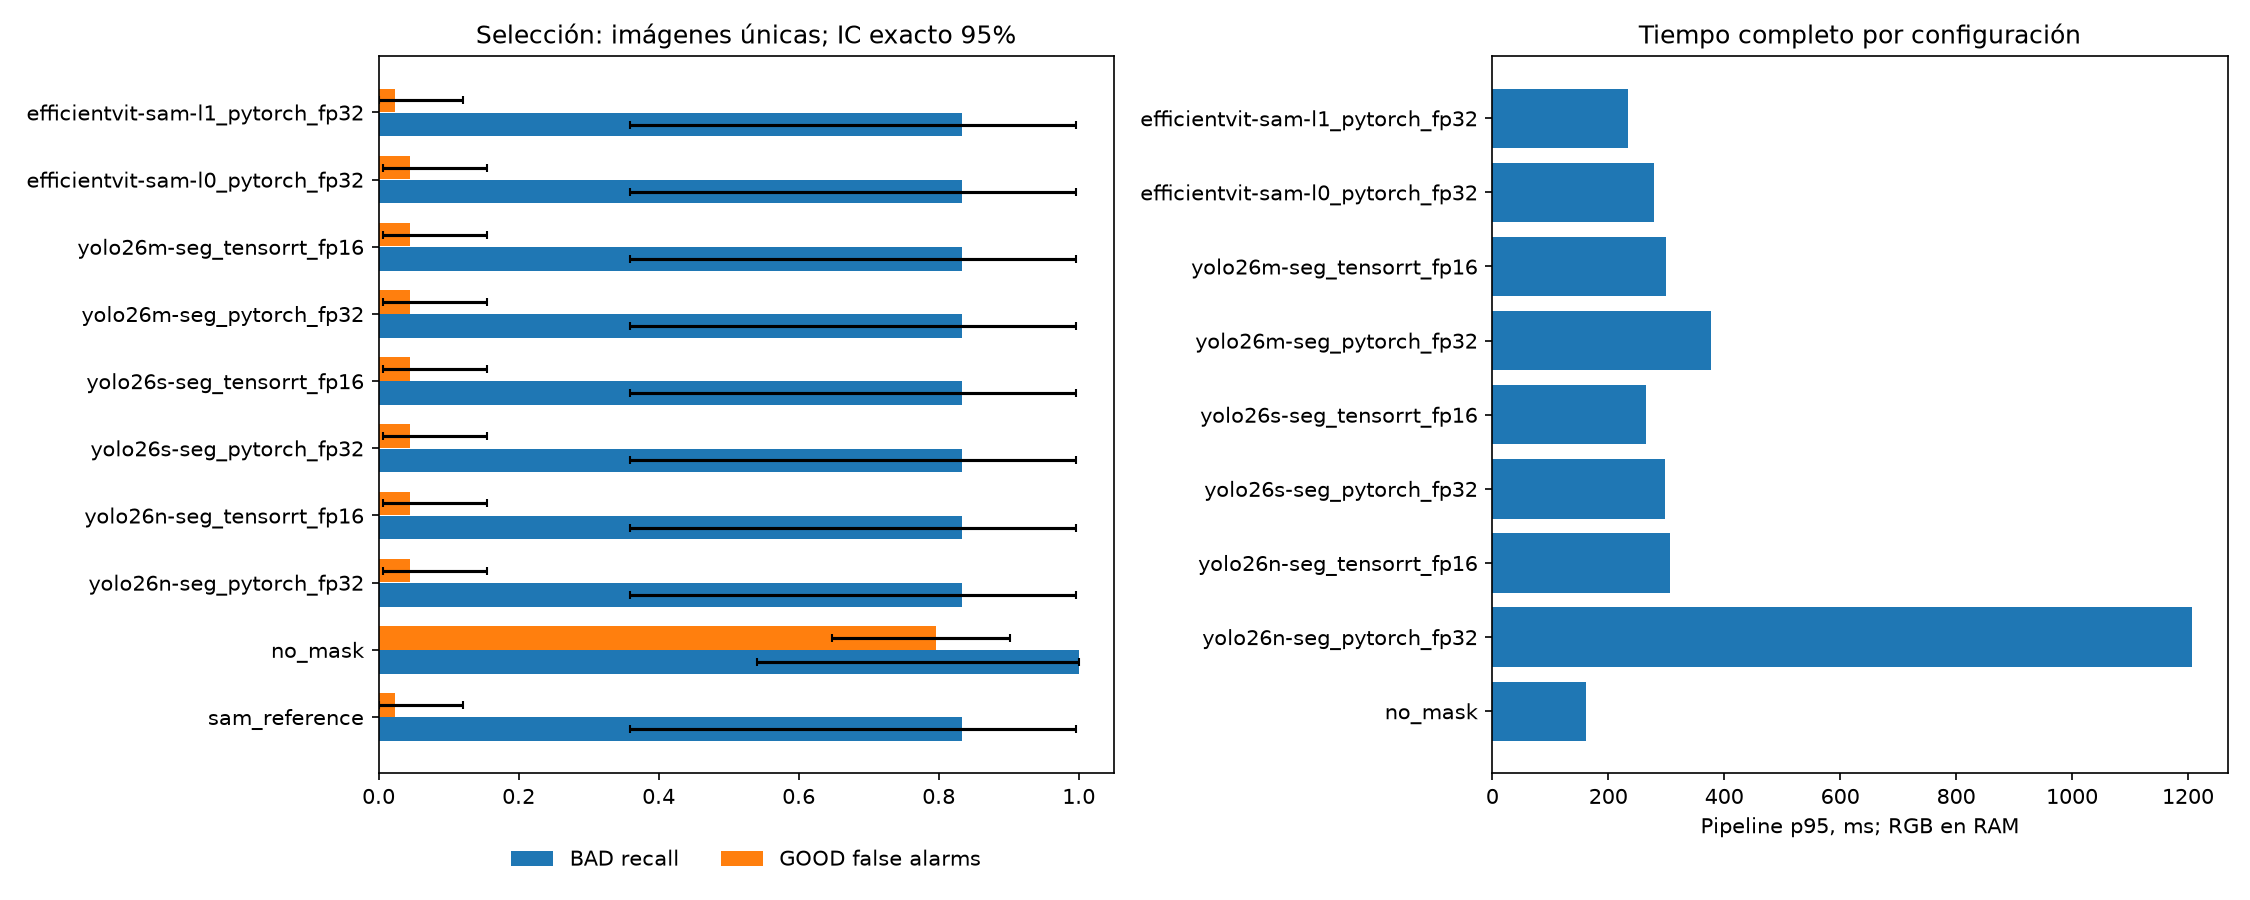

In [ ]:
# Exportación con outputs: un kernel nuevo no conserva ds_state del servidor.
# Mostrar el informe guardado de esta campaña sin cargar modelos ni iniciar tareas.
# En la sesión activa, rc_results_view ya presenta los resultados actuales.
mo.stop(ds_capture_mode or bool(ds_state.get("campaign")))
_snapshot = Path("reports/profiling/transistor_binary/sam_distillation/20261110T081240_360939Z/classification/CLASSIFICATION_REPORT.md")
mo.stop(not _snapshot.is_file())
mo.output.append(mo.md("## Resultados guardados de la campaña 20261110T081240_360939Z"))
mo.output.append(mo.md("Snapshot de resultados previos; esta exportación no vuelve a ejecutar entrenamientos ni benchmarks."))
_text = _snapshot.read_text(encoding="utf-8")
_text = _text.replace("![Comparación de clasificación](classification_comparison.png)", "").replace("![Máscaras y decisiones](test_bad_masks.png)", "")
mo.output.append(mo.md(_text))
# La galería completa se conserva en reports/; no incrustarla evita exceder el límite de salida.
for _filename in ["classification_comparison.png"]:
    _image = _snapshot.parent / _filename
    if _image.is_file():
        mo.output.append(mo.image(str(_image)))

In [ ]:
# R — Logs siempre visibles, sin controles ni reevaluaciones al refrescar.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
_tick=ds_live_tick.value
_progress=ds_state.get("classification_progress",{})
mo.output.append(mo.md("## Avance y logs de clasificación"))
if ds_campaign()["classification"].get("complete"):
    mo.output.append(mo.md("**Evaluación GOOD/BAD terminada. El reporte final aparece debajo.**"))
if _progress:
    _stage=_progress["stage"];_done=_progress["completed"];_total=_progress["total"]
    _active=ds_state.get("classification_log_stage")
    if _active and not _stage.startswith(_active):
        _stage=_active;_done=0;_total=0
    mo.output.append(mo.md(f"**{_stage}: {_done}/{_total}**" if _total else "**"+_stage+" — cargando recursos; log abajo**"))
    if _total:
        mo.output.append(mo.Html(f'<progress value="{_done}" max="{_total}" style="width:100%"></progress>'))
    _path=rc_directory()/"light_logs"/(_stage+".log")
    if _path.is_file():
        with _path.open("rb") as _stream:
            _stream.seek(max(0,_path.stat().st_size-500000))
            _text=_stream.read().decode("utf-8",errors="replace")
        mo.output.append(mo.Html('<pre style="height:420px;overflow:auto;white-space:pre-wrap">'+ds_html.escape(_text)+'</pre>'))
        mo.output.append(mo.download(lambda _p=_path:_p.read_bytes(),filename=_path.name,label="Log completo"))
_loss=rc_directory()/"effad"/"light_logs.csv"
if _loss.is_file():
    try:
        _frame=pd.read_csv(_loss)
        mo.output.append(mo.ui.altair_chart(ds_alt.Chart(_frame).mark_line().encode(x="step:Q",y="loss:Q").properties(height=220)))
    except (pd.errors.EmptyDataError,pd.errors.ParserError):
        pass
mo.output.append(mo.ui.table(pd.DataFrame([dict(stage=k,**v) for k,v in ds_campaign()["classification"]["stages"].items()])))

In [ ]:
# R — Salida de resultados: no requiere elegir opciones ni pulsar controles.
mo.stop(ds_capture_mode or not ds_state.get("campaign") or "classification" not in ds_campaign())
_tick=ds_live_tick.value
_state=ds_campaign()["classification"]
mo.output.append(mo.md("## Resultados GOOD/BAD del pipeline"))
_rows=[]
for _value in _state["evaluations"].values():
    _fusion=_value["arms"]["fusion"]
    _rows.append({"Configuración":_value["key"],"Split":_value["split"],
        "BAD detectados":str(_fusion["tp"])+"/"+str(_value["bad_images"]),
        "FN":_fusion["fn"],"FP/GOOD":str(_fusion["fp"])+"/"+str(_value["good_images"]),
        "Recall":round(_fusion["recall"],4),"FAR":round(_fusion["far"],4),
        "Recall DINO":round(_value["arms"]["dino"]["recall"],4),
        "Recall EffAD":round(_value["arms"]["effad"]["recall"],4),
        "Nuevos FN vs SAM":_value.get("new_fn_vs_sam"),
        "Pipeline mediana ms":round(_value["pipeline_ms_median"],2) if _value["pipeline_ms_median"] is not None else None,
        "Pipeline p95 ms":round(_value["pipeline_ms_p95"],2) if _value["pipeline_ms_p95"] is not None else None})
if _rows:
    mo.output.append(mo.Html('<div style="overflow:auto">'+pd.DataFrame(_rows).to_html(index=False,na_rep="—")+'</div>'))
else:
    mo.output.append(mo.md("Aún no se ha evaluado clasificación: se está preparando el downstream sin fuga."))
if _state.get("calibration"):
    mo.output.append(mo.md("**Alpha de la fusión:** "+str(_state["calibration"]["alpha"])+". El control sin máscara y los brazos separados permiten interpretar su efecto."))
if _state.get("report"):
    _report=Path(_state["report"])
    mo.output.append(mo.md(_report.read_text(encoding="utf-8").replace("![Comparación de clasificación](classification_comparison.png)","").replace("![Máscaras y decisiones](test_bad_masks.png)","")))
    _figure=_report.parent/"classification_comparison.png"
    if _figure.is_file(): mo.output.append(mo.image(str(_figure)))
    _bad_gallery=_report.parent/"test_bad_masks.png"
    if _bad_gallery.is_file(): mo.output.append(mo.image(str(_bad_gallery)))
    mo.output.append(mo.download(lambda _p=_report:_p.read_bytes(),filename=_report.name,label="Descargar reporte GOOD/BAD"))